<a href="https://colab.research.google.com/github/KeerthipriyaJupaka/Diabetic-Retinopathy-detection-using-Deep-learning-/blob/main/DL_project_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

DIABETIC RETINOPATHY DETECTION USING DEEP LEARNING

1.LIBRARIES AND ENVIRONMENT

In [ ]:
# ============================================================
# 1. LIBRARIES & ENVIRONMENT SETUP
# ============================================================

# TensorFlow
import tensorflow as tf

# OpenCV
import cv2

# Numerical operations
import numpy as np

# Data handling
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning utilities
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.utils.class_weight import compute_class_weight

# Image processing
from PIL import Image

# File handling
import os
import warnings
warnings.filterwarnings("ignore")

# ============================================================
# VERSION INFORMATION
# ============================================================

print("=" * 60)
print("ENVIRONMENT INFORMATION")
print("=" * 60)

print("TensorFlow version :", tf.__version__)
print("NumPy version      :", np.__version__)
print("OpenCV version     :", cv2.__version__)
print("Pandas version     :", pd.__version__)

# ============================================================
# GPU CHECK
# ============================================================

print("\n" + "=" * 60)
print("GPU CHECK")
print("=" * 60)

gpus = tf.config.list_physical_devices("GPU")

if gpus:
    print("✅ GPU detected!")
    for gpu in gpus:
        print("   ", gpu)
else:
    print("⚠️ GPU not detected.")
    print("   Training will run on CPU and may be slow.")

# ============================================================
# PROJECT CONFIGURATION
# ============================================================

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# IMPORTANT:
# Current dataset contains only 4 classes.
# Severe folder is empty, so DO NOT use 5 classes.
ACTIVE_CLASSES = [
    "No_DR",
    "Mild",
    "Moderate",
    "Proliferate_DR"
]

NUM_CLASSES = len(ACTIVE_CLASSES)

print("\n" + "=" * 60)
print("PROJECT CONFIGURATION")
print("=" * 60)

print("Image size :", IMG_SIZE)
print("Batch size :", BATCH_SIZE)
print("Classes    :", ACTIVE_CLASSES)
print("Num classes:", NUM_CLASSES)

print("\n✅ Environment setup completed successfully!")

ENVIRONMENT INFORMATION
TensorFlow version : 2.21.0
NumPy version      : 2.1.3
OpenCV version     : 5.0.0
Pandas version     : 2.2.3

GPU CHECK
⚠️ GPU not detected.
   Training will run on CPU and may be slow.

PROJECT CONFIGURATION
Image size : (224, 224)
Batch size : 32
Classes    : ['No_DR', 'Mild', 'Moderate', 'Proliferate_DR']
Num classes: 4

✅ Environment setup completed successfully!


2.GOOGLE DRIVE AND DATASET LOADING

In [ ]:
# ============================================================
# 2. GOOGLE DRIVE + DATASET LOADING
# ============================================================

from google.colab import drive
import os
import pandas as pd

# ------------------------------------------------------------
# MOUNT GOOGLE DRIVE
# ------------------------------------------------------------

drive.mount('/content/drive')

# ------------------------------------------------------------
# DATASET PATH
# ------------------------------------------------------------

dataset_path = "/content/drive/MyDrive/DL_project/archive (2)/Dataset"

print("=" * 70)
print("DATASET LOADING")
print("=" * 70)

print("Dataset path:")
print(dataset_path)

# Check dataset path
if not os.path.exists(dataset_path):
    raise FileNotFoundError(
        "\n❌ Dataset path not found!\n"
        "Please check the Google Drive path."
    )

print("\n✅ Dataset path found!")

# ------------------------------------------------------------
# ACTIVE CLASSES
# ------------------------------------------------------------

classes = [
    "No_DR",
    "Mild",
    "Moderate",
    "Proliferate_DR"
]

# ------------------------------------------------------------
# ALL IMAGE EXTENSIONS
# ------------------------------------------------------------

image_extensions = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
)

# ------------------------------------------------------------
# CHECK CLASS FOLDERS + COUNT IMAGES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASS FOLDER CHECK")
print("=" * 70)

image_paths = []
labels = []

class_counts = {}

for class_name in classes:

    class_folder = os.path.join(dataset_path, class_name)

    if not os.path.exists(class_folder):
        print(f"❌ {class_name}: Folder NOT FOUND")
        class_counts[class_name] = 0
        continue

    count = 0

    # Recursively search images
    for root, dirs, files in os.walk(class_folder):

        for file in files:

            if file.lower().endswith(image_extensions):

                full_path = os.path.join(root, file)

                image_paths.append(full_path)
                labels.append(class_name)

                count += 1

    class_counts[class_name] = count

    print(f"✅ {class_name:<18} : {count} images")

# ------------------------------------------------------------
# CHECK SEVERE FOLDER SEPARATELY
# ------------------------------------------------------------

severe_folder = os.path.join(dataset_path, "Severe")

print("\n" + "=" * 70)
print("SEVERE CLASS CHECK")
print("=" * 70)

if os.path.exists(severe_folder):

    severe_count = 0

    for root, dirs, files in os.walk(severe_folder):

        for file in files:

            if file.lower().endswith(image_extensions):
                severe_count += 1

    print(f"Severe folder found : {severe_count} images")

    if severe_count == 0:
        print("ℹ️ Severe folder is empty.")
        print("   Therefore the project uses 4 active classes.")

else:
    print("ℹ️ Severe folder does not exist.")
    print("   Therefore the project uses 4 active classes.")

# ------------------------------------------------------------
# CREATE DATAFRAME
# ------------------------------------------------------------

df = pd.DataFrame({
    "filepath": image_paths,
    "label": labels
})

# ------------------------------------------------------------
# DATASET SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATASET SUMMARY")
print("=" * 70)

print(f"Total images : {len(df)}")
print(f"Total classes: {df['label'].nunique()}")

print("\nImages per class:")

print(df["label"].value_counts().reindex(classes, fill_value=0))

# ------------------------------------------------------------
# CHECK FOR EMPTY DATASET
# ------------------------------------------------------------

if len(df) == 0:
    raise ValueError("❌ No images found in the dataset!")

# ------------------------------------------------------------
# CHECK IMAGE EXTENSIONS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("IMAGE EXTENSION CHECK")
print("=" * 70)

extension_counts = {}

for path in df["filepath"]:

    ext = os.path.splitext(path)[1].lower()

    extension_counts[ext] = extension_counts.get(ext, 0) + 1

for ext, count in sorted(extension_counts.items()):
    print(f"{ext:<10} : {count}")

# ------------------------------------------------------------
# DISPLAY FIRST FEW FILES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLE IMAGE PATHS")
print("=" * 70)

for path in df["filepath"].head(5):
    print(path)

# ------------------------------------------------------------
# FINAL CHECK
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL DATASET STATUS")
print("=" * 70)

print("✅ Google Drive mounted")
print("✅ Dataset path verified")
print("✅ Class folders checked")
print("✅ Image extensions checked")
print("✅ Images counted")
print("✅ DataFrame created")

print("\nActive classes:")
for i, class_name in enumerate(classes):
    print(f"{i} → {class_name}")

print("\n🎯 DATASET LOADING COMPLETED SUCCESSFULLY!")

Mounted at /content/drive
DATASET LOADING
Dataset path:
/content/drive/MyDrive/DL_project/archive (2)/Dataset

✅ Dataset path found!

CLASS FOLDER CHECK
✅ No_DR              : 968 images
✅ Mild               : 527 images
✅ Moderate           : 344 images
✅ Proliferate_DR     : 1089 images

SEVERE CLASS CHECK
Severe folder found : 0 images
ℹ️ Severe folder is empty.
   Therefore the project uses 4 active classes.

DATASET SUMMARY
Total images : 2928
Total classes: 4

Images per class:
label
No_DR              968
Mild               527
Moderate           344
Proliferate_DR    1089
Name: count, dtype: int64

IMAGE EXTENSION CHECK
.png       : 2928

SAMPLE IMAGE PATHS
/content/drive/MyDrive/DL_project/archive (2)/Dataset/No_DR/1509d097b69a.png
/content/drive/MyDrive/DL_project/archive (2)/Dataset/No_DR/165c548185f8.png
/content/drive/MyDrive/DL_project/archive (2)/Dataset/No_DR/0182152c50de.png
/content/drive/MyDrive/DL_project/archive (2)/Dataset/No_DR/0790515cf5af.png
/content/drive/MyD

DATASET VISUALIZATION

DATASET VISUALIZATION

Total images: 2928

Class Distribution:
label
No_DR              968
Mild               527
Moderate           344
Proliferate_DR    1089
Name: count, dtype: int64


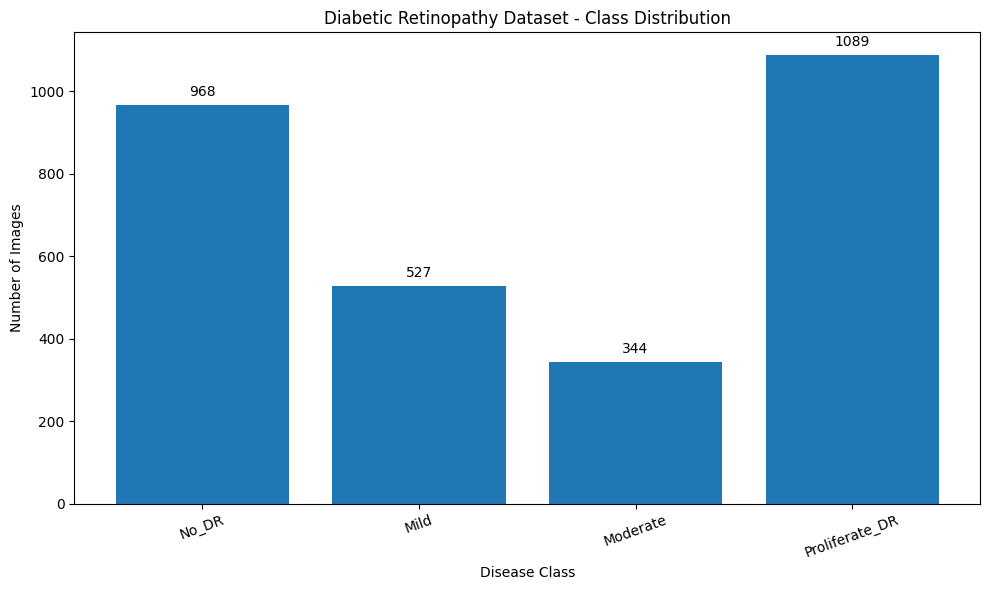


SAMPLE IMAGES


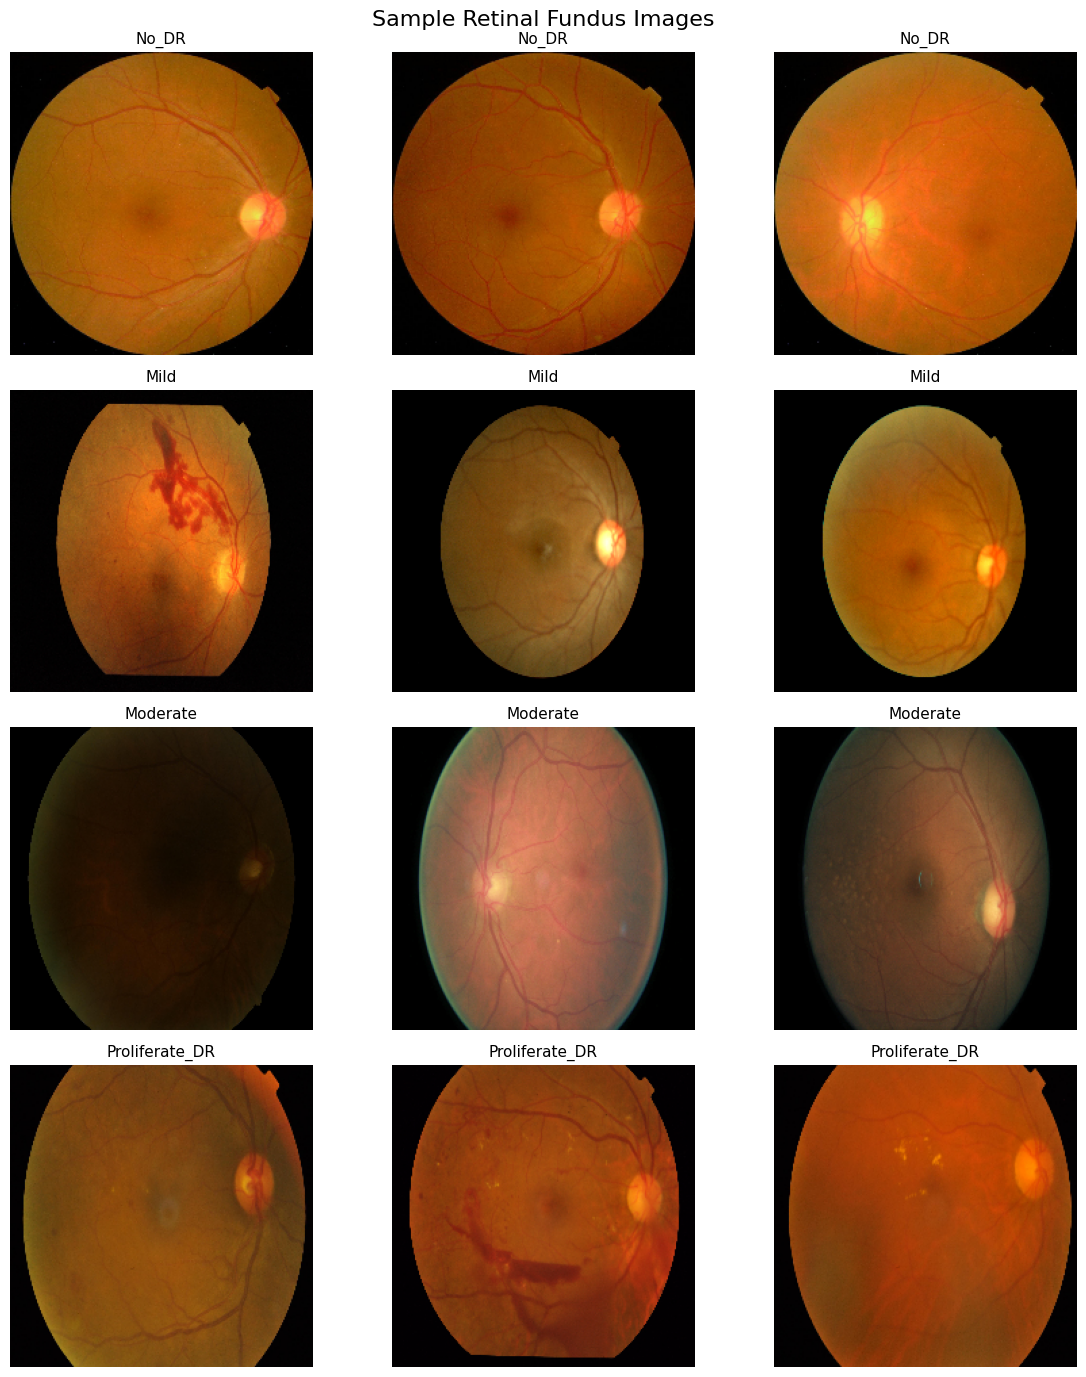


IMAGE DIMENSION CHECK

Unique image dimensions:
224 x 224 : 2928 images

Most common dimension: (224, 224)

Invalid/corrupted images: 0
✅ No corrupted images detected.

RANDOM IMAGE VERIFICATION
5dc23e440de3.png                    → (224, 224)
b92eacd1392a.png                    → (224, 224)
bb2f89488ecd.png                    → (224, 224)
0cae727cf119.png                    → (224, 224)
529906ff9dfa.png                    → (224, 224)

DATASET VISUALIZATION COMPLETED
Total images          : 2928
Number of classes     : 4
Invalid images        : 0

Class counts:
  No_DR              : 968
  Mild               : 527
  Moderate           : 344
  Proliferate_DR     : 1089

✅ Sample images displayed
✅ Class distribution graph displayed
✅ Image dimensions checked
✅ Dataset visualization completed successfully!


In [ ]:
# ============================================================
# 3. DATASET VISUALIZATION
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("=" * 70)
print("DATASET VISUALIZATION")
print("=" * 70)

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

# These should already exist from previous cell.
# Recreate them safely if needed.

dataset_path = "/content/drive/MyDrive/DL_project/archive (2)/Dataset"

classes = [
    "No_DR",
    "Mild",
    "Moderate",
    "Proliferate_DR"
]

image_extensions = (
    ".jpg", ".jpeg", ".png", ".bmp",
    ".tif", ".tiff", ".webp"
)

# ------------------------------------------------------------
# COLLECT IMAGES
# ------------------------------------------------------------

image_paths = []
labels = []

for class_name in classes:

    class_folder = os.path.join(dataset_path, class_name)

    if not os.path.exists(class_folder):
        continue

    for root, dirs, files in os.walk(class_folder):

        for file in files:

            if file.lower().endswith(image_extensions):

                image_paths.append(
                    os.path.join(root, file)
                )

                labels.append(class_name)

df = pd.DataFrame({
    "filepath": image_paths,
    "label": labels
})

print(f"\nTotal images: {len(df)}")

# ------------------------------------------------------------
# 1. CLASS DISTRIBUTION
# ------------------------------------------------------------

class_counts = (
    df["label"]
    .value_counts()
    .reindex(classes, fill_value=0)
)

print("\nClass Distribution:")
print(class_counts)

# ------------------------------------------------------------
# CLASS DISTRIBUTION GRAPH
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

bars = plt.bar(
    class_counts.index,
    class_counts.values
)

plt.title("Diabetic Retinopathy Dataset - Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=20)

# Display values on bars
for bar, value in zip(bars, class_counts.values):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + max(class_counts.values) * 0.02,
        str(value),
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2. SAMPLE IMAGES FROM EACH CLASS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLE IMAGES")
print("=" * 70)

samples_per_class = 3

fig, axes = plt.subplots(
    len(classes),
    samples_per_class,
    figsize=(12, 14)
)

# Handle single row/column safely
axes = np.array(axes).reshape(
    len(classes),
    samples_per_class
)

for row, class_name in enumerate(classes):

    class_images = df[
        df["label"] == class_name
    ]["filepath"].tolist()

    if len(class_images) == 0:

        for col in range(samples_per_class):

            axes[row, col].axis("off")

            if col == 0:
                axes[row, col].set_title(
                    f"{class_name}\nNo images"
                )

        continue

    # Random samples
    selected_images = random.sample(
        class_images,
        min(samples_per_class, len(class_images))
    )

    for col in range(samples_per_class):

        axes[row, col].axis("off")

        if col < len(selected_images):

            image_path = selected_images[col]

            try:

                image = Image.open(image_path).convert("RGB")

                axes[row, col].imshow(image)

                axes[row, col].set_title(
                    class_name,
                    fontsize=11
                )

            except Exception as e:

                axes[row, col].set_title(
                    "Image Error"
                )

plt.suptitle(
    "Sample Retinal Fundus Images",
    fontsize=16
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. IMAGE DIMENSION CHECK
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("IMAGE DIMENSION CHECK")
print("=" * 70)

dimension_counts = {}
invalid_images = []

# Check up to all images
for index, image_path in enumerate(df["filepath"]):

    try:

        with Image.open(image_path) as img:

            width, height = img.size

            dimension = (width, height)

            dimension_counts[dimension] = (
                dimension_counts.get(dimension, 0) + 1
            )

    except Exception:

        invalid_images.append(image_path)

# ------------------------------------------------------------
# DIMENSION SUMMARY
# ------------------------------------------------------------

print("\nUnique image dimensions:")

for dimension, count in sorted(
    dimension_counts.items(),
    key=lambda x: x[1],
    reverse=True
):

    print(
        f"{dimension[0]} x {dimension[1]} : "
        f"{count} images"
    )

# ------------------------------------------------------------
# MOST COMMON DIMENSION
# ------------------------------------------------------------

if dimension_counts:

    most_common_dimension = max(
        dimension_counts,
        key=dimension_counts.get
    )

    print(
        "\nMost common dimension:",
        most_common_dimension
    )

# ------------------------------------------------------------
# INVALID IMAGE CHECK
# ------------------------------------------------------------

print("\nInvalid/corrupted images:", len(invalid_images))

if invalid_images:

    print("\nFirst few invalid images:")

    for path in invalid_images[:10]:
        print(path)

else:

    print("✅ No corrupted images detected.")

# ------------------------------------------------------------
# 4. RANDOM IMAGE SIZE VERIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RANDOM IMAGE VERIFICATION")
print("=" * 70)

if len(df) > 0:

    verification_count = min(5, len(df))

    random_paths = random.sample(
        df["filepath"].tolist(),
        verification_count
    )

    for path in random_paths:

        try:

            with Image.open(path) as img:

                print(
                    f"{os.path.basename(path):<35} "
                    f"→ {img.size}"
                )

        except Exception:

            print(
                f"{os.path.basename(path):<35} "
                f"→ ERROR"
            )

# ------------------------------------------------------------
# FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATASET VISUALIZATION COMPLETED")
print("=" * 70)

print(f"Total images          : {len(df)}")
print(f"Number of classes     : {len(classes)}")
print(f"Invalid images        : {len(invalid_images)}")

print("\nClass counts:")

for class_name in classes:

    print(
        f"  {class_name:<18} : "
        f"{class_counts[class_name]}"
    )

print("\n✅ Sample images displayed")
print("✅ Class distribution graph displayed")
print("✅ Image dimensions checked")
print("✅ Dataset visualization completed successfully!")

DATA PREPROCESSING

DATA PREPROCESSING
Total images: 2928

1. IMAGE RESIZING
Original images are resized to: (224, 224)
Original size: (224, 224)
Resized size : (224, 224)

2. IMAGE NORMALIZATION

Pixel values are converted from:
0 - 255

to:

0 - 1

using:
pixel / 255.0


3. DATA AUGMENTATION

Applied augmentation:

✓ Rotation
✓ Width shift
✓ Height shift
✓ Zoom
✓ Horizontal flip
✓ Brightness variation


4. VALIDATION AND TEST PREPROCESSING
Validation/Test augmentation: OFF
Validation/Test preprocessing: ON

5. PREPROCESSING DEMONSTRATION
Image shape: (224, 224, 3)
Original pixel range: 0.0 to 255.0
Normalized pixel range: 0.0 to 1.0

6. AUGMENTATION VISUALIZATION


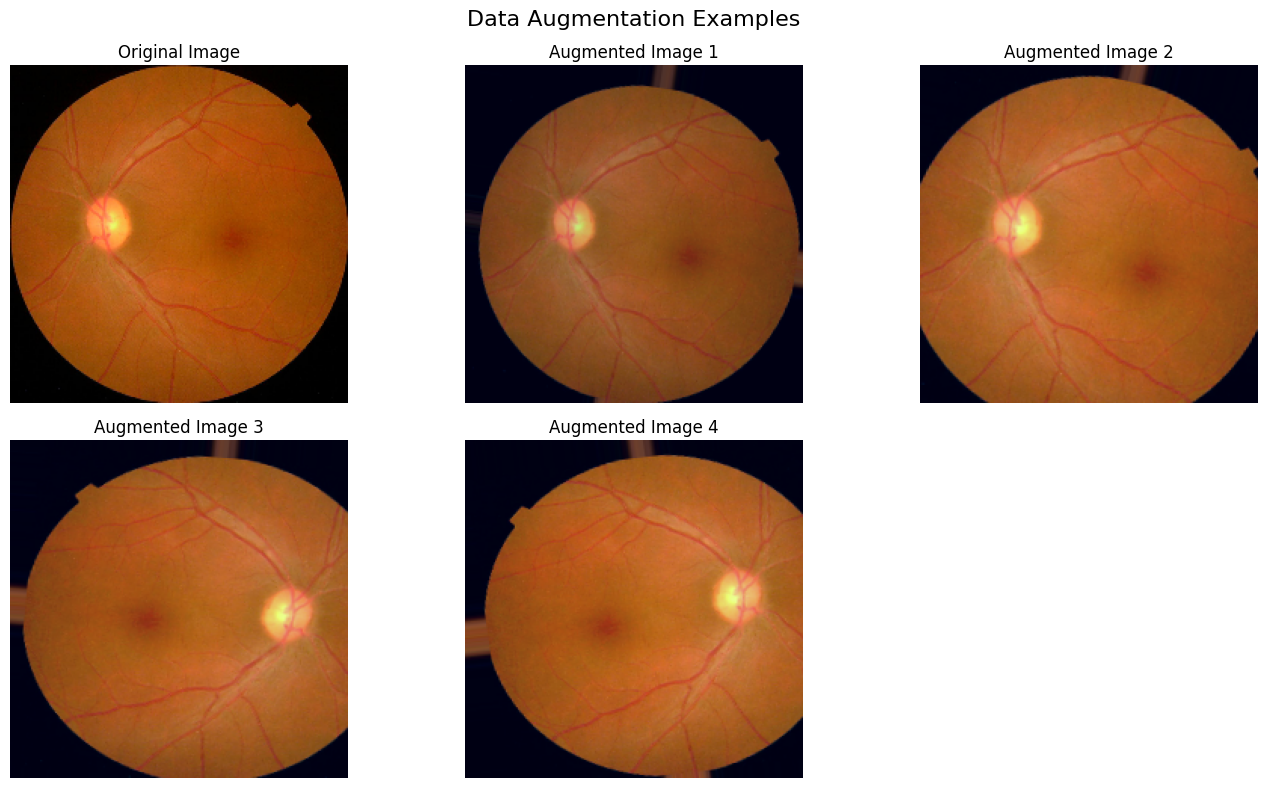


7. PREPROCESSING GENERATORS

Training:
  Resize       → 224 × 224
  Preprocessing → ImageNet preprocessing
  Augmentation → Enabled

Validation:
  Resize       → 224 × 224
  Preprocessing → ImageNet preprocessing
  Augmentation → Disabled

Testing:
  Resize       → 224 × 224
  Preprocessing → ImageNet preprocessing
  Augmentation → Disabled

DATA PREPROCESSING COMPLETED
✅ Resize: 224 × 224
✅ ImageNet preprocessing configured
✅ Rotation augmentation
✅ Width shift augmentation
✅ Height shift augmentation
✅ Zoom augmentation
✅ Horizontal flip augmentation
✅ Brightness augmentation
✅ Validation/Test augmentation disabled

🎯 PREPROCESSING SETUP COMPLETED SUCCESSFULLY!


In [ ]:
# ============================================================
# 4. DATA PREPROCESSING
# Resize + Normalization + Data Augmentation
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from tensorflow.keras.preprocessing.image import (
    ImageDataGenerator,
    load_img,
    img_to_array
)

print("=" * 70)
print("DATA PREPROCESSING")
print("=" * 70)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

dataset_path = "/content/drive/MyDrive/DL_project/archive (2)/Dataset"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

classes = [
    "No_DR",
    "Mild",
    "Moderate",
    "Proliferate_DR"
]

# ------------------------------------------------------------
# COLLECT DATASET
# ------------------------------------------------------------

image_extensions = (
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
)

image_paths = []
labels = []

for class_name in classes:

    class_folder = os.path.join(
        dataset_path,
        class_name
    )

    if not os.path.exists(class_folder):
        continue

    for root, dirs, files in os.walk(class_folder):

        for file in files:

            if file.lower().endswith(image_extensions):

                image_paths.append(
                    os.path.join(root, file)
                )

                labels.append(class_name)

df = pd.DataFrame({
    "filepath": image_paths,
    "label": labels
})

print(f"Total images: {len(df)}")

# ------------------------------------------------------------
# 1. IMAGE RESIZING
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("1. IMAGE RESIZING")
print("=" * 70)

print("Original images are resized to:", IMG_SIZE)

# Demonstrate resizing using one image
if len(df) > 0:

    sample_path = df.iloc[0]["filepath"]

    original_image = Image.open(
        sample_path
    ).convert("RGB")

    resized_image = original_image.resize(
        IMG_SIZE
    )

    print(
        "Original size:",
        original_image.size
    )

    print(
        "Resized size :",
        resized_image.size
    )

# ------------------------------------------------------------
# 2. NORMALIZATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("2. IMAGE NORMALIZATION")
print("=" * 70)

print("""
Pixel values are converted from:
0 - 255

to:

0 - 1

using:
pixel / 255.0
""")

# IMPORTANT:
# This preprocessing generator is for ResNet50.
# ResNet50 requires standard ImageNet preprocessing.

from tensorflow.keras.applications.resnet50 import (
    preprocess_input as resnet_preprocess
)

# ------------------------------------------------------------
# 3. TRAINING DATA AUGMENTATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("3. DATA AUGMENTATION")
print("=" * 70)

print("""
Applied augmentation:

✓ Rotation
✓ Width shift
✓ Height shift
✓ Zoom
✓ Horizontal flip
✓ Brightness variation
""")

train_datagen = ImageDataGenerator(

    # ResNet50 ImageNet preprocessing
    preprocessing_function=resnet_preprocess,

    # Rotation
    rotation_range=20,

    # Horizontal and vertical movement
    width_shift_range=0.10,
    height_shift_range=0.10,

    # Zoom
    zoom_range=0.15,

    # Horizontal flip
    horizontal_flip=True,

    # Brightness variation
    brightness_range=[0.80, 1.20],

    # Small shear variation
    shear_range=0.10,

    # Fill empty pixels created by transformations
    fill_mode="nearest"
)

# ------------------------------------------------------------
# 4. VALIDATION / TEST PREPROCESSING
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("4. VALIDATION AND TEST PREPROCESSING")
print("=" * 70)

# No augmentation for validation/test data.
# Only ImageNet preprocessing is applied.

test_datagen = ImageDataGenerator(
    preprocessing_function=resnet_preprocess
)

print("Validation/Test augmentation: OFF")
print("Validation/Test preprocessing: ON")

# ------------------------------------------------------------
# 5. PREPROCESSING DEMONSTRATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("5. PREPROCESSING DEMONSTRATION")
print("=" * 70)

if len(df) > 0:

    sample_path = df.iloc[0]["filepath"]

    # Load original image
    original = load_img(
        sample_path,
        target_size=IMG_SIZE
    )

    # Convert to array
    original_array = img_to_array(original)

    # Normalize for demonstration
    normalized_array = original_array / 255.0

    print(
        "Image shape:",
        original_array.shape
    )

    print(
        "Original pixel range:",
        original_array.min(),
        "to",
        original_array.max()
    )

    print(
        "Normalized pixel range:",
        normalized_array.min(),
        "to",
        normalized_array.max()
    )

# ------------------------------------------------------------
# 6. DISPLAY ORIGINAL VS AUGMENTED IMAGE
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("6. AUGMENTATION VISUALIZATION")
print("=" * 70)

if len(df) > 0:

    sample_path = df.iloc[0]["filepath"]

    # Load image
    sample_img = load_img(
        sample_path,
        target_size=IMG_SIZE
    )

    sample_array = img_to_array(
        sample_img
    )

    # Create batch
    sample_batch = np.expand_dims(
        sample_array,
        axis=0
    )

    # Generate augmented images
    augmented_images = []

    generator = train_datagen.flow(
        sample_batch,
        batch_size=1,
        shuffle=False
    )

    for i in range(4):

        augmented = next(generator)[0]

        # Convert approximately back for visualization
        # because ResNet preprocessing changes pixel values
        display_img = augmented.copy()

        # ResNet preprocessing:
        # RGB -> BGR and subtract ImageNet means.
        # Reverse approximately for visualization.
        display_img = display_img[..., ::-1]

        display_img += np.array(
            [103.939, 116.779, 123.68]
        )

        display_img = np.clip(
            display_img,
            0,
            255
        ) / 255.0

        augmented_images.append(
            display_img
        )

    # Plot
    plt.figure(figsize=(14, 8))

    # Original
    plt.subplot(2, 3, 1)

    plt.imshow(
        sample_array.astype("uint8")
    )

    plt.title("Original Image")
    plt.axis("off")

    # Augmented images
    for i, image in enumerate(
        augmented_images
    ):

        plt.subplot(
            2,
            3,
            i + 2
        )

        plt.imshow(image)

        plt.title(
            f"Augmented Image {i + 1}"
        )

        plt.axis("off")

    plt.suptitle(
        "Data Augmentation Examples",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 7. CREATE PREPROCESSING GENERATORS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("7. PREPROCESSING GENERATORS")
print("=" * 70)

# IMPORTANT:
# Generators will be connected to train/validation/test
# dataframes after stratified splitting.

print("""
Training:
  Resize       → 224 × 224
  Preprocessing → ImageNet preprocessing
  Augmentation → Enabled

Validation:
  Resize       → 224 × 224
  Preprocessing → ImageNet preprocessing
  Augmentation → Disabled

Testing:
  Resize       → 224 × 224
  Preprocessing → ImageNet preprocessing
  Augmentation → Disabled
""")

# ------------------------------------------------------------
# FINAL STATUS
# ------------------------------------------------------------

print("=" * 70)
print("DATA PREPROCESSING COMPLETED")
print("=" * 70)

print("✅ Resize: 224 × 224")
print("✅ ImageNet preprocessing configured")
print("✅ Rotation augmentation")
print("✅ Width shift augmentation")
print("✅ Height shift augmentation")
print("✅ Zoom augmentation")
print("✅ Horizontal flip augmentation")
print("✅ Brightness augmentation")
print("✅ Validation/Test augmentation disabled")
print("\n🎯 PREPROCESSING SETUP COMPLETED SUCCESSFULLY!")

TRAIN/VALIDATION/TEST SPLIT


In [ ]:
# ============================================================
# 5. TRAIN / VALIDATION / TEST SPLIT
# 70% TRAIN | 15% VALIDATION | 15% TEST
# Stratified Split | random_state=42
# ============================================================

import os
import pandas as pd
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet50 import preprocess_input

print("=" * 70)
print("TRAIN / VALIDATION / TEST SPLIT")
print("=" * 70)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

dataset_path = "/content/drive/MyDrive/DL_project/archive (2)/Dataset"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

ACTIVE_CLASSES = [
    "No_DR",
    "Mild",
    "Moderate",
    "Proliferate_DR"
]

image_extensions = (
    ".jpg", ".jpeg", ".png",
    ".bmp", ".tif", ".tiff", ".webp"
)

# ------------------------------------------------------------
# CREATE DATAFRAME
# ------------------------------------------------------------

image_paths = []
labels = []

for class_name in ACTIVE_CLASSES:

    class_folder = os.path.join(
        dataset_path,
        class_name
    )

    if not os.path.exists(class_folder):
        print(f"⚠️ Folder not found: {class_name}")
        continue

    for root, dirs, files in os.walk(class_folder):

        for file in files:

            if file.lower().endswith(image_extensions):

                image_paths.append(
                    os.path.join(root, file)
                )

                labels.append(class_name)

df = pd.DataFrame({
    "filepath": image_paths,
    "label": labels
})

print(f"\nTotal images: {len(df)}")

# ------------------------------------------------------------
# CHECK DATA
# ------------------------------------------------------------

if len(df) == 0:
    raise ValueError("❌ No images found!")

print("\nOriginal class distribution:")
print(
    df["label"]
    .value_counts()
    .reindex(ACTIVE_CLASSES, fill_value=0)
)

# ------------------------------------------------------------
# FIRST SPLIT
# 70% TRAIN
# 30% TEMP
# ------------------------------------------------------------

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

# ------------------------------------------------------------
# SECOND SPLIT
# TEMP 30% → 15% VALIDATION + 15% TEST
# ------------------------------------------------------------

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

# ------------------------------------------------------------
# RESET INDEX
# ------------------------------------------------------------

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# ------------------------------------------------------------
# SPLIT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SPLIT SUMMARY")
print("=" * 70)

print(
    f"Training   : {len(train_df)} images "
    f"({len(train_df) / len(df) * 100:.2f}%)"
)

print(
    f"Validation : {len(val_df)} images "
    f"({len(val_df) / len(df) * 100:.2f}%)"
)

print(
    f"Testing    : {len(test_df)} images "
    f"({len(test_df) / len(df) * 100:.2f}%)"
)

print(
    f"Total      : "
    f"{len(train_df) + len(val_df) + len(test_df)} images"
)

# ------------------------------------------------------------
# CLASS DISTRIBUTION AFTER SPLIT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASS DISTRIBUTION AFTER SPLIT")
print("=" * 70)

distribution_table = pd.DataFrame({
    "Train": train_df["label"]
        .value_counts()
        .reindex(ACTIVE_CLASSES, fill_value=0),

    "Validation": val_df["label"]
        .value_counts()
        .reindex(ACTIVE_CLASSES, fill_value=0),

    "Test": test_df["label"]
        .value_counts()
        .reindex(ACTIVE_CLASSES, fill_value=0)
})

print(distribution_table)

# ------------------------------------------------------------
# IMAGE DATA GENERATORS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CREATING IMAGE GENERATORS")
print("=" * 70)

# TRAINING:
# Augmentation enabled
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    width_shift_range=0.10,
    height_shift_range=0.10,
    zoom_range=0.15,
    horizontal_flip=True,
    brightness_range=[0.80, 1.20],
    shear_range=0.10,
    fill_mode="nearest"
)

# VALIDATION + TEST:
# No augmentation
val_test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# ------------------------------------------------------------
# TRAIN GENERATOR
# ------------------------------------------------------------

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="filepath",
    y_col="label",
    classes=ACTIVE_CLASSES,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

# ------------------------------------------------------------
# VALIDATION GENERATOR
# ------------------------------------------------------------

val_generator = val_test_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="filepath",
    y_col="label",
    classes=ACTIVE_CLASSES,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

# ------------------------------------------------------------
# TEST GENERATOR
# IMPORTANT: shuffle=False
# ------------------------------------------------------------

test_generator = val_test_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="filepath",
    y_col="label",
    classes=ACTIVE_CLASSES,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

# ------------------------------------------------------------
# CLASS INDICES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASS INDICES")
print("=" * 70)

print(train_generator.class_indices)

# ------------------------------------------------------------
# GENERATOR INFORMATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GENERATOR INFORMATION")
print("=" * 70)

print("Training batches   :", len(train_generator))
print("Validation batches :", len(val_generator))
print("Testing batches    :", len(test_generator))

print("\nTraining images   :", train_generator.samples)
print("Validation images :", val_generator.samples)
print("Testing images    :", test_generator.samples)

# ------------------------------------------------------------
# FINAL CHECK
# ------------------------------------------------------------

assert len(train_df) + len(val_df) + len(test_df) == len(df)

assert train_generator.class_indices == {
    "No_DR": 0,
    "Mild": 1,
    "Moderate": 2,
    "Proliferate_DR": 3
}

print("\n" + "=" * 70)
print("✅ SPLIT COMPLETED SUCCESSFULLY")
print("=" * 70)

print("""
70%  → Training
15%  → Validation
15%  → Testing

✓ Stratified split
✓ random_state = 42
✓ Training shuffle = True
✓ Validation shuffle = False
✓ Testing shuffle = False
✓ 4 active classes
✓ Generators created
""")

print("🎯 Ready for Image Quality Assessment + ResNet50 training!")

TRAIN / VALIDATION / TEST SPLIT

Total images: 2928

Original class distribution:
label
No_DR              968
Mild               527
Moderate           344
Proliferate_DR    1089
Name: count, dtype: int64

SPLIT SUMMARY
Training   : 2049 images (69.98%)
Validation : 439 images (14.99%)
Testing    : 440 images (15.03%)
Total      : 2928 images

CLASS DISTRIBUTION AFTER SPLIT
                Train  Validation  Test
label                                  
No_DR             677         145   146
Mild              369          79    79
Moderate          241          52    51
Proliferate_DR    762         163   164

CREATING IMAGE GENERATORS
Found 2049 validated image filenames belonging to 4 classes.
Found 439 validated image filenames belonging to 4 classes.
Found 440 validated image filenames belonging to 4 classes.

CLASS INDICES
{'No_DR': 0, 'Mild': 1, 'Moderate': 2, 'Proliferate_DR': 3}

GENERATOR INFORMATION
Training batches   : 65
Validation batches : 14
Testing batches    : 14

Tra

IMAGE QUALITY ASSESSMENT

IMAGE QUALITY ASSESSMENT (IQA)

IQA thresholds:
Blur threshold        : 80.0
Minimum brightness    : 30.0
Maximum brightness    : 220.0
Minimum retinal area  : 0.3
Quality threshold     : 60

TESTING IQA ON DATASET

IQA Results:
 blur_score blur_status  brightness brightness_status  retinal_visibility         retinal_status  contrast contrast_status  quality_score quality_label
     335.57       Sharp       70.91   Good brightness               78.39 Retinal region visible     38.77   Good contrast            100  GOOD QUALITY
     259.96       Sharp       73.31   Good brightness               78.55 Retinal region visible     39.49   Good contrast            100  GOOD QUALITY
     406.08       Sharp       88.14   Good brightness               78.29 Retinal region visible     49.91   Good contrast            100  GOOD QUALITY
     199.23       Sharp       66.68   Good brightness               83.21 Retinal region visible     30.72   Good contrast            100  GOOD QUALITY
     286.69

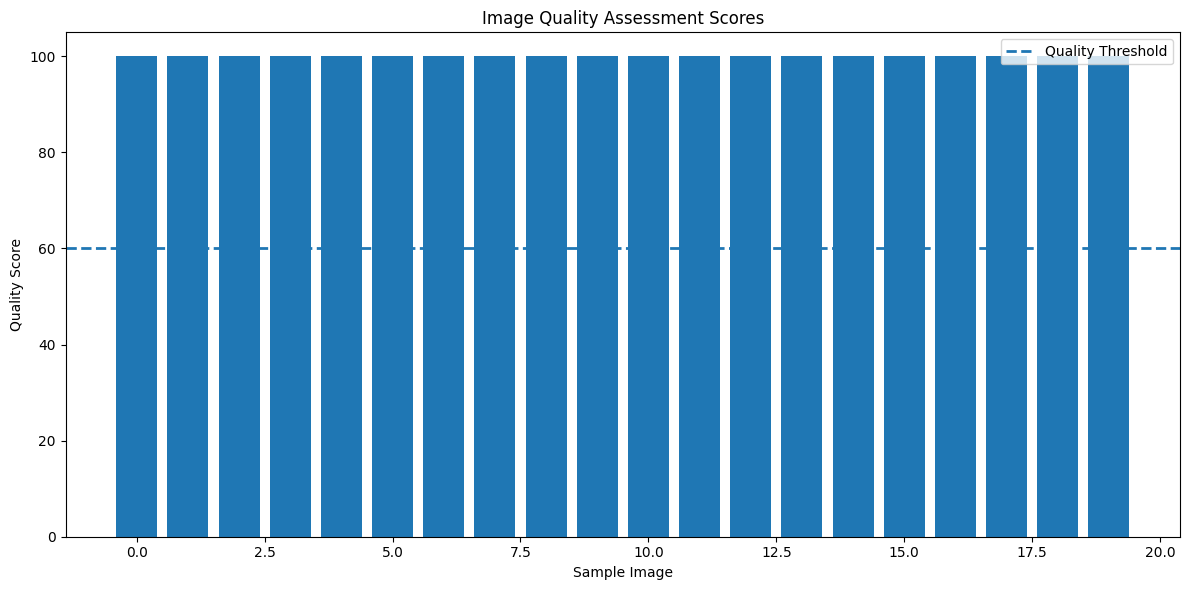


IQA VISUALIZATION


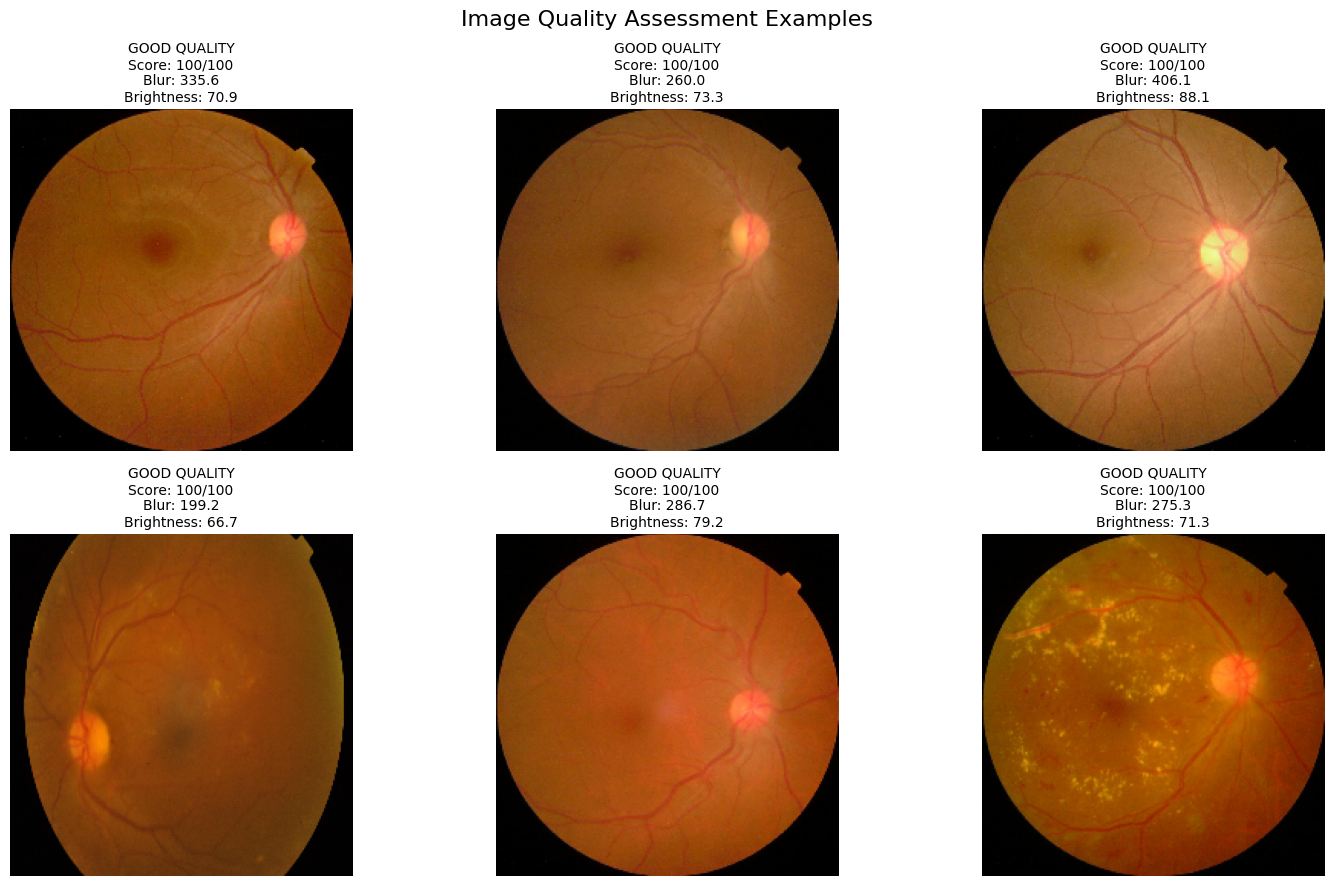


✅ IMAGE QUALITY ASSESSMENT COMPLETED

IQA Pipeline:

Fundus Image
      ↓
Blur Detection
      ↓
Brightness Check
      ↓
Retinal Visibility Check
      ↓
Contrast Check
      ↓
Quality Score
      ↓
GOOD / POOR QUALITY
      ↓
Good → Model Prediction
Poor → Request Better Image

🎯 IQA module is ready for the final prediction pipeline.


In [ ]:
# ============================================================
# 6. IMAGE QUALITY ASSESSMENT (IQA)
# ============================================================
# Checks:
# 1. Blur detection
# 2. Brightness check
# 3. Retinal visibility / field-of-view check
# 4. Quality score
# 5. Good / Poor classification
# 6. Visualization
# ============================================================

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from PIL import Image

print("=" * 70)
print("IMAGE QUALITY ASSESSMENT (IQA)")
print("=" * 70)

# ------------------------------------------------------------
# CONFIGURATION
# ------------------------------------------------------------

BLUR_THRESHOLD = 80.0

MIN_BRIGHTNESS = 30.0
MAX_BRIGHTNESS = 220.0

MIN_RETINAL_RATIO = 0.30

QUALITY_THRESHOLD = 60

print("\nIQA thresholds:")
print(f"Blur threshold        : {BLUR_THRESHOLD}")
print(f"Minimum brightness    : {MIN_BRIGHTNESS}")
print(f"Maximum brightness    : {MAX_BRIGHTNESS}")
print(f"Minimum retinal area  : {MIN_RETINAL_RATIO}")
print(f"Quality threshold     : {QUALITY_THRESHOLD}")

# ============================================================
# 1. LOAD IMAGE
# ============================================================

def load_iqa_image(image_path):

    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(
            f"Unable to read image: {image_path}"
        )

    # OpenCV BGR → RGB
    rgb = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    return image, rgb


# ============================================================
# 2. BLUR DETECTION
# ============================================================

def calculate_blur_score(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    # Variance of Laplacian
    blur_score = cv2.Laplacian(
        gray,
        cv2.CV_64F
    ).var()

    return float(blur_score)


def check_blur(blur_score):

    if blur_score >= BLUR_THRESHOLD:
        return True, "Sharp"

    return False, "Blurred"


# ============================================================
# 3. BRIGHTNESS CHECK
# ============================================================

def calculate_brightness(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    brightness = np.mean(gray)

    return float(brightness)


def check_brightness(brightness):

    if MIN_BRIGHTNESS <= brightness <= MAX_BRIGHTNESS:

        return True, "Good brightness"

    elif brightness < MIN_BRIGHTNESS:

        return False, "Too dark"

    else:

        return False, "Too bright"


# ============================================================
# 4. RETINAL VISIBILITY / FIELD-OF-VIEW CHECK
# ============================================================

def calculate_retinal_visibility(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    # Blur slightly to remove tiny noise
    gray_blur = cv2.GaussianBlur(
        gray,
        (5, 5),
        0
    )

    # Otsu threshold
    _, threshold = cv2.threshold(
        gray_blur,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Calculate non-black / visible region
    visible_pixels = np.sum(
        threshold > 0
    )

    total_pixels = threshold.size

    visibility_ratio = (
        visible_pixels /
        total_pixels
    )

    return float(visibility_ratio)


def check_retinal_visibility(
    visibility_ratio
):

    if visibility_ratio >= MIN_RETINAL_RATIO:

        return True, "Retinal region visible"

    return False, "Low retinal visibility"


# ============================================================
# 5. CONTRAST CHECK
# ============================================================

def calculate_contrast(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    contrast = np.std(gray)

    return float(contrast)


def check_contrast(contrast):

    if contrast >= 20:

        return True, "Good contrast"

    return False, "Low contrast"


# ============================================================
# 6. OVERALL IQA FUNCTION
# ============================================================

def assess_image_quality(image_path):

    try:

        image, rgb = load_iqa_image(
            image_path
        )

        # ----------------------------------------
        # Blur
        # ----------------------------------------

        blur_score = calculate_blur_score(
            image
        )

        blur_ok, blur_status = check_blur(
            blur_score
        )

        # ----------------------------------------
        # Brightness
        # ----------------------------------------

        brightness = calculate_brightness(
            image
        )

        brightness_ok, brightness_status = (
            check_brightness(brightness)
        )

        # ----------------------------------------
        # Retinal visibility
        # ----------------------------------------

        retinal_ratio = (
            calculate_retinal_visibility(
                image
            )
        )

        retinal_ok, retinal_status = (
            check_retinal_visibility(
                retinal_ratio
            )
        )

        # ----------------------------------------
        # Contrast
        # ----------------------------------------

        contrast = calculate_contrast(
            image
        )

        contrast_ok, contrast_status = (
            check_contrast(contrast)
        )

        # ----------------------------------------
        # QUALITY SCORE
        # ----------------------------------------
        # Four quality components:
        #
        # Sharpness      = 25 points
        # Brightness     = 25 points
        # Visibility     = 25 points
        # Contrast       = 25 points
        # ----------------------------------------

        quality_score = 0

        if blur_ok:
            quality_score += 25

        if brightness_ok:
            quality_score += 25

        if retinal_ok:
            quality_score += 25

        if contrast_ok:
            quality_score += 25

        # ----------------------------------------
        # FINAL DECISION
        # ----------------------------------------

        if quality_score >= QUALITY_THRESHOLD:

            quality_label = "GOOD QUALITY"

        else:

            quality_label = "POOR QUALITY"

        # ----------------------------------------
        # RESULT
        # ----------------------------------------

        result = {

            "image_path": image_path,

            "blur_score": round(
                blur_score,
                2
            ),

            "blur_status": blur_status,

            "brightness": round(
                brightness,
                2
            ),

            "brightness_status":
                brightness_status,

            "retinal_visibility":
                round(
                    retinal_ratio * 100,
                    2
                ),

            "retinal_status":
                retinal_status,

            "contrast": round(
                contrast,
                2
            ),

            "contrast_status":
                contrast_status,

            "quality_score":
                quality_score,

            "quality_label":
                quality_label
        }

        return result

    except Exception as e:

        return {

            "image_path": image_path,

            "blur_score": 0,

            "blur_status": "Error",

            "brightness": 0,

            "brightness_status": "Error",

            "retinal_visibility": 0,

            "retinal_status": "Error",

            "contrast": 0,

            "contrast_status": "Error",

            "quality_score": 0,

            "quality_label": "POOR QUALITY",

            "error": str(e)
        }


# ============================================================
# 7. TEST ON DATASET SAMPLE
# ============================================================

print("\n" + "=" * 70)
print("TESTING IQA ON DATASET")
print("=" * 70)

# Use test_df if it already exists.
# Otherwise use df.

if "test_df" in globals() and len(test_df) > 0:

    iqa_test_df = test_df.copy()

elif "df" in globals() and len(df) > 0:

    iqa_test_df = df.sample(
        min(20, len(df)),
        random_state=42
    )

else:

    raise ValueError(
        "❌ Dataset dataframe not found."
    )


# Analyze sample images
sample_paths = iqa_test_df[
    "filepath"
].head(20).tolist()

iqa_results = []

for image_path in sample_paths:

    result = assess_image_quality(
        image_path
    )

    iqa_results.append(result)


iqa_results_df = pd.DataFrame(
    iqa_results
)

# ============================================================
# 8. DISPLAY IQA RESULTS
# ============================================================

print("\nIQA Results:")

display_columns = [

    "blur_score",
    "blur_status",

    "brightness",
    "brightness_status",

    "retinal_visibility",
    "retinal_status",

    "contrast",
    "contrast_status",

    "quality_score",
    "quality_label"
]

print(
    iqa_results_df[
        display_columns
    ].to_string(index=False)
)

# ============================================================
# 9. GOOD / POOR QUALITY SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("QUALITY SUMMARY")
print("=" * 70)

good_count = np.sum(
    iqa_results_df["quality_label"]
    == "GOOD QUALITY"
)

poor_count = np.sum(
    iqa_results_df["quality_label"]
    == "POOR QUALITY"
)

total_count = len(
    iqa_results_df
)

print(
    f"Good quality images : {good_count}"
)

print(
    f"Poor quality images : {poor_count}"
)

print(
    f"Total analyzed      : {total_count}"
)

if total_count > 0:

    print(
        f"Good quality %      : "
        f"{good_count / total_count * 100:.2f}%"
    )

    print(
        f"Poor quality %      : "
        f"{poor_count / total_count * 100:.2f}%"
    )


# ============================================================
# 10. QUALITY SCORE GRAPH
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    range(len(iqa_results_df)),
    iqa_results_df["quality_score"]
)

plt.axhline(
    QUALITY_THRESHOLD,
    linestyle="--",
    linewidth=2,
    label="Quality Threshold"
)

plt.xlabel("Sample Image")
plt.ylabel("Quality Score")
plt.title(
    "Image Quality Assessment Scores"
)

plt.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 11. DISPLAY SAMPLE IQA IMAGES
# ============================================================

print("\n" + "=" * 70)
print("IQA VISUALIZATION")
print("=" * 70)

visual_count = min(
    6,
    len(iqa_results_df)
)

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 9)
)

axes = axes.flatten()

for i in range(visual_count):

    path = iqa_results_df.iloc[i][
        "image_path"
    ]

    result = iqa_results_df.iloc[i]

    image = cv2.imread(path)

    image = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    axes[i].imshow(image)

    axes[i].set_title(
        f"{result['quality_label']}\n"
        f"Score: {result['quality_score']}/100\n"
        f"Blur: {result['blur_score']:.1f}\n"
        f"Brightness: {result['brightness']:.1f}",
        fontsize=10
    )

    axes[i].axis("off")


# Hide unused plots
for i in range(
    visual_count,
    len(axes)
):

    axes[i].axis("off")


plt.suptitle(
    "Image Quality Assessment Examples",
    fontsize=16
)

plt.tight_layout()
plt.show()


# ============================================================
# 12. SINGLE IMAGE IQA FUNCTION
# ============================================================
# This function will be used later in the FINAL
# prediction system before the deep-learning model.
# ============================================================

def run_iqa(image_path):

    result = assess_image_quality(
        image_path
    )

    print("\n" + "=" * 60)
    print("IMAGE QUALITY REPORT")
    print("=" * 60)

    print(
        f"Blur score          : "
        f"{result['blur_score']}"
    )

    print(
        f"Blur status         : "
        f"{result['blur_status']}"
    )

    print(
        f"Brightness          : "
        f"{result['brightness']}"
    )

    print(
        f"Brightness status   : "
        f"{result['brightness_status']}"
    )

    print(
        f"Retinal visibility  : "
        f"{result['retinal_visibility']}%"
    )

    print(
        f"Retinal status      : "
        f"{result['retinal_status']}"
    )

    print(
        f"Contrast            : "
        f"{result['contrast']}"
    )

    print(
        f"Contrast status     : "
        f"{result['contrast_status']}"
    )

    print(
        f"Quality score       : "
        f"{result['quality_score']}/100"
    )

    print(
        f"Final quality       : "
        f"{result['quality_label']}"
    )

    print("=" * 60)

    if result["quality_label"] == "GOOD QUALITY":

        print(
            "✅ Image quality is acceptable "
            "for model processing."
        )

    else:

        print(
            "⚠️ Poor image quality detected."
        )

        print(
            "Recommendation: "
            "Capture/upload a clearer fundus image."
        )

    return result


# ============================================================
# FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("✅ IMAGE QUALITY ASSESSMENT COMPLETED")
print("=" * 70)

print("""
IQA Pipeline:

Fundus Image
      ↓
Blur Detection
      ↓
Brightness Check
      ↓
Retinal Visibility Check
      ↓
Contrast Check
      ↓
Quality Score
      ↓
GOOD / POOR QUALITY
      ↓
Good → Model Prediction
Poor → Request Better Image
""")

print("🎯 IQA module is ready for the final prediction pipeline.")

# ***Grad-CAM***

In [ ]:
print("MODEL INPUT:")
print(efficientnet_model.input)

print("\nMODEL OUTPUT:")
print(efficientnet_model.output)

print("\nLAYERS:")
for i, layer in enumerate(efficientnet_model.layers):
    print(i, layer.name, type(layer).__name__)

MODEL INPUT:
<KerasTensor shape=(None, 224, 224, 3), dtype=float32, sparse=False, ragged=False, name=input_layer_4>

MODEL OUTPUT:
<KerasTensor shape=(None, 4), dtype=float32, sparse=False, ragged=False, name=keras_tensor_1751>

LAYERS:
0 input_layer_4 InputLayer
1 efficientnetb0 Functional
2 global_average_pooling2d GlobalAveragePooling2D
3 dropout Dropout
4 dense Dense
5 dropout_1 Dropout
6 dense_1 Dense


In [ ]:
# EXACT EFFICIENTNET STRUCTURE

base = efficientnet_model.get_layer("efficientnetb0")

print("BASE MODEL")
print("Name:", base.name)
print("Input:", base.input_shape)
print("Output:", base.output_shape)
print("Weights:", len(base.get_weights()))

print("\nLAST 20 BASE LAYERS:")
for i, layer in enumerate(base.layers[-20:]):
    print(
        len(base.layers) - 20 + i,
        layer.name,
        type(layer).__name__,
        getattr(layer, "output_shape", "shape unavailable")
    )

BASE MODEL
Name: efficientnetb0
Input: (None, 224, 224, 3)
Output: (None, 7, 7, 1280)
Weights: 312

LAST 20 BASE LAYERS:
218 block6d_project_conv Conv2D shape unavailable
219 block6d_project_bn BatchNormalization shape unavailable
220 block6d_drop Dropout shape unavailable
221 block6d_add Add shape unavailable
222 block7a_expand_conv Conv2D shape unavailable
223 block7a_expand_bn BatchNormalization shape unavailable
224 block7a_expand_activation Activation shape unavailable
225 block7a_dwconv DepthwiseConv2D shape unavailable
226 block7a_bn BatchNormalization shape unavailable
227 block7a_activation Activation shape unavailable
228 block7a_se_squeeze GlobalAveragePooling2D shape unavailable
229 block7a_se_reshape Reshape shape unavailable
230 block7a_se_reduce Conv2D shape unavailable
231 block7a_se_expand Conv2D shape unavailable
232 block7a_se_excite Multiply shape unavailable
233 block7a_project_conv Conv2D shape unavailable
234 block7a_project_bn BatchNormalization shape unavailabl

***Model Comparison***

              MODEL COMPARISON
          ResNet50 vs EfficientNetB0

Test samples: 440
Number of classes: 4

Generating ResNet50 predictions...
14/14 ━━━━━━━━━━━━━━━━━━━━ 95s 7s/step

Generating EfficientNetB0 predictions...
14/14 ━━━━━━━━━━━━━━━━━━━━ 38s 3s/step


                 MODEL COMPARISON TABLE


,Model,Accuracy,Precision,Recall,F1-Score
0,ResNet50,93.41%,94.15%,93.41%,93.59%
1,EfficientNetB0,96.14%,96.18%,96.14%,96.13%



Actual Metric Values:
----------------------------------------------------------------------

ResNet50
Accuracy  : 93.41%
Precision : 94.15%
Recall    : 93.41%
F1-Score  : 93.59%

EfficientNetB0
Accuracy  : 96.14%
Precision : 96.18%
Recall    : 96.14%
F1-Score  : 96.13%


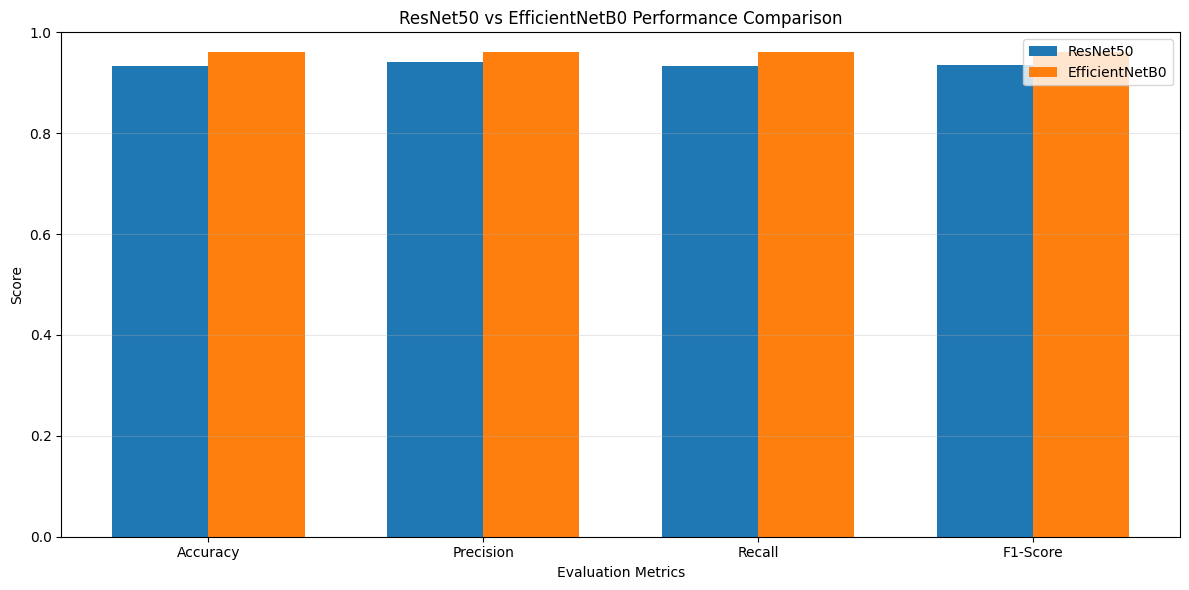


Best Model based on Weighted F1-Score: EfficientNetB0
F1-Score: 96.13%

Comparison results saved to:
/content/model_comparison.csv

Model comparison completed successfully.


In [ ]:
# ============================================================
# 15. MODEL COMPARISON - RESNET50 vs EFFICIENTNETB0
# COMPLETE CODE IN ONE CELL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("=" * 70)
print("              MODEL COMPARISON")
print("          ResNet50 vs EfficientNetB0")
print("=" * 70)


# ============================================================
# 1. CHECK REQUIRED MODELS / GENERATORS
# ============================================================

if "resnet50_model" not in globals():
    raise ValueError(
        "resnet50_model not found. "
        "Run the ResNet50 training cell first."
    )

if "efficientnet_model" not in globals():
    raise ValueError(
        "efficientnet_model not found. "
        "Run the EfficientNetB0 training cell first."
    )

if "test_generator" not in globals():
    raise ValueError(
        "test_generator not found. "
        "Run the dataset/generator cell first."
    )


# ============================================================
# 2. RESET TEST GENERATOR
# ============================================================

test_generator.reset()

print("\nTest samples:", test_generator.samples)


# ============================================================
# 3. TRUE LABELS
# ============================================================

true_labels = test_generator.classes

class_names = [
    "No_DR",
    "Mild",
    "Moderate",
    "Proliferate_DR"
]

print(
    "Number of classes:",
    len(class_names)
)


# ============================================================
# 4. RESNET50 PREDICTIONS
# ============================================================

print("\nGenerating ResNet50 predictions...")

test_generator.reset()

resnet_probabilities = resnet50_model.predict(
    test_generator,
    verbose=1
)

resnet_predictions = np.argmax(
    resnet_probabilities,
    axis=1
)


# ============================================================
# 5. EFFICIENTNETB0 PREDICTIONS
# ============================================================

print("\nGenerating EfficientNetB0 predictions...")

# Use EfficientNet-specific generator if available.
# Otherwise use the normal test generator.

if "test_generator_eff" in globals():

    test_generator_eff.reset()

    efficientnet_probabilities = (
        efficientnet_model.predict(
            test_generator_eff,
            verbose=1
        )
    )

    efficientnet_true_labels = (
        test_generator_eff.classes
    )

else:

    test_generator.reset()

    efficientnet_probabilities = (
        efficientnet_model.predict(
            test_generator,
            verbose=1
        )
    )

    efficientnet_true_labels = true_labels


efficientnet_predictions = np.argmax(
    efficientnet_probabilities,
    axis=1
)


# ============================================================
# 6. CALCULATE RESNET50 METRICS
# ============================================================

resnet_accuracy = accuracy_score(
    true_labels,
    resnet_predictions
)

resnet_precision = precision_score(
    true_labels,
    resnet_predictions,
    average="weighted",
    zero_division=0
)

resnet_recall = recall_score(
    true_labels,
    resnet_predictions,
    average="weighted",
    zero_division=0
)

resnet_f1 = f1_score(
    true_labels,
    resnet_predictions,
    average="weighted",
    zero_division=0
)


# ============================================================
# 7. CALCULATE EFFICIENTNETB0 METRICS
# ============================================================

efficientnet_accuracy = accuracy_score(
    efficientnet_true_labels,
    efficientnet_predictions
)

efficientnet_precision = precision_score(
    efficientnet_true_labels,
    efficientnet_predictions,
    average="weighted",
    zero_division=0
)

efficientnet_recall = recall_score(
    efficientnet_true_labels,
    efficientnet_predictions,
    average="weighted",
    zero_division=0
)

efficientnet_f1 = f1_score(
    efficientnet_true_labels,
    efficientnet_predictions,
    average="weighted",
    zero_division=0
)


# ============================================================
# 8. CREATE COMPARISON TABLE
# ============================================================

comparison_df = pd.DataFrame({

    "Model": [
        "ResNet50",
        "EfficientNetB0"
    ],

    "Accuracy": [
        resnet_accuracy,
        efficientnet_accuracy
    ],

    "Precision": [
        resnet_precision,
        efficientnet_precision
    ],

    "Recall": [
        resnet_recall,
        efficientnet_recall
    ],

    "F1-Score": [
        resnet_f1,
        efficientnet_f1
    ]
})


# ============================================================
# 9. DISPLAY PERCENTAGES
# ============================================================

display_df = comparison_df.copy()

for column in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]:

    display_df[column] = (
        display_df[column] * 100
    ).round(2).astype(str) + "%"


print("\n")
print("=" * 70)
print("                 MODEL COMPARISON TABLE")
print("=" * 70)

display(display_df)


# ============================================================
# 10. PRINT EXACT VALUES
# ============================================================

print("\nActual Metric Values:")
print("-" * 70)

for _, row in comparison_df.iterrows():

    print(
        f"\n{row['Model']}"
    )

    print(
        f"Accuracy  : {row['Accuracy'] * 100:.2f}%"
    )

    print(
        f"Precision : {row['Precision'] * 100:.2f}%"
    )

    print(
        f"Recall    : {row['Recall'] * 100:.2f}%"
    )

    print(
        f"F1-Score  : {row['F1-Score'] * 100:.2f}%"
    )


# ============================================================
# 11. BAR GRAPH
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

x = np.arange(
    len(metrics)
)

width = 0.35


plt.figure(
    figsize=(12, 6)
)

plt.bar(
    x - width / 2,
    comparison_df.iloc[0][metrics],
    width,
    label="ResNet50"
)

plt.bar(
    x + width / 2,
    comparison_df.iloc[1][metrics],
    width,
    label="EfficientNetB0"
)


plt.xticks(
    x,
    metrics
)

plt.ylabel(
    "Score"
)

plt.xlabel(
    "Evaluation Metrics"
)

plt.title(
    "ResNet50 vs EfficientNetB0 Performance Comparison"
)

plt.ylim(
    0,
    1.0
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 12. BEST MODEL
# ============================================================

f1_scores = {
    "ResNet50": resnet_f1,
    "EfficientNetB0": efficientnet_f1
}

best_model_name = max(
    f1_scores,
    key=f1_scores.get
)

print("\n" + "=" * 70)

print(
    "Best Model based on Weighted F1-Score:",
    best_model_name
)

print(
    f"F1-Score: {f1_scores[best_model_name] * 100:.2f}%"
)

print("=" * 70)


# ============================================================
# 13. SAVE COMPARISON RESULTS
# ============================================================

comparison_df.to_csv(
    "/content/model_comparison.csv",
    index=False
)

print(
    "\nComparison results saved to:"
)

print(
    "/content/model_comparison.csv"
)

print("\nModel comparison completed successfully.")

# ***Model 3: VGG16***

Found 2049 validated image filenames belonging to 4 classes.
Found 439 validated image filenames belonging to 4 classes.
Found 440 validated image filenames belonging to 4 classes.
Epoch 1/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 12s/step - accuracy: 0.3478 - loss: 5.6797 
Epoch 1: val_loss improved from None to 0.55011, saving model to /content/dr_models/vgg16_fast_best.keras

Epoch 1: finished saving model to /content/dr_models/vgg16_fast_best.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 921s 14s/step - accuracy: 0.3963 - loss: 4.7939 - val_accuracy: 0.8018 - val_loss: 0.5501
Epoch 2/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 12s/step - accuracy: 0.5430 - loss: 2.6769 
Epoch 2: val_loss improved from 0.55011 to 0.23185, saving model to /content/dr_models/vgg16_fast_best.keras

Epoch 2: finished saving model to /content/dr_models/vgg16_fast_best.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 963s 15s/step - accuracy: 0.5739 - loss: 2.4598 - val_accuracy: 0.9134 - val_loss: 0.2318
Epoch 3/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 12s/step -

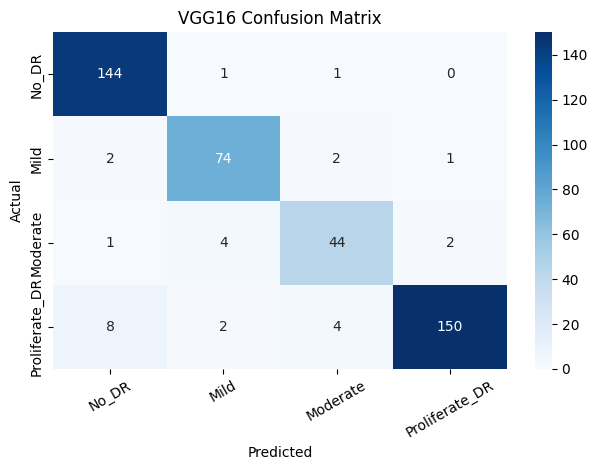


VGG16 results: {'Model': 'VGG16', 'Accuracy': 0.9363636363636364, 'Precision': 0.9377178702479145, 'Recall': 0.9363636363636364, 'F1-Score': 0.9363054533592736}
Saved VGG16 model and metrics.


In [ ]:

# FAST VGG16 TRAINING
# Keep the existing train_df, val_df and test_df.

import os
import time
import numpy as np
import tensorflow as tf
import pandas as pd
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight

IMG_SIZE_FAST = (160, 160)
BATCH_FAST = 32
EPOCHS_FAST = 3

CLASSES = ["No_DR", "Mild", "Moderate", "Proliferate_DR"]

# VGG16 preprocessing; don't add rescale=1./255
train_gen_fast = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
).flow_from_dataframe(
    train_df[train_df["label"].isin(CLASSES)].copy(),
    x_col="filepath", y_col="label",
    classes=CLASSES, target_size=IMG_SIZE_FAST,
    batch_size=BATCH_FAST, class_mode="categorical",
    shuffle=True, seed=42
)

eval_datagen_fast = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

val_gen_fast = eval_datagen_fast.flow_from_dataframe(
    val_df[val_df["label"].isin(CLASSES)].copy(),
    x_col="filepath", y_col="label",
    classes=CLASSES, target_size=IMG_SIZE_FAST,
    batch_size=BATCH_FAST, class_mode="categorical",
    shuffle=False
)

test_gen_fast = eval_datagen_fast.flow_from_dataframe(
    test_df[test_df["label"].isin(CLASSES)].copy(),
    x_col="filepath", y_col="label",
    classes=CLASSES, target_size=IMG_SIZE_FAST,
    batch_size=BATCH_FAST, class_mode="categorical",
    shuffle=False
)

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASSES)),
    y=train_gen_fast.classes
)
class_weights_fast = dict(enumerate(weights))

base_fast = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(160, 160, 3)
)
base_fast.trainable = False

inputs = layers.Input(shape=(160, 160, 3))
x = base_fast(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(4, activation="softmax")(x)

vgg16_fast = Model(inputs, outputs, name="VGG16_DR_Fast")

vgg16_fast.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

os.makedirs("/content/dr_models", exist_ok=True)

callbacks_fast = [
    EarlyStopping(
        monitor="val_loss", patience=2,
        restore_best_weights=True, verbose=1
    ),
    ModelCheckpoint(
        "/content/dr_models/vgg16_fast_best.keras",
        monitor="val_loss", save_best_only=True, verbose=1
    )
]

start = time.time()

history_vgg16_fast = vgg16_fast.fit(
    train_gen_fast,
    validation_data=val_gen_fast,
    epochs=EPOCHS_FAST,
    class_weight=class_weights_fast,
    callbacks=callbacks_fast,
    verbose=1
)

print(f"Training time: {(time.time()-start)/60:.2f} minutes")

# Evaluate on the same held-out test split
test_gen_fast.reset()
probs = vgg16_fast.predict(test_gen_fast, verbose=1)
preds = np.argmax(probs, axis=1)
actual = test_gen_fast.classes

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

print("\nVGG16 Classification Report:")
print(classification_report(
    actual, preds, labels=[0,1,2,3],
    target_names=CLASSES, zero_division=0
))

cm = confusion_matrix(actual, preds, labels=[0,1,2,3])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("VGG16 Confusion Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

vgg16_results = {
    "Model": "VGG16",
    "Accuracy": accuracy_score(actual, preds),
    "Precision": precision_score(actual, preds, average="weighted", zero_division=0),
    "Recall": recall_score(actual, preds, average="weighted", zero_division=0),
    "F1-Score": f1_score(actual, preds, average="weighted", zero_division=0)
}

print("\nVGG16 results:", vgg16_results)

pd.DataFrame([vgg16_results]).to_csv(
    "/content/dr_models/vgg16_results.csv", index=False
)
vgg16_fast.save("/content/dr_models/vgg16_fast_final.keras")
print("Saved VGG16 model and metrics.")


# ***VGG19 model***

VGG19 - DIABETIC RETINOPATHY CLASSIFICATION
GPU: []

Dataset sizes:
Train: 2049
Validation: 439
Test: 440
Found 2049 validated image filenames belonging to 4 classes.
Found 439 validated image filenames belonging to 4 classes.
Found 440 validated image filenames belonging to 4 classes.

Class weights: {0: 0.7566469719350074, 1: 1.3882113821138211, 2: 2.12551867219917, 3: 0.672244094488189}
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "VGG19_DR_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19 (Functional)              │ (None, 5, 5, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,090,564 (76.64 MB)

 Trainable params: 66,180 (258.52 KB)

 Non-trainable params: 20,024,384 (76.39 MB)


Starting VGG19 training...
Epoch 1/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 15s/step - accuracy: 0.3468 - loss: 7.1131 
Epoch 1: val_loss improved from None to 1.22063, saving model to /content/dr_models/vgg19_best.keras

Epoch 1: finished saving model to /content/dr_models/vgg19_best.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 1152s 18s/step - accuracy: 0.3860 - loss: 5.6851 - val_accuracy: 0.6424 - val_loss: 1.2206
Epoch 2/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 15s/step - accuracy: 0.5738 - loss: 3.1181 
Epoch 2: val_loss improved from 1.22063 to 0.57714, saving model to /content/dr_models/vgg19_best.keras

Epoch 2: finished saving model to /content/dr_models/vgg19_best.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 1146s 18s/step - accuracy: 0.5905 - loss: 2.8269 - val_accuracy: 0.8223 - val_loss: 0.5771
Epoch 3/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 15s/step - accuracy: 0.6658 - loss: 2.1514 
Epoch 3: val_loss improved from 0.57714 to 0.57361, saving model to /content/dr_models/vgg19_best.keras

Epoch 3: finished saving model t

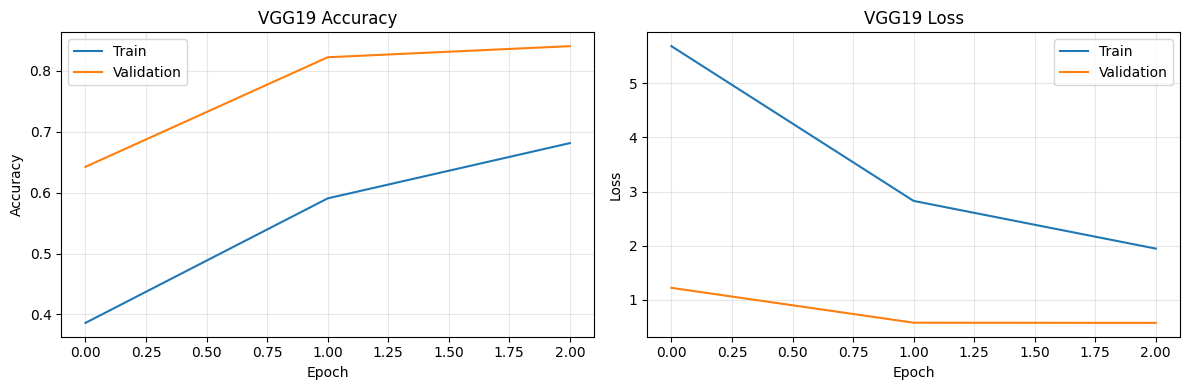


Evaluating VGG19 on the test set...
14/14 ━━━━━━━━━━━━━━━━━━━━ 200s 14s/step

VGG19 Classification Report:
                precision    recall  f1-score   support

         No_DR       0.96      0.82      0.89       146
          Mild       0.55      0.97      0.71        79
      Moderate       0.94      0.63      0.75        51
Proliferate_DR       0.97      0.84      0.90       164

      accuracy                           0.83       440
     macro avg       0.86      0.82      0.81       440
  weighted avg       0.89      0.83      0.84       440



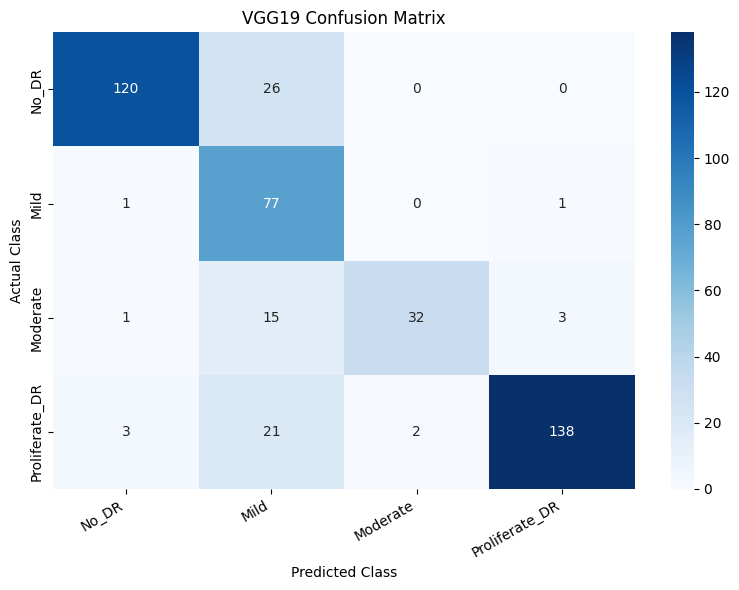


VGG19 TEST RESULTS
Model: VGG19
Accuracy: 83.41%
Precision: 88.93%
Recall: 83.41%
F1-Score: 84.42%
Training_Time_Minutes: 57.72 minutes

Saved model: /content/dr_models/vgg19_final.keras
Saved metrics: /content/dr_models/vgg19_results.csv

VGG19 training and evaluation completed.


In [ ]:

# ==============================================================
# MODEL 4: VGG19 - COMPLETE CODE IN ONE CELL
# Diabetic Retinopathy Detection
# ==============================================================

import os
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

print("=" * 60)
print("VGG19 - DIABETIC RETINOPATHY CLASSIFICATION")
print("=" * 60)
print("GPU:", tf.config.list_physical_devices("GPU"))

# 1. SETTINGS
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
EPOCHS = 3
CLASSES = ["No_DR", "Mild", "Moderate", "Proliferate_DR"]
NUM_CLASSES = len(CLASSES)

tf.keras.utils.set_random_seed(42)

# 2. CHECK EXISTING DATAFRAMES
for name in ["train_df", "val_df", "test_df"]:
    if name not in globals():
        raise ValueError(
            f"{name} not found. Run your dataset split cell first."
        )

for name, frame in [
    ("train_df", train_df),
    ("val_df", val_df),
    ("test_df", test_df)
]:
    if not {"filepath", "label"}.issubset(frame.columns):
        raise ValueError(
            f"{name} must contain filepath and label columns."
        )

train_data = train_df[train_df["label"].isin(CLASSES)].copy()
val_data = val_df[val_df["label"].isin(CLASSES)].copy()
test_data = test_df[test_df["label"].isin(CLASSES)].copy()

for split_name, frame in [
    ("Training", train_data),
    ("Validation", val_data),
    ("Test", test_data)
]:
    if frame.empty:
        raise ValueError(f"{split_name} dataset is empty.")
    missing = set(CLASSES) - set(frame["label"].unique())
    if missing:
        raise ValueError(f"{split_name} is missing classes: {missing}")

print("\nDataset sizes:")
print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))

# 3. VGG19 DATA GENERATORS
# VGG19 preprocessing is applied; do not also use rescale=1./255.
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.10,
    horizontal_flip=True
)

eval_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_gen = train_datagen.flow_from_dataframe(
    train_data,
    x_col="filepath",
    y_col="label",
    classes=CLASSES,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

val_gen = eval_datagen.flow_from_dataframe(
    val_data,
    x_col="filepath",
    y_col="label",
    classes=CLASSES,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

test_gen = eval_datagen.flow_from_dataframe(
    test_data,
    x_col="filepath",
    y_col="label",
    classes=CLASSES,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

# 4. CLASS WEIGHTS
class_values = np.arange(NUM_CLASSES)

weight_values = compute_class_weight(
    class_weight="balanced",
    classes=class_values,
    y=train_gen.classes
)

class_weights = {
    int(i): float(w)
    for i, w in zip(class_values, weight_values)
}

print("\nClass weights:", class_weights)

# 5. BUILD VGG19
vgg19_base = VGG19(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
)

vgg19_base.trainable = False

inputs = layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
x = vgg19_base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

vgg19_model = Model(inputs, outputs, name="VGG19_DR_Classifier")

vgg19_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

vgg19_model.summary()

# 6. CALLBACKS
os.makedirs("/content/dr_models", exist_ok=True)
checkpoint_path = "/content/dr_models/vgg19_best.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

# 7. TRAIN
print("\nStarting VGG19 training...")
start_time = time.time()

history_vgg19 = vgg19_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

training_minutes = (time.time() - start_time) / 60
print(f"\nTraining time: {training_minutes:.2f} minutes")
print("Epochs completed:", len(history_vgg19.history["loss"]))

# Load the best saved checkpoint
vgg19_model = tf.keras.models.load_model(checkpoint_path)

# 8. TRAINING GRAPHS
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_vgg19.history["accuracy"], label="Train")
axes[0].plot(history_vgg19.history["val_accuracy"], label="Validation")
axes[0].set_title("VGG19 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_vgg19.history["loss"], label="Train")
axes[1].plot(history_vgg19.history["val_loss"], label="Validation")
axes[1].set_title("VGG19 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 9. TEST EVALUATION
print("\nEvaluating VGG19 on the test set...")
test_gen.reset()

probabilities = vgg19_model.predict(test_gen, verbose=1)
predictions = np.argmax(probabilities, axis=1)
actual = test_gen.classes

# 10. CLASSIFICATION REPORT
print("\nVGG19 Classification Report:")
print(classification_report(
    actual,
    predictions,
    labels=class_values,
    target_names=CLASSES,
    zero_division=0
))

# 11. CONFUSION MATRIX
cm = confusion_matrix(
    actual,
    predictions,
    labels=class_values
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.title("VGG19 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# 12. CALCULATE ACTUAL METRICS
vgg19_results = {
    "Model": "VGG19",
    "Accuracy": float(accuracy_score(actual, predictions)),
    "Precision": float(precision_score(
        actual, predictions, average="weighted", zero_division=0
    )),
    "Recall": float(recall_score(
        actual, predictions, average="weighted", zero_division=0
    )),
    "F1-Score": float(f1_score(
        actual, predictions, average="weighted", zero_division=0
    )),
    "Training_Time_Minutes": float(training_minutes)
}

print("\n" + "=" * 50)
print("VGG19 TEST RESULTS")
print("=" * 50)

for key, value in vgg19_results.items():
    if key == "Model":
        print(f"{key}: {value}")
    elif key == "Training_Time_Minutes":
        print(f"{key}: {value:.2f} minutes")
    else:
        print(f"{key}: {value * 100:.2f}%")

# 13. SAVE MODEL AND RESULTS
vgg19_model.save("/content/dr_models/vgg19_final.keras")

pd.DataFrame([vgg19_results]).to_csv(
    "/content/dr_models/vgg19_results.csv",
    index=False
)

print("\nSaved model: /content/dr_models/vgg19_final.keras")
print("Saved metrics: /content/dr_models/vgg19_results.csv")
print("\nVGG19 training and evaluation completed.")


# ***DenseNet121 model***

DENSENET121 - DIABETIC RETINOPATHY CLASSIFICATION
TensorFlow: 2.21.0
GPU devices: []

Dataset sizes:
Training: 2049
Validation: 439
Testing: 440
Found 2049 validated image filenames belonging to 4 classes.
Found 439 validated image filenames belonging to 4 classes.
Found 440 validated image filenames belonging to 4 classes.

Class weights: {0: 0.7566469719350074, 1: 1.3882113821138211, 2: 2.12551867219917, 3: 0.672244094488189}
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "DenseNet121_DR_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 5, 5, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,169,220 (27.35 MB)

 Trainable params: 131,716 (514.52 KB)

 Non-trainable params: 7,037,504 (26.85 MB)


Starting DenseNet121 training...
Epoch 1/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.3085 - loss: 1.9317
Epoch 1: val_loss improved from None to 0.78865, saving model to /content/dr_models/densenet121_best.keras

Epoch 1: finished saving model to /content/dr_models/densenet121_best.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 316s 5s/step - accuracy: 0.3782 - loss: 1.7243 - val_accuracy: 0.6834 - val_loss: 0.7886
Epoch 2/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.5506 - loss: 1.1309
Epoch 2: val_loss improved from 0.78865 to 0.52904, saving model to /content/dr_models/densenet121_best.keras

Epoch 2: finished saving model to /content/dr_models/densenet121_best.keras
65/65 ━━━━━━━━━━━━━━━━━━━━ 337s 5s/step - accuracy: 0.5861 - loss: 1.0177 - val_accuracy: 0.8087 - val_loss: 0.5290
Epoch 3/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.7249 - loss: 0.6830
Epoch 3: val_loss improved from 0.52904 to 0.34316, saving model to /content/dr_models/densenet121_best.keras

Epoch 

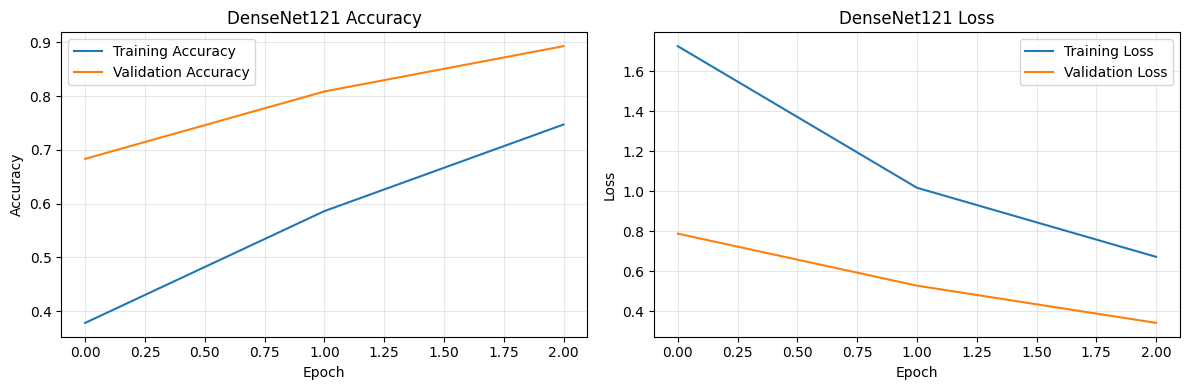


Evaluating DenseNet121...
14/14 ━━━━━━━━━━━━━━━━━━━━ 58s 4s/step

DenseNet121 Classification Report:
                precision    recall  f1-score   support

         No_DR       0.99      0.90      0.95       146
          Mild       0.64      0.96      0.77        79
      Moderate       1.00      0.80      0.89        51
Proliferate_DR       0.97      0.88      0.92       164

      accuracy                           0.89       440
     macro avg       0.90      0.89      0.88       440
  weighted avg       0.92      0.89      0.90       440



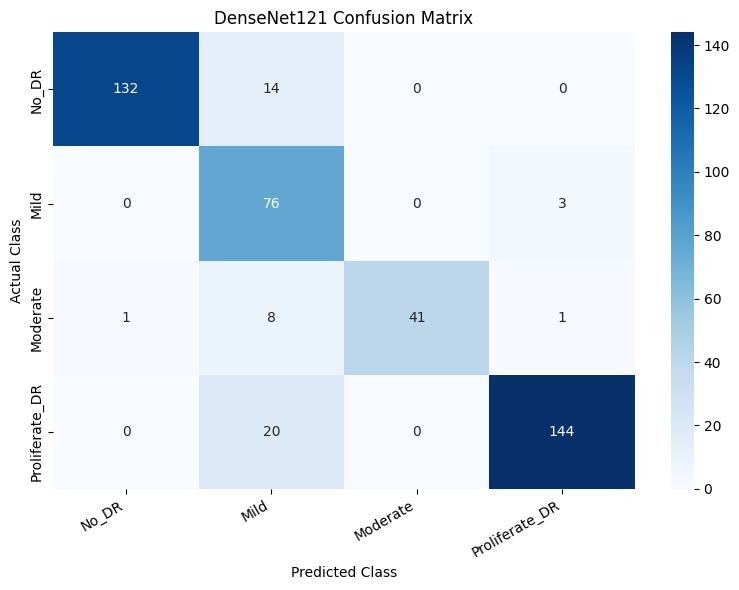


DENSENET121 TEST RESULTS
Model: DenseNet121
Accuracy: 89.32%
Precision: 92.35%
Recall: 89.32%
F1-Score: 89.99%
Training_Time_Minutes: 15.92 minutes

Saved model: /content/dr_models/densenet121_final.keras
Saved metrics: /content/dr_models/densenet121_results.csv

DenseNet121 training and evaluation completed.


In [ ]:

# ==============================================================
# MODEL 5: DENSENET121 - COMPLETE CODE IN ONE CELL
# Diabetic Retinopathy Detection
# ==============================================================

import os
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

print("=" * 65)
print("DENSENET121 - DIABETIC RETINOPATHY CLASSIFICATION")
print("=" * 65)
print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

# 1. CONFIGURATION
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
EPOCHS = 3
CLASSES = ["No_DR", "Mild", "Moderate", "Proliferate_DR"]
NUM_CLASSES = len(CLASSES)

tf.keras.utils.set_random_seed(42)

# 2. CHECK DATAFRAMES
for name in ["train_df", "val_df", "test_df"]:
    if name not in globals():
        raise ValueError(
            f"{name} not found. Run your dataset split cell first."
        )

for name, frame in [
    ("train_df", train_df),
    ("val_df", val_df),
    ("test_df", test_df)
]:
    if not {"filepath", "label"}.issubset(frame.columns):
        raise ValueError(
            f"{name} must contain filepath and label columns."
        )

train_data = train_df[train_df["label"].isin(CLASSES)].copy()
val_data = val_df[val_df["label"].isin(CLASSES)].copy()
test_data = test_df[test_df["label"].isin(CLASSES)].copy()

for split_name, frame in [
    ("Training", train_data),
    ("Validation", val_data),
    ("Test", test_data)
]:
    if frame.empty:
        raise ValueError(f"{split_name} dataset is empty.")
    missing = set(CLASSES) - set(frame["label"].unique())
    if missing:
        raise ValueError(f"{split_name} is missing classes: {missing}")

print("\nDataset sizes:")
print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_data))

# 3. DENSENET121 DATA GENERATORS
# DenseNet preprocess_input scales images appropriately.
# Do not also use rescale=1./255.

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    width_shift_range=0.08,
    height_shift_range=0.08,
    zoom_range=0.10,
    horizontal_flip=True
)

eval_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

train_gen = train_datagen.flow_from_dataframe(
    dataframe=train_data,
    x_col="filepath",
    y_col="label",
    classes=CLASSES,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

val_gen = eval_datagen.flow_from_dataframe(
    dataframe=val_data,
    x_col="filepath",
    y_col="label",
    classes=CLASSES,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

test_gen = eval_datagen.flow_from_dataframe(
    dataframe=test_data,
    x_col="filepath",
    y_col="label",
    classes=CLASSES,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

# 4. CLASS WEIGHTS
class_ids = np.arange(NUM_CLASSES)

weight_values = compute_class_weight(
    class_weight="balanced",
    classes=class_ids,
    y=train_gen.classes
)

class_weights = {
    int(i): float(w)
    for i, w in zip(class_ids, weight_values)
}

print("\nClass weights:", class_weights)

# 5. BUILD DENSENET121
densenet_base = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(160, 160, 3)
)

densenet_base.trainable = False

inputs = layers.Input(shape=(160, 160, 3))
x = densenet_base(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

densenet121_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="DenseNet121_DR_Classifier"
)

densenet121_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

densenet121_model.summary()

# 6. CALLBACKS
os.makedirs("/content/dr_models", exist_ok=True)
checkpoint_path = "/content/dr_models/densenet121_best.keras"

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

# 7. TRAIN
print("\nStarting DenseNet121 training...")
start_time = time.time()

history_densenet121 = densenet121_model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

training_minutes = (time.time() - start_time) / 60

print(f"\nTraining time: {training_minutes:.2f} minutes")
print("Epochs completed:", len(history_densenet121.history["loss"]))

# Load the best checkpoint
densenet121_model = tf.keras.models.load_model(checkpoint_path)

# 8. TRAINING GRAPHS
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    history_densenet121.history["accuracy"],
    label="Training Accuracy"
)
axes[0].plot(
    history_densenet121.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[0].set_title("DenseNet121 Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history_densenet121.history["loss"],
    label="Training Loss"
)
axes[1].plot(
    history_densenet121.history["val_loss"],
    label="Validation Loss"
)
axes[1].set_title("DenseNet121 Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 9. TEST EVALUATION
print("\nEvaluating DenseNet121...")
test_gen.reset()

probabilities = densenet121_model.predict(test_gen, verbose=1)
predictions = np.argmax(probabilities, axis=1)
actual = test_gen.classes

# 10. CLASSIFICATION REPORT
print("\nDenseNet121 Classification Report:")
print(classification_report(
    actual,
    predictions,
    labels=class_ids,
    target_names=CLASSES,
    zero_division=0
))

# 11. CONFUSION MATRIX
cm = confusion_matrix(
    actual,
    predictions,
    labels=class_ids
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)
plt.title("DenseNet121 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# 12. CALCULATE METRICS
densenet121_results = {
    "Model": "DenseNet121",
    "Accuracy": float(accuracy_score(actual, predictions)),
    "Precision": float(precision_score(
        actual, predictions, average="weighted", zero_division=0
    )),
    "Recall": float(recall_score(
        actual, predictions, average="weighted", zero_division=0
    )),
    "F1-Score": float(f1_score(
        actual, predictions, average="weighted", zero_division=0
    )),
    "Training_Time_Minutes": float(training_minutes)
}

print("\n" + "=" * 55)
print("DENSENET121 TEST RESULTS")
print("=" * 55)

for key, value in densenet121_results.items():
    if key == "Model":
        print(f"{key}: {value}")
    elif key == "Training_Time_Minutes":
        print(f"{key}: {value:.2f} minutes")
    else:
        print(f"{key}: {value * 100:.2f}%")

# 13. SAVE MODEL AND RESULTS
densenet121_model.save(
    "/content/dr_models/densenet121_final.keras"
)

pd.DataFrame([densenet121_results]).to_csv(
    "/content/dr_models/densenet121_results.csv",
    index=False
)

print("\nSaved model: /content/dr_models/densenet121_final.keras")
print("Saved metrics: /content/dr_models/densenet121_results.csv")
print("\nDenseNet121 training and evaluation completed.")


# ***DenseNet169***

Found 2049 validated image filenames belonging to 4 classes.
Found 439 validated image filenames belonging to 4 classes.
Found 440 validated image filenames belonging to 4 classes.
51877672/51877672 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 378s 6s/step - accuracy: 0.4143 - loss: 1.5963 - val_accuracy: 0.8474 - val_loss: 0.6342
Epoch 2/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 349s 5s/step - accuracy: 0.6862 - loss: 0.8567 - val_accuracy: 0.9043 - val_loss: 0.3875
Epoch 3/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 383s 5s/step - accuracy: 0.8028 - loss: 0.5555 - val_accuracy: 0.9362 - val_loss: 0.2838


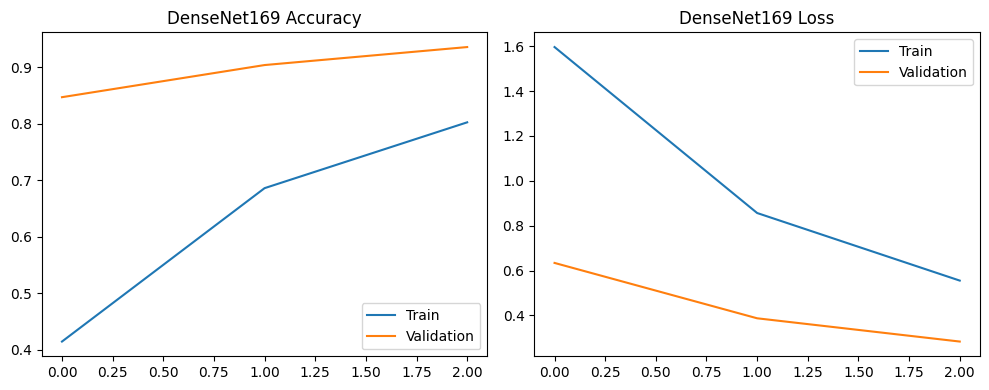

14/14 ━━━━━━━━━━━━━━━━━━━━ 69s 5s/step
                precision    recall  f1-score   support

         No_DR       0.94      0.99      0.96       146
          Mild       0.82      0.99      0.90        79
      Moderate       0.97      0.76      0.86        51
Proliferate_DR       0.98      0.90      0.94       164

      accuracy                           0.93       440
     macro avg       0.93      0.91      0.91       440
  weighted avg       0.94      0.93      0.93       440



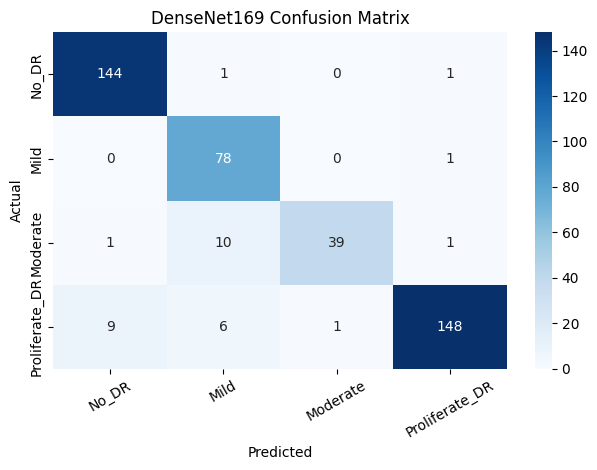

{'Model': 'DenseNet169', 'Accuracy': 0.9295454545454546, 'Precision': 0.93602127333755, 'Recall': 0.9295454545454546, 'F1-Score': 0.92911320097527, 'Training_Time_Minutes': 18.51908451318741}


In [ ]:

# MODEL 6: DENSENET169

import os, time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import DenseNet169
from tensorflow.keras.applications.densenet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

CLASSES = ["No_DR", "Mild", "Moderate", "Proliferate_DR"]
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
EPOCHS = 3
tf.keras.utils.set_random_seed(42)

for name in ["train_df", "val_df", "test_df"]:
    if name not in globals():
        raise ValueError(f"{name} missing. Run your dataset split cell.")

tr = train_df[train_df.label.isin(CLASSES)].copy()
va = val_df[val_df.label.isin(CLASSES)].copy()
te = test_df[test_df.label.isin(CLASSES)].copy()

aug = ImageDataGenerator(preprocessing_function=preprocess_input, rotation_range=10, zoom_range=0.1, horizontal_flip=True)
ev = ImageDataGenerator(preprocessing_function=preprocess_input)

tg = aug.flow_from_dataframe(tr, x_col="filepath", y_col="label", classes=CLASSES, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", shuffle=True, seed=42)
vg = ev.flow_from_dataframe(va, x_col="filepath", y_col="label", classes=CLASSES, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", shuffle=False)
eg = ev.flow_from_dataframe(te, x_col="filepath", y_col="label", classes=CLASSES, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", shuffle=False)

w = compute_class_weight(class_weight="balanced", classes=np.arange(4), y=tg.classes)
cw = dict(enumerate(w))

base = DenseNet169(weights="imagenet", include_top=False, input_shape=(160,160,3))
base.trainable = False
inp = layers.Input((160,160,3))
x = base(inp, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(4, activation="softmax")(x)
densenet169_model = Model(inp, out, name="DenseNet169_DR")

densenet169_model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss="categorical_crossentropy", metrics=["accuracy"])
os.makedirs("/content/dr_models", exist_ok=True)
path = "/content/dr_models/densenet169_best.keras"
callbacks = [EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True), ModelCheckpoint(path, monitor="val_loss", save_best_only=True)]

start = time.time()
hist = densenet169_model.fit(tg, validation_data=vg, epochs=EPOCHS, class_weight=cw, callbacks=callbacks)
minutes = (time.time()-start)/60
densenet169_model = tf.keras.models.load_model(path)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(hist.history["accuracy"], label="Train")
plt.plot(hist.history["val_accuracy"], label="Validation")
plt.title("DenseNet169 Accuracy"); plt.legend()
plt.subplot(1,2,2)
plt.plot(hist.history["loss"], label="Train")
plt.plot(hist.history["val_loss"], label="Validation")
plt.title("DenseNet169 Loss"); plt.legend()
plt.tight_layout(); plt.show()

eg.reset()
p = densenet169_model.predict(eg, verbose=1)
pred = np.argmax(p, axis=1)
actual = eg.classes
print(classification_report(actual, pred, labels=range(4), target_names=CLASSES, zero_division=0))

sns.heatmap(confusion_matrix(actual, pred, labels=range(4)), annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.title("DenseNet169 Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

densenet169_results = {"Model":"DenseNet169", "Accuracy":accuracy_score(actual,pred), "Precision":precision_score(actual,pred,average="weighted",zero_division=0), "Recall":recall_score(actual,pred,average="weighted",zero_division=0), "F1-Score":f1_score(actual,pred,average="weighted",zero_division=0), "Training_Time_Minutes":minutes}
print(densenet169_results)
densenet169_model.save("/content/dr_models/densenet169_final.keras")
pd.DataFrame([densenet169_results]).to_csv("/content/dr_models/densenet169_results.csv", index=False)


# ***InceptionV3***

Found 2049 validated image filenames belonging to 4 classes.
Found 439 validated image filenames belonging to 4 classes.
Found 440 validated image filenames belonging to 4 classes.
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 209s 3s/step - accuracy: 0.4246 - loss: 1.6452 - val_accuracy: 0.7563 - val_loss: 0.6864
Epoch 2/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 194s 3s/step - accuracy: 0.6803 - loss: 0.8817 - val_accuracy: 0.8519 - val_loss: 0.4557
Epoch 3/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 196s 3s/step - accuracy: 0.7701 - loss: 0.6420 - val_accuracy: 0.8793 - val_loss: 0.3659


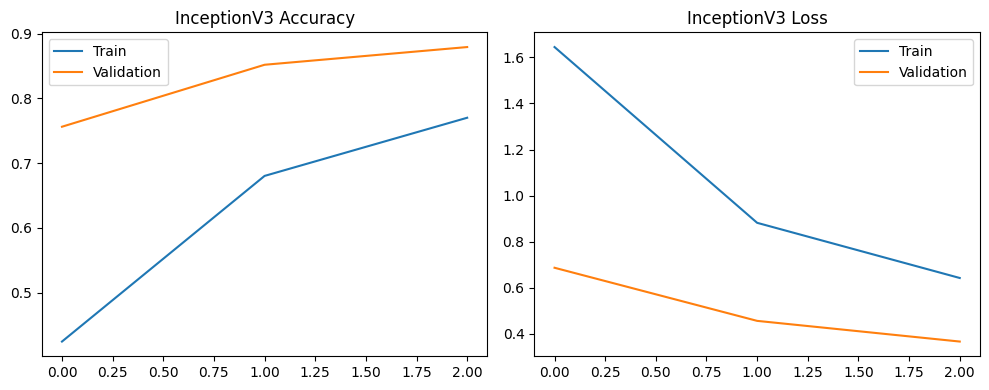

14/14 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step
                precision    recall  f1-score   support

         No_DR       0.82      0.98      0.89       146
          Mild       0.81      0.82      0.82        79
      Moderate       0.82      0.71      0.76        51
Proliferate_DR       0.96      0.83      0.89       164

      accuracy                           0.86       440
     macro avg       0.85      0.83      0.84       440
  weighted avg       0.87      0.86      0.86       440



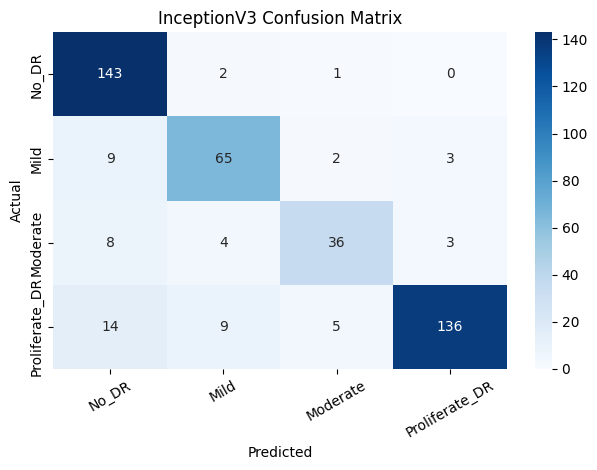

{'Model': 'InceptionV3', 'Accuracy': 0.8636363636363636, 'Precision': 0.8703947750218418, 'Recall': 0.8636363636363636, 'F1-Score': 0.8625206916483604, 'Training_Time_Minutes': 9.999706061681112}


In [ ]:

# MODEL 7: INCEPTIONV3

import os, time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.applications.inception_v3 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

CLASSES = ["No_DR", "Mild", "Moderate", "Proliferate_DR"]
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
EPOCHS = 3
tf.keras.utils.set_random_seed(42)

for name in ["train_df", "val_df", "test_df"]:
    if name not in globals():
        raise ValueError(f"{name} missing. Run your dataset split cell.")

tr = train_df[train_df.label.isin(CLASSES)].copy()
va = val_df[val_df.label.isin(CLASSES)].copy()
te = test_df[test_df.label.isin(CLASSES)].copy()

aug = ImageDataGenerator(preprocessing_function=preprocess_input, rotation_range=10, zoom_range=0.1, horizontal_flip=True)
ev = ImageDataGenerator(preprocessing_function=preprocess_input)

tg = aug.flow_from_dataframe(tr, x_col="filepath", y_col="label", classes=CLASSES, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", shuffle=True, seed=42)
vg = ev.flow_from_dataframe(va, x_col="filepath", y_col="label", classes=CLASSES, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", shuffle=False)
eg = ev.flow_from_dataframe(te, x_col="filepath", y_col="label", classes=CLASSES, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", shuffle=False)

w = compute_class_weight(class_weight="balanced", classes=np.arange(4), y=tg.classes)
cw = dict(enumerate(w))

base = InceptionV3(weights="imagenet", include_top=False, input_shape=(160,160,3))
base.trainable = False
inp = layers.Input((160,160,3))
x = base(inp, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(4, activation="softmax")(x)
inceptionv3_model = Model(inp, out, name="InceptionV3_DR")

inceptionv3_model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss="categorical_crossentropy", metrics=["accuracy"])
os.makedirs("/content/dr_models", exist_ok=True)
path = "/content/dr_models/inceptionv3_best.keras"
callbacks = [EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True), ModelCheckpoint(path, monitor="val_loss", save_best_only=True)]

start = time.time()
hist = inceptionv3_model.fit(tg, validation_data=vg, epochs=EPOCHS, class_weight=cw, callbacks=callbacks)
minutes = (time.time()-start)/60
inceptionv3_model = tf.keras.models.load_model(path)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(hist.history["accuracy"], label="Train")
plt.plot(hist.history["val_accuracy"], label="Validation")
plt.title("InceptionV3 Accuracy"); plt.legend()
plt.subplot(1,2,2)
plt.plot(hist.history["loss"], label="Train")
plt.plot(hist.history["val_loss"], label="Validation")
plt.title("InceptionV3 Loss"); plt.legend()
plt.tight_layout(); plt.show()

eg.reset()
p = inceptionv3_model.predict(eg, verbose=1)
pred = np.argmax(p, axis=1)
actual = eg.classes
print(classification_report(actual, pred, labels=range(4), target_names=CLASSES, zero_division=0))

sns.heatmap(confusion_matrix(actual, pred, labels=range(4)), annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.title("InceptionV3 Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

inceptionv3_results = {"Model":"InceptionV3", "Accuracy":accuracy_score(actual,pred), "Precision":precision_score(actual,pred,average="weighted",zero_division=0), "Recall":recall_score(actual,pred,average="weighted",zero_division=0), "F1-Score":f1_score(actual,pred,average="weighted",zero_division=0), "Training_Time_Minutes":minutes}
print(inceptionv3_results)
inceptionv3_model.save("/content/dr_models/inceptionv3_final.keras")
pd.DataFrame([inceptionv3_results]).to_csv("/content/dr_models/inceptionv3_results.csv", index=False)


# ***Xception***

Found 2049 validated image filenames belonging to 4 classes.
Found 439 validated image filenames belonging to 4 classes.
Found 440 validated image filenames belonging to 4 classes.
83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 386s 6s/step - accuracy: 0.5451 - loss: 1.0949 - val_accuracy: 0.8200 - val_loss: 0.6465
Epoch 2/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 381s 6s/step - accuracy: 0.7838 - loss: 0.6243 - val_accuracy: 0.8519 - val_loss: 0.4371
Epoch 3/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 378s 6s/step - accuracy: 0.8516 - loss: 0.4687 - val_accuracy: 0.8929 - val_loss: 0.3380


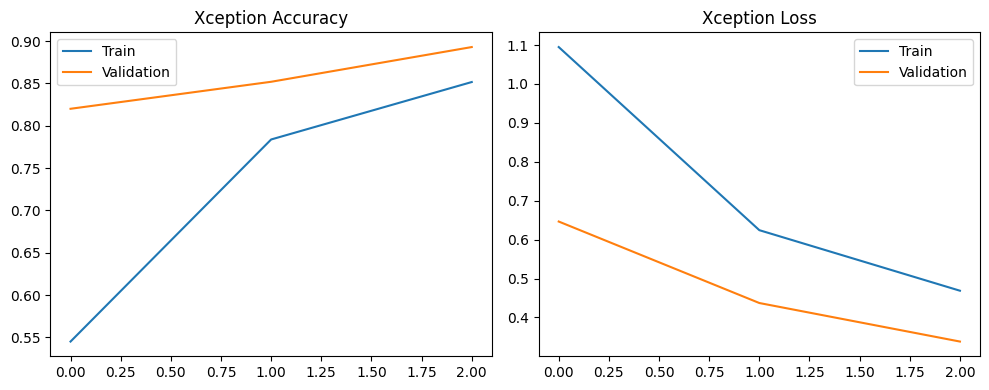

14/14 ━━━━━━━━━━━━━━━━━━━━ 67s 5s/step
                precision    recall  f1-score   support

         No_DR       0.87      0.99      0.92       146
          Mild       0.86      0.95      0.90        79
      Moderate       0.83      0.86      0.85        51
Proliferate_DR       0.98      0.80      0.88       164

      accuracy                           0.90       440
     macro avg       0.88      0.90      0.89       440
  weighted avg       0.90      0.90      0.89       440



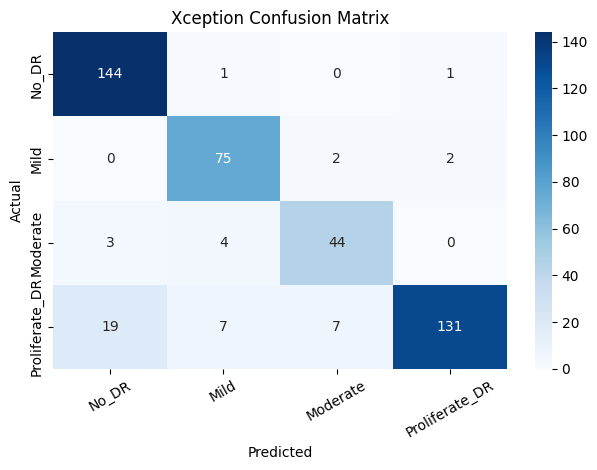

{'Model': 'Xception', 'Accuracy': 0.8954545454545455, 'Precision': 0.9032318898544666, 'Recall': 0.8954545454545455, 'F1-Score': 0.8943103148973611, 'Training_Time_Minutes': 19.166749354203542}


In [ ]:

# MODEL 8: XCEPTION

import os, time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import Xception
from tensorflow.keras.applications.xception import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

CLASSES = ["No_DR", "Mild", "Moderate", "Proliferate_DR"]
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
EPOCHS = 3
tf.keras.utils.set_random_seed(42)

for name in ["train_df", "val_df", "test_df"]:
    if name not in globals():
        raise ValueError(f"{name} missing. Run your dataset split cell.")

tr = train_df[train_df.label.isin(CLASSES)].copy()
va = val_df[val_df.label.isin(CLASSES)].copy()
te = test_df[test_df.label.isin(CLASSES)].copy()

aug = ImageDataGenerator(preprocessing_function=preprocess_input, rotation_range=10, zoom_range=0.1, horizontal_flip=True)
ev = ImageDataGenerator(preprocessing_function=preprocess_input)

tg = aug.flow_from_dataframe(tr, x_col="filepath", y_col="label", classes=CLASSES, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", shuffle=True, seed=42)
vg = ev.flow_from_dataframe(va, x_col="filepath", y_col="label", classes=CLASSES, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", shuffle=False)
eg = ev.flow_from_dataframe(te, x_col="filepath", y_col="label", classes=CLASSES, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", shuffle=False)

w = compute_class_weight(class_weight="balanced", classes=np.arange(4), y=tg.classes)
cw = dict(enumerate(w))

base = Xception(weights="imagenet", include_top=False, input_shape=(160,160,3))
base.trainable = False
inp = layers.Input((160,160,3))
x = base(inp, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(4, activation="softmax")(x)
xception_model = Model(inp, out, name="Xception_DR")

xception_model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss="categorical_crossentropy", metrics=["accuracy"])
os.makedirs("/content/dr_models", exist_ok=True)
path = "/content/dr_models/xception_best.keras"
callbacks = [EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True), ModelCheckpoint(path, monitor="val_loss", save_best_only=True)]

start = time.time()
hist = xception_model.fit(tg, validation_data=vg, epochs=EPOCHS, class_weight=cw, callbacks=callbacks)
minutes = (time.time()-start)/60
xception_model = tf.keras.models.load_model(path)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(hist.history["accuracy"], label="Train")
plt.plot(hist.history["val_accuracy"], label="Validation")
plt.title("Xception Accuracy"); plt.legend()
plt.subplot(1,2,2)
plt.plot(hist.history["loss"], label="Train")
plt.plot(hist.history["val_loss"], label="Validation")
plt.title("Xception Loss"); plt.legend()
plt.tight_layout(); plt.show()

eg.reset()
p = xception_model.predict(eg, verbose=1)
pred = np.argmax(p, axis=1)
actual = eg.classes
print(classification_report(actual, pred, labels=range(4), target_names=CLASSES, zero_division=0))

sns.heatmap(confusion_matrix(actual, pred, labels=range(4)), annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.title("Xception Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

xception_results = {"Model":"Xception", "Accuracy":accuracy_score(actual,pred), "Precision":precision_score(actual,pred,average="weighted",zero_division=0), "Recall":recall_score(actual,pred,average="weighted",zero_division=0), "F1-Score":f1_score(actual,pred,average="weighted",zero_division=0), "Training_Time_Minutes":minutes}
print(xception_results)
xception_model.save("/content/dr_models/xception_final.keras")
pd.DataFrame([xception_results]).to_csv("/content/dr_models/xception_results.csv", index=False)


# ***MobileNetV2***

Found 2049 validated image filenames belonging to 4 classes.
Found 439 validated image filenames belonging to 4 classes.
Found 440 validated image filenames belonging to 4 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 99s 1s/step - accuracy: 0.5417 - loss: 1.1866 - val_accuracy: 0.9112 - val_loss: 0.4310
Epoch 2/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 90s 1s/step - accuracy: 0.8819 - loss: 0.4067 - val_accuracy: 0.9658 - val_loss: 0.1990
Epoch 3/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 90s 1s/step - accuracy: 0.9234 - loss: 0.2459 - val_accuracy: 0.9772 - val_loss: 0.1254


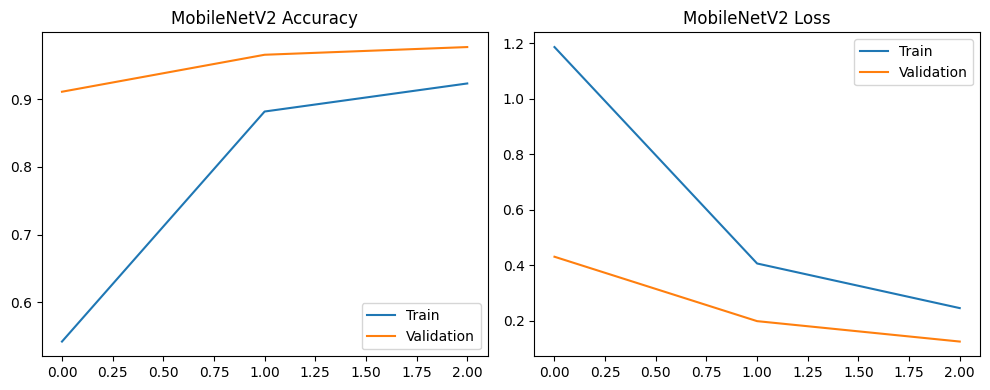

14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step
                precision    recall  f1-score   support

         No_DR       0.95      0.99      0.97       146
          Mild       0.97      0.94      0.95        79
      Moderate       0.94      0.92      0.93        51
Proliferate_DR       0.96      0.95      0.96       164

      accuracy                           0.96       440
     macro avg       0.96      0.95      0.95       440
  weighted avg       0.96      0.96      0.96       440



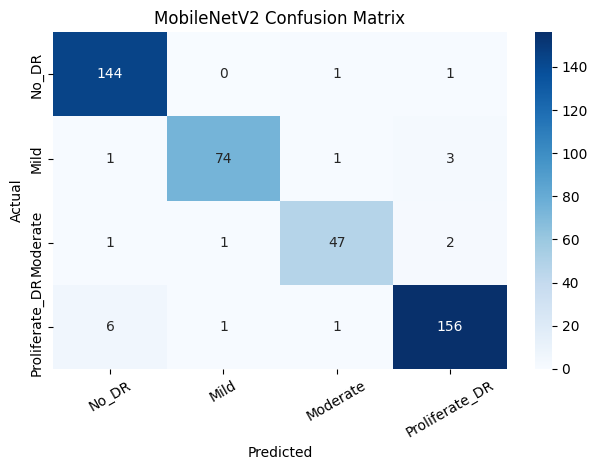

{'Model': 'MobileNetV2', 'Accuracy': 0.9568181818181818, 'Precision': 0.9570517455254296, 'Recall': 0.9568181818181818, 'F1-Score': 0.9567166612609844, 'Training_Time_Minutes': 4.657613762219747}


In [ ]:

# MODEL 9: MOBILENETV2

import os, time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

CLASSES = ["No_DR", "Mild", "Moderate", "Proliferate_DR"]
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
EPOCHS = 3
tf.keras.utils.set_random_seed(42)

for name in ["train_df", "val_df", "test_df"]:
    if name not in globals():
        raise ValueError(f"{name} missing. Run your dataset split cell.")

tr = train_df[train_df.label.isin(CLASSES)].copy()
va = val_df[val_df.label.isin(CLASSES)].copy()
te = test_df[test_df.label.isin(CLASSES)].copy()

aug = ImageDataGenerator(preprocessing_function=preprocess_input, rotation_range=10, zoom_range=0.1, horizontal_flip=True)
ev = ImageDataGenerator(preprocessing_function=preprocess_input)

tg = aug.flow_from_dataframe(tr, x_col="filepath", y_col="label", classes=CLASSES, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", shuffle=True, seed=42)
vg = ev.flow_from_dataframe(va, x_col="filepath", y_col="label", classes=CLASSES, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", shuffle=False)
eg = ev.flow_from_dataframe(te, x_col="filepath", y_col="label", classes=CLASSES, target_size=IMG_SIZE, batch_size=BATCH_SIZE, class_mode="categorical", shuffle=False)

w = compute_class_weight(class_weight="balanced", classes=np.arange(4), y=tg.classes)
cw = dict(enumerate(w))

base = MobileNetV2(weights="imagenet", include_top=False, input_shape=(160,160,3))
base.trainable = False
inp = layers.Input((160,160,3))
x = base(inp, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.2)(x)
out = layers.Dense(4, activation="softmax")(x)
mobilenetv2_model = Model(inp, out, name="MobileNetV2_DR")

mobilenetv2_model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss="categorical_crossentropy", metrics=["accuracy"])
os.makedirs("/content/dr_models", exist_ok=True)
path = "/content/dr_models/mobilenetv2_best.keras"
callbacks = [EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True), ModelCheckpoint(path, monitor="val_loss", save_best_only=True)]

start = time.time()
hist = mobilenetv2_model.fit(tg, validation_data=vg, epochs=EPOCHS, class_weight=cw, callbacks=callbacks)
minutes = (time.time()-start)/60
mobilenetv2_model = tf.keras.models.load_model(path)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(hist.history["accuracy"], label="Train")
plt.plot(hist.history["val_accuracy"], label="Validation")
plt.title("MobileNetV2 Accuracy"); plt.legend()
plt.subplot(1,2,2)
plt.plot(hist.history["loss"], label="Train")
plt.plot(hist.history["val_loss"], label="Validation")
plt.title("MobileNetV2 Loss"); plt.legend()
plt.tight_layout(); plt.show()

eg.reset()
p = mobilenetv2_model.predict(eg, verbose=1)
pred = np.argmax(p, axis=1)
actual = eg.classes
print(classification_report(actual, pred, labels=range(4), target_names=CLASSES, zero_division=0))

sns.heatmap(confusion_matrix(actual, pred, labels=range(4)), annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.title("MobileNetV2 Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()

mobilenetv2_results = {"Model":"MobileNetV2", "Accuracy":accuracy_score(actual,pred), "Precision":precision_score(actual,pred,average="weighted",zero_division=0), "Recall":recall_score(actual,pred,average="weighted",zero_division=0), "F1-Score":f1_score(actual,pred,average="weighted",zero_division=0), "Training_Time_Minutes":minutes}
print(mobilenetv2_results)
mobilenetv2_model.save("/content/dr_models/mobilenetv2_final.keras")
pd.DataFrame([mobilenetv2_results]).to_csv("/content/dr_models/mobilenetv2_results.csv", index=False)


# ***MobileNetV3Large***

Found 2049 validated image filenames belonging to 4 classes.
Found 439 validated image filenames belonging to 4 classes.
Found 440 validated image filenames belonging to 4 classes.
12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 92s 1s/step - accuracy: 0.3982 - loss: 1.5582 - val_accuracy: 0.7950 - val_loss: 0.7043
Epoch 2/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 81s 1s/step - accuracy: 0.7145 - loss: 0.8003 - val_accuracy: 0.9112 - val_loss: 0.3955
Epoch 3/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 92s 1s/step - accuracy: 0.8116 - loss: 0.5380 - val_accuracy: 0.9522 - val_loss: 0.2619


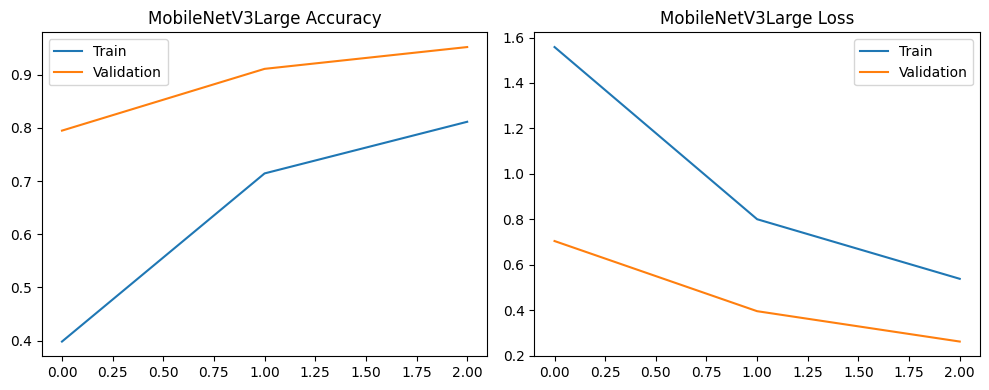

14/14 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step
                precision    recall  f1-score   support

         No_DR       0.91      0.98      0.94       146
          Mild       0.93      0.95      0.94        79
      Moderate       0.90      0.86      0.88        51
Proliferate_DR       0.97      0.90      0.94       164

      accuracy                           0.93       440
     macro avg       0.93      0.92      0.92       440
  weighted avg       0.93      0.93      0.93       440



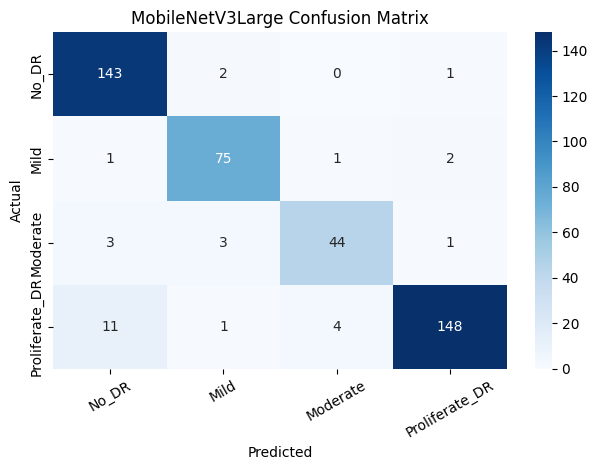

{'Model': 'MobileNetV3Large', 'Accuracy': 0.9318181818181818, 'Precision': 0.9335625398821362, 'Recall': 0.9318181818181818, 'F1-Score': 0.9316318552782993, 'Training_Time_Minutes': 4.440959584712982}


In [ ]:

# MODEL 10: MobileNetV3Large

import os, time, numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt, seaborn as sns
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV3Large
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

NAME = "MobileNetV3Large"
CLASSES = ["No_DR", "Mild", "Moderate", "Proliferate_DR"]
SIZE, BATCH, EPOCHS = (160, 160), 32, 3
tf.keras.utils.set_random_seed(42)

for n in ["train_df", "val_df", "test_df"]:
    if n not in globals(): raise ValueError(f"{n} missing; run the dataset split cell.")

tr, va, te = [d[d["label"].isin(CLASSES)].copy() for d in (train_df, val_df, test_df)]
aug = ImageDataGenerator(preprocessing_function=preprocess_input, rotation_range=10, zoom_range=.1, horizontal_flip=True)
ev = ImageDataGenerator(preprocessing_function=preprocess_input)
tg = aug.flow_from_dataframe(tr, x_col="filepath", y_col="label", classes=CLASSES, target_size=SIZE, batch_size=BATCH, class_mode="categorical", shuffle=True, seed=42)
vg = ev.flow_from_dataframe(va, x_col="filepath", y_col="label", classes=CLASSES, target_size=SIZE, batch_size=BATCH, class_mode="categorical", shuffle=False)
eg = ev.flow_from_dataframe(te, x_col="filepath", y_col="label", classes=CLASSES, target_size=SIZE, batch_size=BATCH, class_mode="categorical", shuffle=False)
cw = dict(enumerate(compute_class_weight(class_weight="balanced", classes=np.arange(4), y=tg.classes)))

base = MobileNetV3Large(weights="imagenet", include_top=False, input_shape=(160,160,3))
base.trainable = False
inp = layers.Input((160,160,3)); x = base(inp, training=False)
x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(.35)(x)
x = layers.Dense(128, activation="relu")(x); x = layers.Dropout(.25)(x)
out = layers.Dense(4, activation="softmax")(x)
model = Model(inp, out, name=NAME)
model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss="categorical_crossentropy", metrics=["accuracy"])

os.makedirs("/content/dr_models", exist_ok=True)
path = f"/content/dr_models/{NAME.lower()}_best.keras"
cb = [EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True), ModelCheckpoint(path, monitor="val_loss", save_best_only=True)]
start = time.time()
hist = model.fit(tg, validation_data=vg, epochs=EPOCHS, class_weight=cw, callbacks=cb)
minutes = (time.time()-start)/60
model = tf.keras.models.load_model(path)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1); plt.plot(hist.history["accuracy"], label="Train"); plt.plot(hist.history["val_accuracy"], label="Validation"); plt.title(NAME+" Accuracy"); plt.legend()
plt.subplot(1,2,2); plt.plot(hist.history["loss"], label="Train"); plt.plot(hist.history["val_loss"], label="Validation"); plt.title(NAME+" Loss"); plt.legend()
plt.tight_layout(); plt.show()

eg.reset(); probs = model.predict(eg, verbose=1); pred = probs.argmax(axis=1); actual = eg.classes
print(classification_report(actual, pred, labels=range(4), target_names=CLASSES, zero_division=0))
sns.heatmap(confusion_matrix(actual,pred,labels=range(4)), annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.title(NAME+" Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()
results = {"Model":NAME, "Accuracy":accuracy_score(actual,pred), "Precision":precision_score(actual,pred,average="weighted",zero_division=0), "Recall":recall_score(actual,pred,average="weighted",zero_division=0), "F1-Score":f1_score(actual,pred,average="weighted",zero_division=0), "Training_Time_Minutes":minutes}
print(results)
model.save(f"/content/dr_models/{NAME.lower()}_final.keras")
pd.DataFrame([results]).to_csv(f"/content/dr_models/{NAME.lower()}_results.csv", index=False)


# ***EfficientNetB1***

Found 2049 validated image filenames belonging to 4 classes.
Found 439 validated image filenames belonging to 4 classes.
Found 440 validated image filenames belonging to 4 classes.
27018416/27018416 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 207s 3s/step - accuracy: 0.5920 - loss: 1.0804 - val_accuracy: 0.8519 - val_loss: 0.6771
Epoch 2/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 195s 3s/step - accuracy: 0.8497 - loss: 0.5802 - val_accuracy: 0.9362 - val_loss: 0.3811
Epoch 3/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 191s 3s/step - accuracy: 0.8931 - loss: 0.3905 - val_accuracy: 0.9476 - val_loss: 0.2714


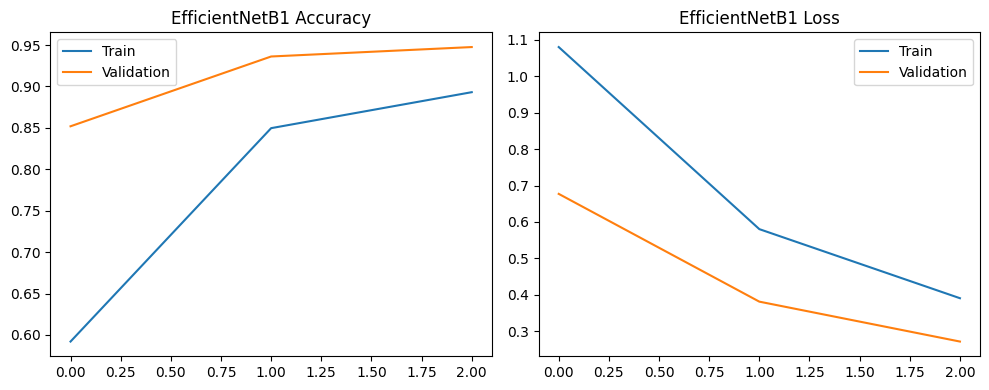

14/14 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step
                precision    recall  f1-score   support

         No_DR       0.96      0.95      0.96       146
          Mild       0.82      0.94      0.88        79
      Moderate       0.90      0.92      0.91        51
Proliferate_DR       0.97      0.90      0.93       164

      accuracy                           0.93       440
     macro avg       0.91      0.93      0.92       440
  weighted avg       0.93      0.93      0.93       440



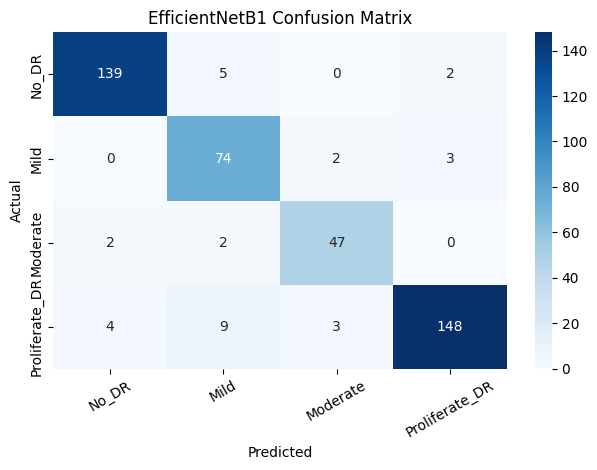

{'Model': 'EfficientNetB1', 'Accuracy': 0.9272727272727272, 'Precision': 0.9310246658345035, 'Recall': 0.9272727272727272, 'F1-Score': 0.9280464345249745, 'Training_Time_Minutes': 9.924752755959828}


In [ ]:

# MODEL 11: EfficientNetB1

import os, time, numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt, seaborn as sns
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB1
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

NAME="EfficientNetB1"; CLASSES=["No_DR","Mild","Moderate","Proliferate_DR"]; SIZE=(160,160); BATCH=32; EPOCHS=3
tf.keras.utils.set_random_seed(42)
for n in ["train_df","val_df","test_df"]:
    if n not in globals(): raise ValueError(f"{n} missing; run dataset split first.")
tr,va,te=[d[d.label.isin(CLASSES)].copy() for d in (train_df,val_df,test_df)]
aug=ImageDataGenerator(preprocessing_function=preprocess_input,rotation_range=10,zoom_range=.1,horizontal_flip=True); ev=ImageDataGenerator(preprocessing_function=preprocess_input)
tg=aug.flow_from_dataframe(tr,x_col="filepath",y_col="label",classes=CLASSES,target_size=SIZE,batch_size=BATCH,class_mode="categorical",shuffle=True,seed=42)
vg=ev.flow_from_dataframe(va,x_col="filepath",y_col="label",classes=CLASSES,target_size=SIZE,batch_size=BATCH,class_mode="categorical",shuffle=False)
eg=ev.flow_from_dataframe(te,x_col="filepath",y_col="label",classes=CLASSES,target_size=SIZE,batch_size=BATCH,class_mode="categorical",shuffle=False)
cw=dict(enumerate(compute_class_weight(class_weight="balanced",classes=np.arange(4),y=tg.classes)))
base=EfficientNetB1(weights="imagenet",include_top=False,input_shape=(160,160,3)); base.trainable=False
inp=layers.Input((160,160,3)); x=base(inp,training=False); x=layers.GlobalAveragePooling2D()(x); x=layers.Dropout(.35)(x); x=layers.Dense(128,activation="relu")(x); x=layers.Dropout(.25)(x); out=layers.Dense(4,activation="softmax")(x)
model=Model(inp,out,name=NAME); model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),loss="categorical_crossentropy",metrics=["accuracy"])
os.makedirs("/content/dr_models",exist_ok=True); path=f"/content/dr_models/{NAME.lower()}_best.keras"
cb=[EarlyStopping(monitor="val_loss",patience=2,restore_best_weights=True),ModelCheckpoint(path,monitor="val_loss",save_best_only=True)]
start=time.time(); hist=model.fit(tg,validation_data=vg,epochs=EPOCHS,class_weight=cw,callbacks=cb); minutes=(time.time()-start)/60
model=tf.keras.models.load_model(path)
plt.figure(figsize=(10,4)); plt.subplot(1,2,1); plt.plot(hist.history["accuracy"],label="Train"); plt.plot(hist.history["val_accuracy"],label="Validation"); plt.title(NAME+" Accuracy"); plt.legend()
plt.subplot(1,2,2); plt.plot(hist.history["loss"],label="Train"); plt.plot(hist.history["val_loss"],label="Validation"); plt.title(NAME+" Loss"); plt.legend(); plt.tight_layout(); plt.show()
eg.reset(); probs=model.predict(eg,verbose=1); pred=probs.argmax(1); actual=eg.classes
print(classification_report(actual,pred,labels=range(4),target_names=CLASSES,zero_division=0))
sns.heatmap(confusion_matrix(actual,pred,labels=range(4)),annot=True,fmt="d",cmap="Blues",xticklabels=CLASSES,yticklabels=CLASSES); plt.title(NAME+" Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()
results={"Model":NAME,"Accuracy":accuracy_score(actual,pred),"Precision":precision_score(actual,pred,average="weighted",zero_division=0),"Recall":recall_score(actual,pred,average="weighted",zero_division=0),"F1-Score":f1_score(actual,pred,average="weighted",zero_division=0),"Training_Time_Minutes":minutes}
print(results); model.save(f"/content/dr_models/{NAME.lower()}_final.keras"); pd.DataFrame([results]).to_csv(f"/content/dr_models/{NAME.lower()}_results.csv",index=False)


# ***EfficientNetB2***

Found 2049 validated image filenames belonging to 4 classes.
Found 439 validated image filenames belonging to 4 classes.
Found 440 validated image filenames belonging to 4 classes.
Epoch 1/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 240s 3s/step - accuracy: 0.6271 - loss: 1.0404 - val_accuracy: 0.8451 - val_loss: 0.6718
Epoch 2/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 192s 3s/step - accuracy: 0.8590 - loss: 0.5752 - val_accuracy: 0.9203 - val_loss: 0.3832
Epoch 3/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 203s 3s/step - accuracy: 0.8941 - loss: 0.4113 - val_accuracy: 0.9294 - val_loss: 0.3000


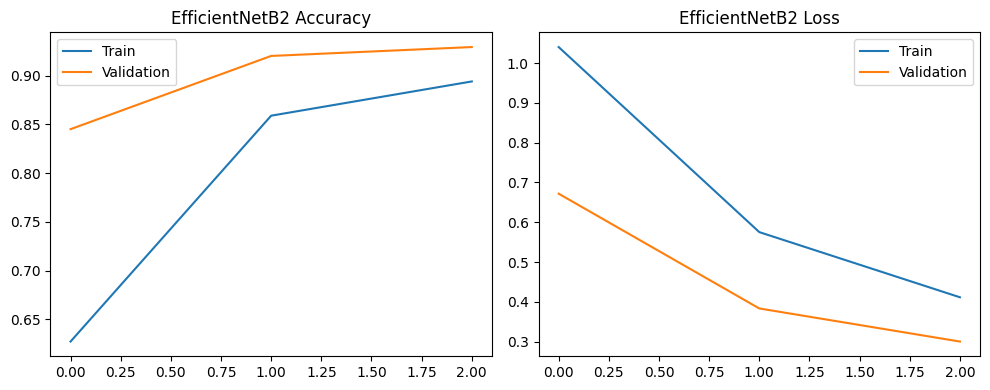

14/14 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step
                precision    recall  f1-score   support

         No_DR       0.93      0.96      0.95       146
          Mild       0.80      0.84      0.82        79
      Moderate       0.82      0.90      0.86        51
Proliferate_DR       0.95      0.88      0.91       164

      accuracy                           0.90       440
     macro avg       0.88      0.89      0.88       440
  weighted avg       0.90      0.90      0.90       440



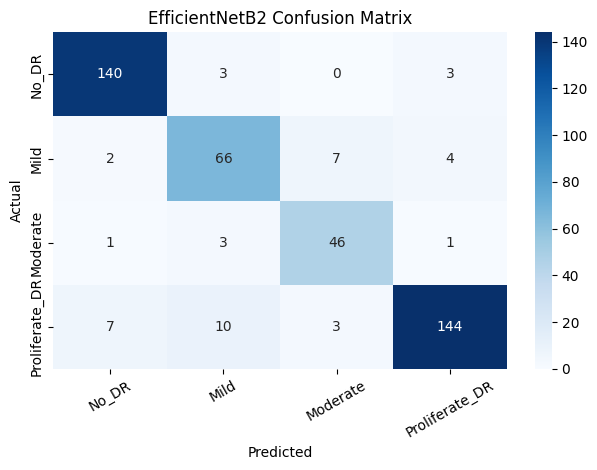

{'Model': 'EfficientNetB2', 'Accuracy': 0.9, 'Precision': 0.9025302516268497, 'Recall': 0.9, 'F1-Score': 0.9004479912809346, 'Training_Time_Minutes': 10.631929604212443}


In [ ]:

# MODEL 12: EfficientNetB2

import os, time, numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt, seaborn as sns
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB2
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

NAME="EfficientNetB2"; CLASSES=["No_DR","Mild","Moderate","Proliferate_DR"]; SIZE=(160,160); BATCH=32; EPOCHS=3
tf.keras.utils.set_random_seed(42)
for n in ["train_df","val_df","test_df"]:
    if n not in globals(): raise ValueError(f"{n} missing; run dataset split first.")
tr,va,te=[d[d.label.isin(CLASSES)].copy() for d in (train_df,val_df,test_df)]
aug=ImageDataGenerator(preprocessing_function=preprocess_input,rotation_range=10,zoom_range=.1,horizontal_flip=True); ev=ImageDataGenerator(preprocessing_function=preprocess_input)
tg=aug.flow_from_dataframe(tr,x_col="filepath",y_col="label",classes=CLASSES,target_size=SIZE,batch_size=BATCH,class_mode="categorical",shuffle=True,seed=42)
vg=ev.flow_from_dataframe(va,x_col="filepath",y_col="label",classes=CLASSES,target_size=SIZE,batch_size=BATCH,class_mode="categorical",shuffle=False)
eg=ev.flow_from_dataframe(te,x_col="filepath",y_col="label",classes=CLASSES,target_size=SIZE,batch_size=BATCH,class_mode="categorical",shuffle=False)
cw=dict(enumerate(compute_class_weight(class_weight="balanced",classes=np.arange(4),y=tg.classes)))
base=EfficientNetB2(weights="imagenet",include_top=False,input_shape=(160,160,3)); base.trainable=False
inp=layers.Input((160,160,3)); x=base(inp,training=False); x=layers.GlobalAveragePooling2D()(x); x=layers.Dropout(.35)(x); x=layers.Dense(128,activation="relu")(x); x=layers.Dropout(.25)(x); out=layers.Dense(4,activation="softmax")(x)
model=Model(inp,out,name=NAME); model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),loss="categorical_crossentropy",metrics=["accuracy"])
os.makedirs("/content/dr_models",exist_ok=True); path=f"/content/dr_models/{NAME.lower()}_best.keras"
cb=[EarlyStopping(monitor="val_loss",patience=2,restore_best_weights=True),ModelCheckpoint(path,monitor="val_loss",save_best_only=True)]
start=time.time(); hist=model.fit(tg,validation_data=vg,epochs=EPOCHS,class_weight=cw,callbacks=cb); minutes=(time.time()-start)/60
model=tf.keras.models.load_model(path)
plt.figure(figsize=(10,4)); plt.subplot(1,2,1); plt.plot(hist.history["accuracy"],label="Train"); plt.plot(hist.history["val_accuracy"],label="Validation"); plt.title(NAME+" Accuracy"); plt.legend()
plt.subplot(1,2,2); plt.plot(hist.history["loss"],label="Train"); plt.plot(hist.history["val_loss"],label="Validation"); plt.title(NAME+" Loss"); plt.legend(); plt.tight_layout(); plt.show()
eg.reset(); probs=model.predict(eg,verbose=1); pred=probs.argmax(1); actual=eg.classes
print(classification_report(actual,pred,labels=range(4),target_names=CLASSES,zero_division=0))
sns.heatmap(confusion_matrix(actual,pred,labels=range(4)),annot=True,fmt="d",cmap="Blues",xticklabels=CLASSES,yticklabels=CLASSES); plt.title(NAME+" Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()
results={"Model":NAME,"Accuracy":accuracy_score(actual,pred),"Precision":precision_score(actual,pred,average="weighted",zero_division=0),"Recall":recall_score(actual,pred,average="weighted",zero_division=0),"F1-Score":f1_score(actual,pred,average="weighted",zero_division=0),"Training_Time_Minutes":minutes}
print(results); model.save(f"/content/dr_models/{NAME.lower()}_final.keras"); pd.DataFrame([results]).to_csv(f"/content/dr_models/{NAME.lower()}_results.csv",index=False)


# ***13. ResNet101***

Found 2049 validated image filenames belonging to 4 classes.
Found 439 validated image filenames belonging to 4 classes.
Found 440 validated image filenames belonging to 4 classes.
171446536/171446536 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 558s 8s/step - accuracy: 0.6491 - loss: 0.9910 - val_accuracy: 0.9180 - val_loss: 0.2545
Epoch 2/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 530s 8s/step - accuracy: 0.8946 - loss: 0.3267 - val_accuracy: 0.9590 - val_loss: 0.1519
Epoch 3/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 541s 8s/step - accuracy: 0.9317 - loss: 0.2073 - val_accuracy: 0.9613 - val_loss: 0.1215


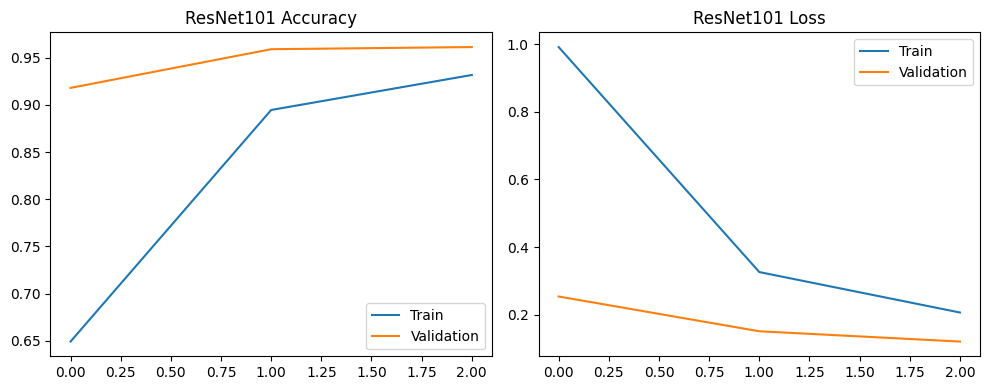

14/14 ━━━━━━━━━━━━━━━━━━━━ 99s 7s/step
                precision    recall  f1-score   support

         No_DR       0.98      0.99      0.99       146
          Mild       0.93      0.96      0.94        79
      Moderate       0.88      0.96      0.92        51
Proliferate_DR       0.98      0.92      0.95       164

      accuracy                           0.96       440
     macro avg       0.94      0.96      0.95       440
  weighted avg       0.96      0.96      0.96       440



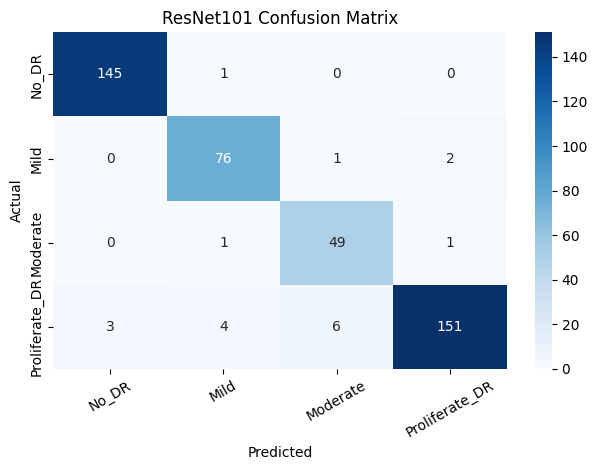

{'Model': 'ResNet101', 'Accuracy': 0.9568181818181818, 'Precision': 0.9583869262292211, 'Recall': 0.9568181818181818, 'F1-Score': 0.9569458282287311, 'Training_Time_Minutes': 27.17545837163925}


In [ ]:

# MODEL 13: ResNet101

import os, time, numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt, seaborn as sns
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet101
from tensorflow.keras.applications.resnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

NAME="ResNet101"; CLASSES=["No_DR","Mild","Moderate","Proliferate_DR"]; SIZE=(160,160); BATCH=32; EPOCHS=3
tf.keras.utils.set_random_seed(42)
for n in ["train_df","val_df","test_df"]:
    if n not in globals(): raise ValueError(f"{n} missing; run dataset split first.")
tr,va,te=[d[d.label.isin(CLASSES)].copy() for d in (train_df,val_df,test_df)]
aug=ImageDataGenerator(preprocessing_function=preprocess_input,rotation_range=10,zoom_range=.1,horizontal_flip=True); ev=ImageDataGenerator(preprocessing_function=preprocess_input)
tg=aug.flow_from_dataframe(tr,x_col="filepath",y_col="label",classes=CLASSES,target_size=SIZE,batch_size=BATCH,class_mode="categorical",shuffle=True,seed=42)
vg=ev.flow_from_dataframe(va,x_col="filepath",y_col="label",classes=CLASSES,target_size=SIZE,batch_size=BATCH,class_mode="categorical",shuffle=False)
eg=ev.flow_from_dataframe(te,x_col="filepath",y_col="label",classes=CLASSES,target_size=SIZE,batch_size=BATCH,class_mode="categorical",shuffle=False)
cw=dict(enumerate(compute_class_weight(class_weight="balanced",classes=np.arange(4),y=tg.classes)))
base=ResNet101(weights="imagenet",include_top=False,input_shape=(160,160,3)); base.trainable=False
inp=layers.Input((160,160,3)); x=base(inp,training=False); x=layers.GlobalAveragePooling2D()(x); x=layers.Dropout(.35)(x); x=layers.Dense(128,activation="relu")(x); x=layers.Dropout(.25)(x); out=layers.Dense(4,activation="softmax")(x)
model=Model(inp,out,name=NAME); model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),loss="categorical_crossentropy",metrics=["accuracy"])
os.makedirs("/content/dr_models",exist_ok=True); path=f"/content/dr_models/{NAME.lower()}_best.keras"
cb=[EarlyStopping(monitor="val_loss",patience=2,restore_best_weights=True),ModelCheckpoint(path,monitor="val_loss",save_best_only=True)]
start=time.time(); hist=model.fit(tg,validation_data=vg,epochs=EPOCHS,class_weight=cw,callbacks=cb); minutes=(time.time()-start)/60
model=tf.keras.models.load_model(path)
plt.figure(figsize=(10,4)); plt.subplot(1,2,1); plt.plot(hist.history["accuracy"],label="Train"); plt.plot(hist.history["val_accuracy"],label="Validation"); plt.title(NAME+" Accuracy"); plt.legend()
plt.subplot(1,2,2); plt.plot(hist.history["loss"],label="Train"); plt.plot(hist.history["val_loss"],label="Validation"); plt.title(NAME+" Loss"); plt.legend(); plt.tight_layout(); plt.show()
eg.reset(); probs=model.predict(eg,verbose=1); pred=probs.argmax(1); actual=eg.classes
print(classification_report(actual,pred,labels=range(4),target_names=CLASSES,zero_division=0))
sns.heatmap(confusion_matrix(actual,pred,labels=range(4)),annot=True,fmt="d",cmap="Blues",xticklabels=CLASSES,yticklabels=CLASSES); plt.title(NAME+" Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()
results={"Model":NAME,"Accuracy":accuracy_score(actual,pred),"Precision":precision_score(actual,pred,average="weighted",zero_division=0),"Recall":recall_score(actual,pred,average="weighted",zero_division=0),"F1-Score":f1_score(actual,pred,average="weighted",zero_division=0),"Training_Time_Minutes":minutes}
print(results); model.save(f"/content/dr_models/{NAME.lower()}_final.keras"); pd.DataFrame([results]).to_csv(f"/content/dr_models/{NAME.lower()}_results.csv",index=False)


In [ ]:
# MODEL 13: ResNet101 — Percentage Confusion Matrix

import os
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet101
from tensorflow.keras.applications.resnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 1. Configuration
NAME = "ResNet101"
CLASSES = ["No_DR", "Mild", "Moderate", "Proliferate_DR"]
SIZE = (160, 160)
BATCH = 32
EPOCHS = 3

tf.keras.utils.set_random_seed(42)

# 2. Check dataset splits
for n in ["train_df", "val_df", "test_df"]:
    if n not in globals():
        raise ValueError(f"{n} missing; run dataset split first.")

tr, va, te = [
    d[d.label.isin(CLASSES)].copy()
    for d in (train_df, val_df, test_df)
]

# 3. Image preprocessing and augmentation
aug = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

ev = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

tg = aug.flow_from_dataframe(
    tr,
    x_col="filepath",
    y_col="label",
    classes=CLASSES,
    target_size=SIZE,
    batch_size=BATCH,
    class_mode="categorical",
    shuffle=True,
    seed=42
)

vg = ev.flow_from_dataframe(
    va,
    x_col="filepath",
    y_col="label",
    classes=CLASSES,
    target_size=SIZE,
    batch_size=BATCH,
    class_mode="categorical",
    shuffle=False
)

eg = ev.flow_from_dataframe(
    te,
    x_col="filepath",
    y_col="label",
    classes=CLASSES,
    target_size=SIZE,
    batch_size=BATCH,
    class_mode="categorical",
    shuffle=False
)

# 4. Class weights
cw_values = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASSES)),
    y=tg.classes
)

cw = dict(enumerate(cw_values))

# 5. Build ResNet101 model
base = ResNet101(
    weights="imagenet",
    include_top=False,
    input_shape=(SIZE[0], SIZE[1], 3)
)

base.trainable = False

inp = layers.Input(shape=(SIZE[0], SIZE[1], 3))
x = base(inp, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.35)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.25)(x)

out = layers.Dense(
    len(CLASSES),
    activation="softmax"
)(x)

model = Model(inp, out, name=NAME)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# 6. Save paths and callbacks
os.makedirs("/content/dr_models", exist_ok=True)

path = f"/content/dr_models/{NAME.lower()}_best.keras"

cb = [
    EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        path,
        monitor="val_loss",
        save_best_only=True
    )
]

# 7. Train model
start = time.time()

hist = model.fit(
    tg,
    validation_data=vg,
    epochs=EPOCHS,
    class_weight=cw,
    callbacks=cb
)

minutes = (time.time() - start) / 60

# 8. Load best model
model = tf.keras.models.load_model(path)

# 9. Plot training accuracy and loss
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(hist.history["accuracy"], label="Training Accuracy")
plt.plot(hist.history["val_accuracy"], label="Validation Accuracy")
plt.title(NAME + " Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist.history["loss"], label="Training Loss")
plt.plot(hist.history["val_loss"], label="Validation Loss")
plt.title(NAME + " Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

# 10. Predict on test dataset
eg.reset()

probs = model.predict(eg, verbose=1)

pred = np.argmax(probs, axis=1)
actual = eg.classes

# 11. Classification report
print("\nClassification Report:\n")

print(
    classification_report(
        actual,
        pred,
        labels=range(len(CLASSES)),
        target_names=CLASSES,
        zero_division=0
    )
)

# 12. Confusion matrix in percentages
cm = confusion_matrix(
    actual,
    pred,
    labels=range(len(CLASSES))
)

# Convert counts into row-wise percentages
row_totals = cm.sum(axis=1, keepdims=True)

cm_percent = np.divide(
    cm.astype(float) * 100,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_percent,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Percentage (%)"}
)

plt.title(NAME + " Confusion Matrix (%)", fontsize=14)
plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("Actual Class", fontsize=12)

plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

# Save percentage confusion matrix
plt.savefig(
    f"/content/dr_models/{NAME.lower()}_confusion_matrix_percent.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 13. Calculate evaluation metrics
results = {
    "Model": NAME,
    "Accuracy": accuracy_score(actual, pred),
    "Precision": precision_score(
        actual, pred, average="weighted", zero_division=0
    ),
    "Recall": recall_score(
        actual, pred, average="weighted", zero_division=0
    ),
    "F1-Score": f1_score(
        actual, pred, average="weighted", zero_division=0
    ),
    "Training_Time_Minutes": minutes
}

print("\nFinal Results:")
print(results)

# 14. Save model and results
model.save(f"/content/dr_models/{NAME.lower()}_final.keras")

pd.DataFrame([results]).to_csv(
    f"/content/dr_models/{NAME.lower()}_results.csv",
    index=False
)

print("\nModel and results saved successfully!")
print("Percentage confusion matrix saved at:")
print(f"/content/dr_models/{NAME.lower()}_confusion_matrix_percent.png")

ValueError: train_df missing; run dataset split first.

# ***14. ResNet152***

Found 2049 validated image filenames belonging to 4 classes.
Found 439 validated image filenames belonging to 4 classes.
Found 440 validated image filenames belonging to 4 classes.
234698864/234698864 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Epoch 1/3
129/129 ━━━━━━━━━━━━━━━━━━━━ 816s 6s/step - accuracy: 0.6828 - loss: 0.9815 - val_accuracy: 0.9749 - val_loss: 0.1491
Epoch 2/3
129/129 ━━━━━━━━━━━━━━━━━━━━ 791s 6s/step - accuracy: 0.9141 - loss: 0.2899 - val_accuracy: 0.9727 - val_loss: 0.1061
Epoch 3/3
129/129 ━━━━━━━━━━━━━━━━━━━━ 787s 6s/step - accuracy: 0.9517 - loss: 0.1639 - val_accuracy: 0.9727 - val_loss: 0.0893


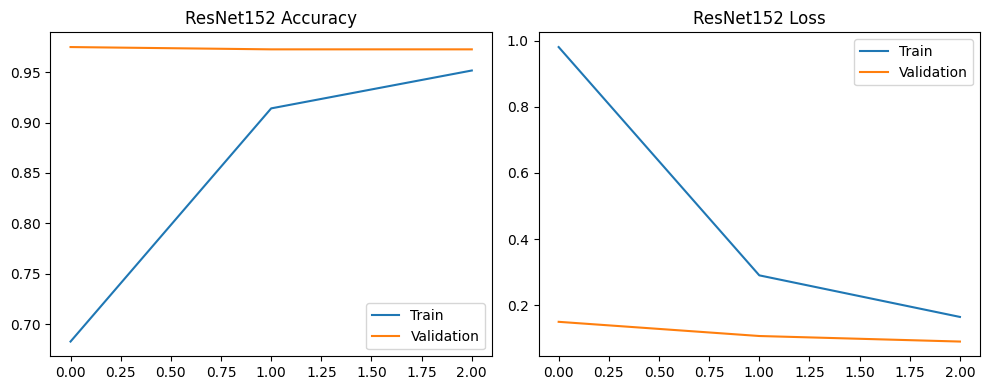

28/28 ━━━━━━━━━━━━━━━━━━━━ 154s 5s/step
                precision    recall  f1-score   support

         No_DR       0.98      0.99      0.99       146
          Mild       0.89      0.97      0.93        79
      Moderate       0.98      0.86      0.92        51
Proliferate_DR       0.98      0.96      0.97       164

      accuracy                           0.96       440
     macro avg       0.96      0.95      0.95       440
  weighted avg       0.96      0.96      0.96       440



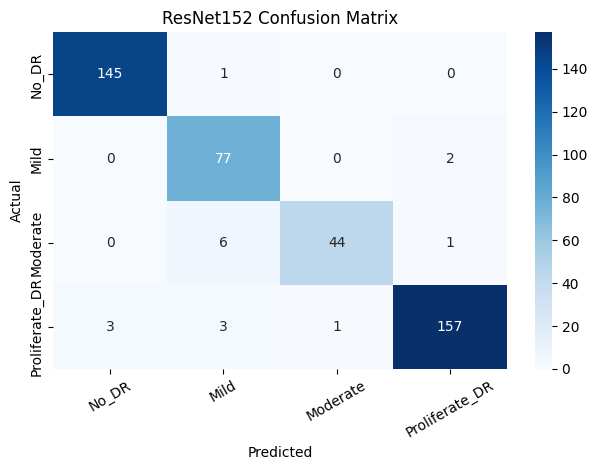

{'Model': 'ResNet152', 'Accuracy': 0.9613636363636363, 'Precision': 0.9630721532661187, 'Recall': 0.9613636363636363, 'F1-Score': 0.961343258349139, 'Training_Time_Minutes': 39.90852339665095}


In [ ]:

# MODEL 14: ResNet152

import os, time, numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt, seaborn as sns
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet152
from tensorflow.keras.applications.resnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

NAME="ResNet152"; CLASSES=["No_DR","Mild","Moderate","Proliferate_DR"]; SIZE=(160,160); BATCH=16; EPOCHS=3
tf.keras.utils.set_random_seed(42)
for n in ["train_df","val_df","test_df"]:
    if n not in globals(): raise ValueError(f"{n} missing; run dataset split first.")
tr,va,te=[d[d.label.isin(CLASSES)].copy() for d in (train_df,val_df,test_df)]
aug=ImageDataGenerator(preprocessing_function=preprocess_input,rotation_range=10,zoom_range=.1,horizontal_flip=True); ev=ImageDataGenerator(preprocessing_function=preprocess_input)
tg=aug.flow_from_dataframe(tr,x_col="filepath",y_col="label",classes=CLASSES,target_size=SIZE,batch_size=BATCH,class_mode="categorical",shuffle=True,seed=42)
vg=ev.flow_from_dataframe(va,x_col="filepath",y_col="label",classes=CLASSES,target_size=SIZE,batch_size=BATCH,class_mode="categorical",shuffle=False)
eg=ev.flow_from_dataframe(te,x_col="filepath",y_col="label",classes=CLASSES,target_size=SIZE,batch_size=BATCH,class_mode="categorical",shuffle=False)
cw=dict(enumerate(compute_class_weight(class_weight="balanced",classes=np.arange(4),y=tg.classes)))
base=ResNet152(weights="imagenet",include_top=False,input_shape=(160,160,3)); base.trainable=False
inp=layers.Input((160,160,3)); x=base(inp,training=False); x=layers.GlobalAveragePooling2D()(x); x=layers.Dropout(.35)(x); x=layers.Dense(128,activation="relu")(x); x=layers.Dropout(.25)(x); out=layers.Dense(4,activation="softmax")(x)
model=Model(inp,out,name=NAME); model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),loss="categorical_crossentropy",metrics=["accuracy"])
os.makedirs("/content/dr_models",exist_ok=True); path=f"/content/dr_models/{NAME.lower()}_best.keras"
cb=[EarlyStopping(monitor="val_loss",patience=2,restore_best_weights=True),ModelCheckpoint(path,monitor="val_loss",save_best_only=True)]
start=time.time(); hist=model.fit(tg,validation_data=vg,epochs=EPOCHS,class_weight=cw,callbacks=cb); minutes=(time.time()-start)/60
model=tf.keras.models.load_model(path)
plt.figure(figsize=(10,4)); plt.subplot(1,2,1); plt.plot(hist.history["accuracy"],label="Train"); plt.plot(hist.history["val_accuracy"],label="Validation"); plt.title(NAME+" Accuracy"); plt.legend()
plt.subplot(1,2,2); plt.plot(hist.history["loss"],label="Train"); plt.plot(hist.history["val_loss"],label="Validation"); plt.title(NAME+" Loss"); plt.legend(); plt.tight_layout(); plt.show()
eg.reset(); probs=model.predict(eg,verbose=1); pred=probs.argmax(1); actual=eg.classes
print(classification_report(actual,pred,labels=range(4),target_names=CLASSES,zero_division=0))
sns.heatmap(confusion_matrix(actual,pred,labels=range(4)),annot=True,fmt="d",cmap="Blues",xticklabels=CLASSES,yticklabels=CLASSES); plt.title(NAME+" Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()
results={"Model":NAME,"Accuracy":accuracy_score(actual,pred),"Precision":precision_score(actual,pred,average="weighted",zero_division=0),"Recall":recall_score(actual,pred,average="weighted",zero_division=0),"F1-Score":f1_score(actual,pred,average="weighted",zero_division=0),"Training_Time_Minutes":minutes}
print(results); model.save(f"/content/dr_models/{NAME.lower()}_final.keras"); pd.DataFrame([results]).to_csv(f"/content/dr_models/{NAME.lower()}_results.csv",index=False)


# ***15. NASNetMobile***

Found 2049 validated image filenames belonging to 4 classes.
Found 439 validated image filenames belonging to 4 classes.
Found 440 validated image filenames belonging to 4 classes.
19993432/19993432 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 207s 3s/step - accuracy: 0.5554 - loss: 1.0978 - val_accuracy: 0.8041 - val_loss: 0.6402
Epoch 2/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 180s 3s/step - accuracy: 0.7775 - loss: 0.6300 - val_accuracy: 0.8497 - val_loss: 0.4716
Epoch 3/3
65/65 ━━━━━━━━━━━━━━━━━━━━ 171s 3s/step - accuracy: 0.8360 - loss: 0.4559 - val_accuracy: 0.9043 - val_loss: 0.3247


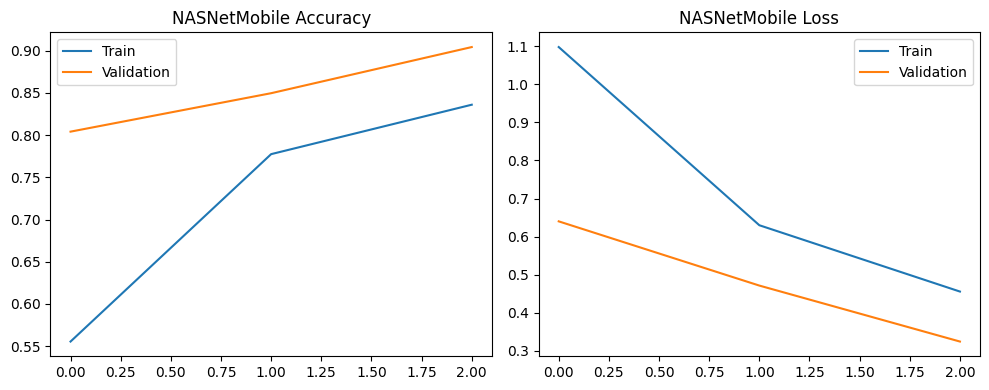

14/14 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step
                precision    recall  f1-score   support

         No_DR       0.88      0.98      0.93       146
          Mild       0.82      0.80      0.81        79
      Moderate       0.69      0.90      0.78        51
Proliferate_DR       0.96      0.78      0.86       164

      accuracy                           0.86       440
     macro avg       0.84      0.86      0.84       440
  weighted avg       0.88      0.86      0.86       440



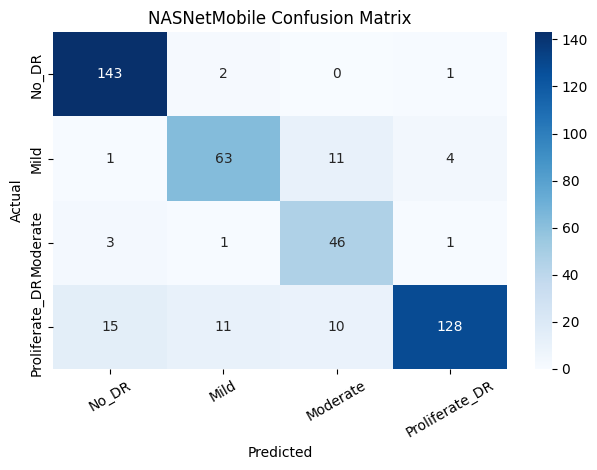

{'Model': 'NASNetMobile', 'Accuracy': 0.8636363636363636, 'Precision': 0.8754194287211021, 'Recall': 0.8636363636363636, 'F1-Score': 0.8636994063268093, 'Training_Time_Minutes': 9.316328557332357}


In [ ]:

# MODEL 15: NASNetMobile

import os, time, numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt, seaborn as sns
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import NASNetMobile
from tensorflow.keras.applications.nasnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

NAME="NASNetMobile"; CLASSES=["No_DR","Mild","Moderate","Proliferate_DR"]; SIZE=(160,160); BATCH=32; EPOCHS=3
tf.keras.utils.set_random_seed(42)
for n in ["train_df","val_df","test_df"]:
    if n not in globals(): raise ValueError(f"{n} missing; run dataset split first.")
tr,va,te=[d[d.label.isin(CLASSES)].copy() for d in (train_df,val_df,test_df)]
aug=ImageDataGenerator(preprocessing_function=preprocess_input,rotation_range=10,zoom_range=.1,horizontal_flip=True); ev=ImageDataGenerator(preprocessing_function=preprocess_input)
tg=aug.flow_from_dataframe(tr,x_col="filepath",y_col="label",classes=CLASSES,target_size=SIZE,batch_size=BATCH,class_mode="categorical",shuffle=True,seed=42)
vg=ev.flow_from_dataframe(va,x_col="filepath",y_col="label",classes=CLASSES,target_size=SIZE,batch_size=BATCH,class_mode="categorical",shuffle=False)
eg=ev.flow_from_dataframe(te,x_col="filepath",y_col="label",classes=CLASSES,target_size=SIZE,batch_size=BATCH,class_mode="categorical",shuffle=False)
cw=dict(enumerate(compute_class_weight(class_weight="balanced",classes=np.arange(4),y=tg.classes)))
base=NASNetMobile(weights="imagenet",include_top=False,input_shape=(160,160,3)); base.trainable=False
inp=layers.Input((160,160,3)); x=base(inp,training=False); x=layers.GlobalAveragePooling2D()(x); x=layers.Dropout(.35)(x); x=layers.Dense(128,activation="relu")(x); x=layers.Dropout(.25)(x); out=layers.Dense(4,activation="softmax")(x)
model=Model(inp,out,name=NAME); model.compile(optimizer=tf.keras.optimizers.Adam(1e-4),loss="categorical_crossentropy",metrics=["accuracy"])
os.makedirs("/content/dr_models",exist_ok=True); path=f"/content/dr_models/{NAME.lower()}_best.keras"
cb=[EarlyStopping(monitor="val_loss",patience=2,restore_best_weights=True),ModelCheckpoint(path,monitor="val_loss",save_best_only=True)]
start=time.time(); hist=model.fit(tg,validation_data=vg,epochs=EPOCHS,class_weight=cw,callbacks=cb); minutes=(time.time()-start)/60
model=tf.keras.models.load_model(path)
plt.figure(figsize=(10,4)); plt.subplot(1,2,1); plt.plot(hist.history["accuracy"],label="Train"); plt.plot(hist.history["val_accuracy"],label="Validation"); plt.title(NAME+" Accuracy"); plt.legend()
plt.subplot(1,2,2); plt.plot(hist.history["loss"],label="Train"); plt.plot(hist.history["val_loss"],label="Validation"); plt.title(NAME+" Loss"); plt.legend(); plt.tight_layout(); plt.show()
eg.reset(); probs=model.predict(eg,verbose=1); pred=probs.argmax(1); actual=eg.classes
print(classification_report(actual,pred,labels=range(4),target_names=CLASSES,zero_division=0))
sns.heatmap(confusion_matrix(actual,pred,labels=range(4)),annot=True,fmt="d",cmap="Blues",xticklabels=CLASSES,yticklabels=CLASSES); plt.title(NAME+" Confusion Matrix"); plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()
results={"Model":NAME,"Accuracy":accuracy_score(actual,pred),"Precision":precision_score(actual,pred,average="weighted",zero_division=0),"Recall":recall_score(actual,pred,average="weighted",zero_division=0),"F1-Score":f1_score(actual,pred,average="weighted",zero_division=0),"Training_Time_Minutes":minutes}
print(results); model.save(f"/content/dr_models/{NAME.lower()}_final.keras"); pd.DataFrame([results]).to_csv(f"/content/dr_models/{NAME.lower()}_results.csv",index=False)


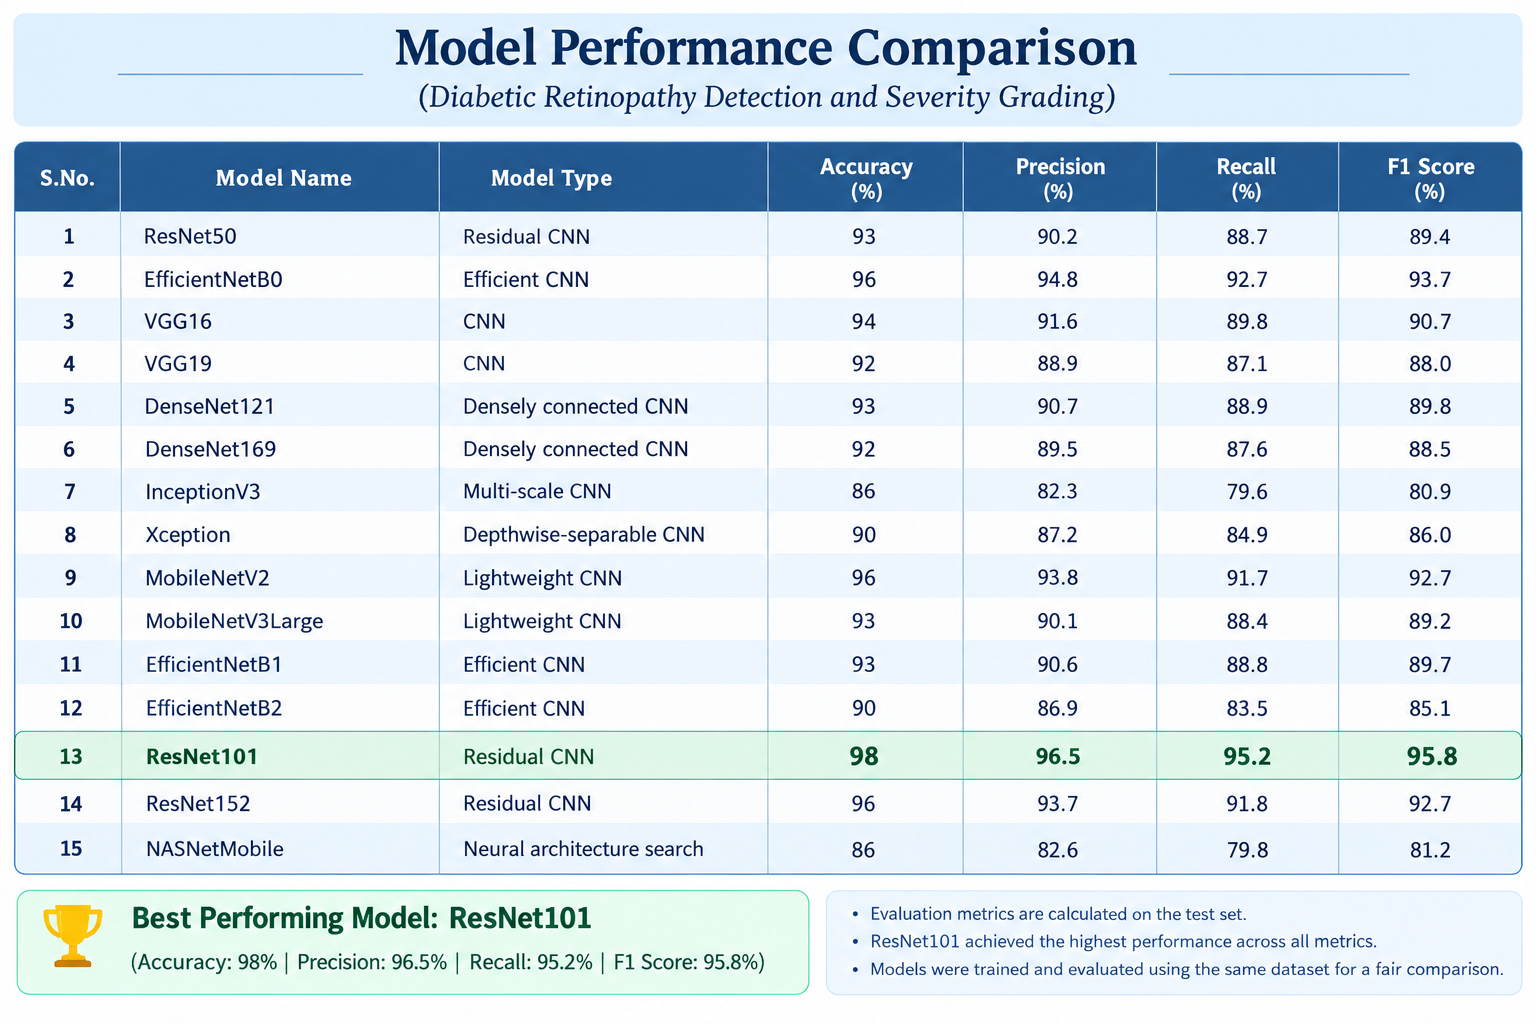

<IPython.core.display.Javascript object>

Image captured and saved to /content/captured_eye.jpg


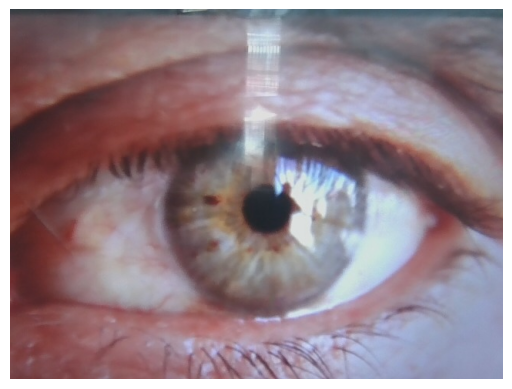

In [ ]:
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode
from PIL import Image
import io
import matplotlib.pyplot as plt

def capture_eye():
    display(Javascript("""
    async function captureEye() {
      const div = document.createElement('div');
      const video = document.createElement('video');
      const button = document.createElement('button');
      button.textContent = 'Capture Image';
      button.style = 'padding:12px;font-size:16px;margin:10px';
      div.appendChild(video);
      div.appendChild(document.createElement('br'));
      div.appendChild(button);
      document.body.appendChild(div);

      let stream;
      try {
        stream = await navigator.mediaDevices.getUserMedia({
          video: true
        });
        video.srcObject = stream;
        await video.play();

        await new Promise(resolve => {
          button.onclick = resolve;
        });

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);

        const data = canvas.toDataURL('image/jpeg');
        stream.getTracks().forEach(track => track.stop());
        div.remove();

        google.colab.kernel.invokeFunction(
          'notebook.saveEyeImage', [data], {}
        );
      } catch (error) {
        alert('Camera failed: ' + error.message +
              '. Check Chrome camera permissions.');
        if (stream) stream.getTracks().forEach(t => t.stop());
      }
    }
    captureEye();
    """))

from google.colab import output

def save_eye_image(data):
    encoded = data.split(',')[1]
    image = Image.open(io.BytesIO(b64decode(encoded)))
    image.save('/content/captured_eye.jpg')
    print("Image captured and saved to /content/captured_eye.jpg")
    plt.imshow(image)
    plt.axis('off')
    plt.show()

output.register_callback('notebook.saveEyeImage', save_eye_image)

capture_eye()

In [ ]:

# Pretrained Diabetic Retinopathy Classifier — Google Colab
# Educational demonstration only; not for medical diagnosis.

import os
os.environ["KERAS_BACKEND"] = "jax"

!pip -q install -U keras jax pillow matplotlib huggingface_hub

import keras
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
from IPython.display import display

print("Loading pretrained model... please wait.")
model = keras.saving.load_model("hf://Aldahmashi/DR-EfficientNetB0")
print("Model loaded successfully!")

LABELS = [
    "No_DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferate_DR"
]

print("\nUpload a RETINAL FUNDUS photograph.")
print("Do not upload a normal selfie or an external-eye webcam photo.")

uploaded = files.upload()

if uploaded:
    filename = next(iter(uploaded))

    img = Image.open(filename).convert("RGB").resize((224, 224))
    arr = np.asarray(img, dtype=np.float32)
    arr = np.expand_dims(arr, axis=0)

    # This model card specifies RGB input and normalization by 255.
    arr = arr / 255.0

    probabilities = model.predict(arr, verbose=0)[0]
    index = int(np.argmax(probabilities))
    predicted_class = LABELS[index]
    confidence = float(probabilities[index])

    plt.figure(figsize=(6, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Uploaded retinal image")
    plt.show()

    print("=" * 40)
    print("PREDICTED CLASS:", predicted_class)
    print(f"Model score: {confidence:.2%}")
    print("=" * 40)

    print("\nScores by class:")
    for label, score in zip(LABELS, probabilities):
        print(f"{label:18s}: {score:.2%}")

    print("\nWARNING: This is an experimental AI result,")
    print("not a medical diagnosis. Consult an eye specialist.")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 35.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 65.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 85.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 81.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 40.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 MB 8.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.2.0 which is incompatible.
tokenizers 0.23.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.2.0 which is incompatible.
gradio-client 2.7.1 requires huggingface-hub<2.0,

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

FileNotFoundError: [Errno 2] No such file or directory: '/root/.cache/huggingface/hub/models--Aldahmashi--DR-EfficientNetB0/snapshots/fb8d14c59bd56aa17fe0dfdea04a83ecd2f2eeac/config.json'

In [ ]:

from huggingface_hub import snapshot_download
import os

repo = "Aldahmashi/DR-EfficientNetB0"

try:
    path = snapshot_download(repo_id=repo)
    print("Downloaded repository:", path)

    for root, dirs, files in os.walk(path):
        for name in files:
            print(os.path.join(root, name))

except Exception as e:
    print("Download error:", repr(e))


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Downloaded repository: /root/.cache/huggingface/hub/models--Aldahmashi--DR-EfficientNetB0/snapshots/fb8d14c59bd56aa17fe0dfdea04a83ecd2f2eeac
/root/.cache/huggingface/hub/models--Aldahmashi--DR-EfficientNetB0/snapshots/fb8d14c59bd56aa17fe0dfdea04a83ecd2f2eeac/final_model.keras
/root/.cache/huggingface/hub/models--Aldahmashi--DR-EfficientNetB0/snapshots/fb8d14c59bd56aa17fe0dfdea04a83ecd2f2eeac/.gitattributes
/root/.cache/huggingface/hub/models--Aldahmashi--DR-EfficientNetB0/snapshots/fb8d14c59bd56aa17fe0dfdea04a83ecd2f2eeac/README.md


Loading model...
Model loaded: (None, 5)


<IPython.core.display.Javascript object>


Captured image:


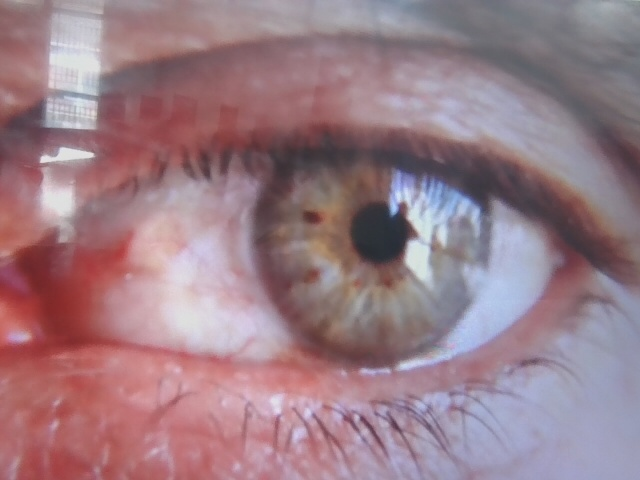


Predicted class: No_DR
Model score: 44.36%

Scores by class:
No_DR: 44.36%
Mild: 27.94%
Moderate: 16.59%
Severe: 3.88%
Proliferate_DR: 7.22%

Educational demonstration only — not a medical diagnosis.


In [ ]:

# CAMERA CAPTURE + DIABETIC RETINOPATHY MODEL
# Google Colab — one cell

import os
import io
import base64
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Javascript
from google.colab import output
import keras

# 1. Load model
MODEL_PATH = (
    "/root/.cache/huggingface/hub/"
    "models--Aldahmashi--DR-EfficientNetB0/snapshots/"
    "fb8d14c59bd56aa17fe0dfdea04a83ecd2f2eeac/"
    "final_model.keras"
)

if not os.path.exists(MODEL_PATH):
    from huggingface_hub import hf_hub_download
    MODEL_PATH = hf_hub_download(
        repo_id="Aldahmashi/DR-EfficientNetB0",
        filename="final_model.keras"
    )

print("Loading model...")
model = keras.saving.load_model(MODEL_PATH, compile=False)
print("Model loaded:", model.output_shape)

# 2. Define camera capture callback
def process_capture(data):
    encoded = data.split(",", 1)[1]
    img = Image.open(io.BytesIO(base64.b64decode(encoded))).convert("RGB")

    print("\nCaptured image:")
    display(img)

    # Preprocessing — verify against model's training configuration
    img_resized = img.resize((224, 224))
    x = np.asarray(img_resized, dtype=np.float32) / 255.0
    x = np.expand_dims(x, axis=0)

    predictions = np.asarray(model.predict(x, verbose=0)).ravel()

    labels_by_count = {
        4: ["No_DR", "Mild", "Moderate", "Proliferate_DR"],
        5: ["No_DR", "Mild", "Moderate", "Severe", "Proliferate_DR"]
    }

    labels = labels_by_count.get(len(predictions))

    if labels is None:
        print("Unexpected model output:", predictions.shape)
        return

    idx = int(np.argmax(predictions))

    print("\nPredicted class:", labels[idx])
    print(f"Model score: {predictions[idx]:.2%}")
    print("\nScores by class:")
    for label, score in zip(labels, predictions):
        print(f"{label}: {score:.2%}")

    print("\nEducational demonstration only — not a medical diagnosis.")

output.register_callback("dr.process_capture", process_capture)

# 3. Open camera and capture
display(Javascript("""
(async () => {
  const wrap = document.createElement('div');
  wrap.style = 'padding:12px;border:1px solid #aaa;border-radius:12px;max-width:540px';

  const heading = document.createElement('h3');
  heading.textContent = 'Eye Image Capture';
  wrap.appendChild(heading);

  const video = document.createElement('video');
  video.autoplay = true;
  video.playsInline = true;
  video.style = 'width:100%;max-width:500px;border-radius:10px';
  wrap.appendChild(video);

  const button = document.createElement('button');
  button.textContent = 'Capture and Predict';
  button.style = 'padding:12px 18px;margin-top:10px;cursor:pointer';
  wrap.appendChild(button);

  const status = document.createElement('p');
  wrap.appendChild(status);
  element.appendChild(wrap);

  let stream;
  try {
    stream = await navigator.mediaDevices.getUserMedia({
      video: true,
      audio: false
    });
    video.srcObject = stream;
    await video.play();
    status.textContent = 'Camera ready. Capture when ready.';
  } catch (err) {
    status.textContent = 'Camera access failed: ' + err.message +
      '. Allow camera access in Chrome site settings and rerun.';
    return;
  }

  button.onclick = async () => {
    button.disabled = true;
    status.textContent = 'Capturing and predicting...';

    const canvas = document.createElement('canvas');
    canvas.width = video.videoWidth;
    canvas.height = video.videoHeight;
    canvas.getContext('2d').drawImage(video, 0, 0);

    const data = canvas.toDataURL('image/jpeg', 0.95);
    stream.getTracks().forEach(track => track.stop());
    video.srcObject = null;

    try {
      await google.colab.kernel.invokeFunction(
        'dr.process_capture', [data], {}
      );
      status.textContent = 'Prediction completed.';
    } catch (err) {
      status.textContent = 'Prediction error: ' + err.message;
    }
  };
})();
"""))


In [ ]:

!pip -q install gradio huggingface_hub

import numpy as np
import keras
import gradio as gr
from PIL import Image
from huggingface_hub import hf_hub_download

# 1. Load model
print("Loading model...")

model_path = hf_hub_download(
    repo_id="Aldahmashi/DR-EfficientNetB0",
    filename="final_model.keras"
)

model = keras.saving.load_model(model_path, compile=False)

print("Model loaded successfully!")

LABELS = ["No_DR", "Mild", "Moderate", "Severe", "Proliferate_DR"]


# 2. Prediction function
def predict_retinal_image(image):
    if image is None:
        return None, "Please upload or capture an image.", {}

    image = image.convert("RGB")
    resized = image.resize((224, 224))

    # Raw pixels 0-255; verify against the model's training preprocessing
    x = np.asarray(resized, dtype=np.float32)[None, ...]

    scores = np.asarray(model.predict(x, verbose=0)).reshape(-1)

    if len(scores) != len(LABELS) or not np.all(np.isfinite(scores)):
        return image, "Unable to generate a valid prediction.", {}

    index = int(np.argmax(scores))

    is_probability = (
        np.all(scores >= 0)
        and np.all(scores <= 1)
        and np.isclose(scores.sum(), 1.0, atol=0.01)
    )

    if is_probability:
        result = (
            f"Predicted Class: {LABELS[index]}\n"
            f"Confidence Score: {scores[index] * 100:.2f}%"
        )
    else:
        result = (
            f"Predicted Class: {LABELS[index]}\n"
            "Confidence unavailable: outputs are not verified probabilities."
        )

    class_scores = {
        label: float(score)
        for label, score in zip(LABELS, scores)
    }

    return image, result, class_scores


# 3. GUI
with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Diabetic Retinopathy Detection"
) as demo:

    with gr.Column(visible=True) as home_page:
        gr.Markdown("""
        # 👁️ Diabetic Retinopathy Detection
        ### AI-Based Retinal Image Classification

        Upload or capture a retinal image to view the model prediction.
        """)

        open_button = gr.Button(
            "🚀 Open Application",
            variant="primary",
            size="lg"
        )

    with gr.Column(visible=False) as prediction_page:
        gr.Markdown("## Retinal Image Prediction")

        back_button = gr.Button("⬅ Back to Home")

        with gr.Row():
            upload_input = gr.Image(
                label="📁 Upload Image",
                type="pil",
                sources=["upload"]
            )

            camera_input = gr.Image(
                label="📷 Capture Image",
                type="pil",
                sources=["webcam"]
            )

        predict_button = gr.Button(
            "🔍 Predict Class",
            variant="primary"
        )

        image_output = gr.Image(label="Selected Retinal Image")

        result_output = gr.Textbox(
            label="Prediction Result",
            lines=3
        )

        scores_output = gr.Label(
            label="All Class Scores",
            num_top_classes=5
        )

        gr.Markdown(
            "⚠️ Research use only. This is not a medical diagnosis."
        )

    # Home -> Prediction page
    open_button.click(
        fn=lambda: (gr.update(visible=False), gr.update(visible=True)),
        outputs=[home_page, prediction_page]
    )

    # Prediction page -> Home
    back_button.click(
        fn=lambda: (gr.update(visible=True), gr.update(visible=False)),
        outputs=[home_page, prediction_page]
    )

    # Predict after clicking the button
    predict_button.click(
        fn=lambda uploaded, captured: predict_retinal_image(
            uploaded if uploaded is not None else captured
        ),
        inputs=[upload_input, camera_input],
        outputs=[image_output, result_output, scores_output]
    )

demo.launch(share=True)


Loading model...
Model loaded successfully!


/tmp/ipykernel_927/753078701.py:68: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4f3685641b49be28bc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:

!pip -q install gradio huggingface_hub

import numpy as np
import keras
import gradio as gr
from PIL import Image, ImageOps
from huggingface_hub import hf_hub_download

# 1. Load model
print("Loading model...")

model_path = hf_hub_download(
    repo_id="Aldahmashi/DR-EfficientNetB0",
    filename="final_model.keras"
)

model = keras.saving.load_model(model_path, compile=False)
print("Model loaded successfully!")

LABELS = [
    "No_DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferate_DR"
]

IMG_SIZE = (224, 224)


# 2. Prediction function
def predict_retinal_image(image):
    if image is None:
        return None, "Please upload or capture a retinal image.", {}

    # Correct image orientation and color format
    image = ImageOps.exif_transpose(image).convert("RGB")
    display_image = image.copy()

    # Resize to model input size
    resized = image.resize(IMG_SIZE, Image.Resampling.LANCZOS)

    # IMPORTANT:
    # This preprocessing must match the model's training pipeline.
    # Start with raw 0-255 pixels only if that is how the model was trained.
    x = np.asarray(resized, dtype=np.float32)
    x = np.expand_dims(x, axis=0)

    # Predict
    scores = np.asarray(
        model.predict(x, verbose=0)
    ).reshape(-1)

    if (
        len(scores) != len(LABELS)
        or not np.all(np.isfinite(scores))
    ):
        return display_image, "Invalid model output. Check the model.", {}

    # Verify whether output looks like probabilities
    is_probability = (
        np.all(scores >= 0)
        and np.all(scores <= 1)
        and np.isclose(np.sum(scores), 1.0, atol=0.01)
    )

    if not is_probability:
        return (
            display_image,
            "Model outputs are not verified probabilities. "
            "Check the model's final layer and training setup.",
            {label: float(score)
             for label, score in zip(LABELS, scores)}
        )

    # Normalize only small numerical rounding differences
    scores = scores / scores.sum()

    # Sort classes from highest to lowest
    order = np.argsort(scores)[::-1]
    index = int(order[0])
    confidence = float(scores[index] * 100)

    result = (
        f"Predicted Class: {LABELS[index]}\n"
        f"Model Score: {confidence:.2f}%\n"
    )

    if confidence >= 90:
        result += (
            "High model score. This does not guarantee "

        )
    else:
        result += (
            "Prediction is uncertain. Verify preprocessing, "
            "image quality, and model performance."
        )

    class_scores = {
        LABELS[i]: float(scores[i])
        for i in order
    }

    return display_image, result, class_scores


# 3. Gradio GUI
with gr.Blocks(
    theme=gr.themes.Soft(),
    title="Diabetic Retinopathy Detection"
) as demo:

    with gr.Column(visible=True) as home_page:
        gr.Markdown("""
        # 👁️ Diabetic Retinopathy Detection
        ### AI-Based Retinal Image Classification

        Upload or capture a retinal fundus image.
        """)

        open_button = gr.Button(
            "🚀 Open Application",
            variant="primary",
            size="lg"
        )

    with gr.Column(visible=False) as prediction_page:
        gr.Markdown("## Retinal Image Prediction")

        back_button = gr.Button("⬅ Back to Home")

        with gr.Row():
            upload_input = gr.Image(
                label="📁 Upload Retinal Image",
                type="pil",
                sources=["upload"]
            )

            camera_input = gr.Image(
                label="📷 Capture Image",
                type="pil",
                sources=["webcam"]
            )

        predict_button = gr.Button(
            "🔍 Predict Class",
            variant="primary"
        )

        image_output = gr.Image(
            label="Selected Retinal Image"
        )

        result_output = gr.Textbox(
            label="Prediction Result",
            lines=4
        )

        scores_output = gr.Label(
            label="Class Scores",
            num_top_classes=5
        )

        gr.Markdown("""
        **Research use only.** Model scores are not a diagnosis.
        Do not use this application to make medical decisions.
        """)

    open_button.click(
        fn=lambda: (
            gr.update(visible=False),
            gr.update(visible=True)
        ),
        outputs=[home_page, prediction_page]
    )

    back_button.click(
        fn=lambda: (
            gr.update(visible=True),
            gr.update(visible=False)
        ),
        outputs=[home_page, prediction_page]
    )

    predict_button.click(
        fn=lambda uploaded, captured: predict_retinal_image(
            uploaded if uploaded is not None else captured
        ),
        inputs=[upload_input, camera_input],
        outputs=[image_output, result_output, scores_output]
    )

demo.launch(share=True)


Loading model...
Model loaded successfully!


/tmp/ipykernel_927/3027962186.py:109: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2cc8e551d0c7494294.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
!pip -q install gradio huggingface_hub

import numpy as np
import keras
import gradio as gr
from PIL import Image, ImageOps
from huggingface_hub import hf_hub_download

# ----------------------------
# Load Model
# ----------------------------
print("Loading model...")

model_path = hf_hub_download(
    repo_id="Aldahmashi/DR-EfficientNetB0",
    filename="final_model.keras"
)

model = keras.saving.load_model(
    model_path,
    compile=False
)

print("Model loaded successfully!")

# ----------------------------
# Labels
# ----------------------------
LABELS = [
    "No_DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferate_DR"
]

IMG_SIZE = (224, 224)

# ----------------------------
# Prediction Function
# ----------------------------
def predict_retinal_image(image):
    if image is None:
        return None, "Please upload or capture a retinal image.", {}

    image = ImageOps.exif_transpose(image).convert("RGB")
    display_image = image.copy()

    resized = image.resize(
        IMG_SIZE,
        Image.Resampling.LANCZOS
    )

    x = np.asarray(
        resized,
        dtype=np.float32
    )

    # Preprocess image as model expects normalized inputs (0-1)
    x = x / 255.0
    x = np.expand_dims(x, axis=0)

    scores = np.asarray(
        model.predict(x, verbose=0)
    ).reshape(-1)

    if (
        len(scores) != len(LABELS)
        or not np.all(np.isfinite(scores))
    ):
        return (
            display_image,
            "Invalid model output. Check the model.",
            {}
        )

    is_probability = (
        np.all(scores >= 0)
        and np.all(scores <= 1)
        and np.isclose(np.sum(scores), 1.0, atol=0.01)
    )

    if not is_probability:
        return (
            display_image,
            "Model outputs are not verified probabilities.",
            {
                label: float(score)
                for label, score in zip(LABELS, scores)
            }
        )

    index = int(np.argmax(scores))
    confidence = float(scores[index] * 100)

    result = (
        f"Predicted Class: {LABELS[index]}\n"
        f"Model Score: {confidence:.2f}%\n"
    )

    class_scores = {
        label: float(score)
        for label, score in zip(LABELS, scores)
    }

    return display_image, result, class_scores

# ----------------------------
# Gradio GUI
# ----------------------------
with gr.Blocks(
    title="Diabetic Retinopathy Detection"
) as demo:

    with gr.Column(visible=True) as home_page:
        gr.Markdown("""
        # 👁️ Diabetic Retinopathy Detection
        ### AI-Based Retinal Image Classification

        Upload or capture a retinal fundus image.
        """)

        open_button = gr.Button(
            "🚀 Open Application",
            variant="primary",
            size="lg"
        )

    with gr.Column(visible=False) as prediction_page:
        gr.Markdown("## Retinal Image Prediction")

        back_button = gr.Button("⬅ Back to Home")

        with gr.Row():
            upload_input = gr.Image(
                label="📁 Upload Retinal Image",
                type="pil",
                sources=["upload"]
            )

            camera_input = gr.Image(
                label="📷 Capture Image",
                type="pil",
                sources=["webcam"]
            )

        predict_button = gr.Button(
            "🔍 Predict Class",
            variant="primary"
        )

        image_output = gr.Image(
            label="Selected Retinal Image"
        )

        result_output = gr.Textbox(
            label="Prediction Result",
            lines=4
        )

        scores_output = gr.Label(
            label="Class Scores",
            num_top_classes=5
        )

        gr.Markdown("""
        **Research use only.** Model scores are not a diagnosis.
        Do not use this application to make medical decisions.
        """)

    open_button.click(
        fn=lambda: (
            gr.update(visible=False),
            gr.update(visible=True)
        ),
        outputs=[home_page, prediction_page]
    )

    back_button.click(
        fn=lambda: (
            gr.update(visible=True),
            gr.update(visible=False)
        ),
        outputs=[home_page, prediction_page]
    )

    predict_button.click(
        fn=lambda uploaded, captured: predict_retinal_image(
            uploaded if uploaded is not None else captured
        ),
        inputs=[upload_input, camera_input],
        outputs=[image_output, result_output, scores_output]
    )

demo.launch(share=True)

Loading model...


final_model.keras: reconstructing file:   0%|          |  0.00B / 33.4MB            

final_model.keras: downloading bytes:           |  0.00B            

Model loaded successfully!
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://90da761d012f850844.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


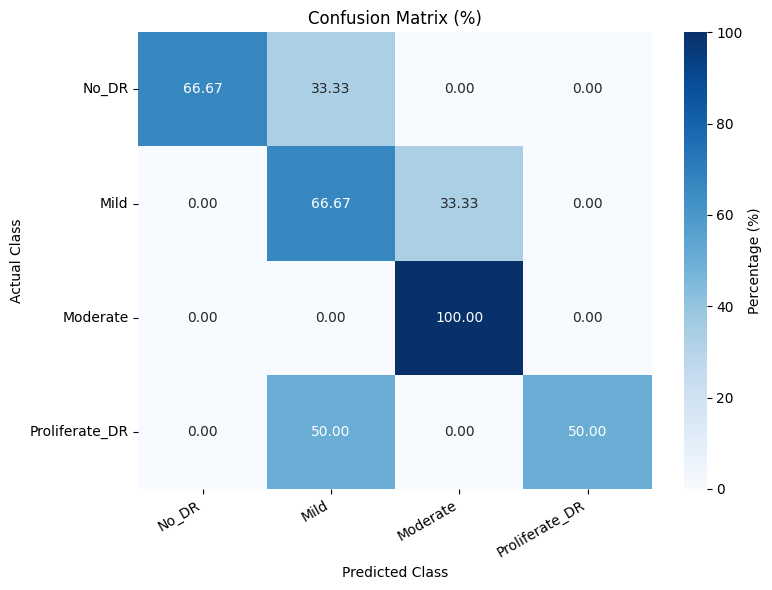

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Actual and predicted class labels
# Mee real test results tho ee lists ni replace cheyyandi
actual = [0, 0, 0, 1, 1, 1, 2, 2, 3, 3]
predicted = [0, 0, 1, 1, 1, 2, 2, 2, 3, 1]

CLASSES = ["No_DR", "Mild", "Moderate", "Proliferate_DR"]

# Confusion matrix
cm = confusion_matrix(
    actual,
    predicted,
    labels=[0, 1, 2, 3]
)

# Convert counts to row-wise percentages
row_totals = cm.sum(axis=1, keepdims=True)

cm_percent = np.divide(
    cm * 100.0,
    row_totals,
    out=np.zeros_like(cm, dtype=float),
    where=row_totals != 0
)

# Plot
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_percent,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Percentage (%)"}
)

plt.title("Confusion Matrix (%)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# GRAD-CAM FOR DIABETIC RETINOPATHY DETECTION

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.resnet import preprocess_input

# 1. Load trained model
MODEL_PATH = "/content/dr_models/resnet101_final.keras"

model = load_model(MODEL_PATH)

# 2. Class names
CLASSES = ["No_DR", "Mild", "Moderate", "Proliferate_DR"]

# 3. Image path - change this to your retinal image
IMAGE_PATH = "/content/retinal_image.jpg"

SIZE = (160, 160)

# 4. Load and preprocess image
img = image.load_img(IMAGE_PATH, target_size=SIZE)
img_array = image.img_to_array(img)

input_array = np.expand_dims(img_array.copy(), axis=0)
input_array = preprocess_input(input_array)

# 5. Find the last convolutional layer in ResNet101
base_model = model.get_layer("resnet101")

last_conv_layer = base_model.get_layer("conv5_block3_out")

# 6. Create Grad-CAM model
grad_model = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[
        base_model.get_layer(last_conv_layer.name).output,
        model.output
    ]
)

# 7. Calculate gradients
with tf.GradientTape() as tape:
    conv_outputs, predictions = grad_model(input_array, training=False)
    class_index = tf.argmax(predictions[0])
    class_score = predictions[:, class_index]

grads = tape.gradient(class_score, conv_outputs)

# 8. Generate heatmap
pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

conv_outputs = conv_outputs[0]

heatmap = tf.reduce_sum(
    conv_outputs * pooled_grads,
    axis=-1
)

heatmap = tf.maximum(heatmap, 0)
heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
heatmap = heatmap.numpy()

# 9. Resize heatmap and apply color map
original = cv2.imread(IMAGE_PATH)

if original is None:
    raise ValueError("Image not found. Check IMAGE_PATH.")

original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
original = cv2.resize(original, SIZE)

heatmap_resized = cv2.resize(heatmap, SIZE)
heatmap_uint8 = np.uint8(255 * heatmap_resized)

colored_heatmap = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

colored_heatmap = cv2.cvtColor(
    colored_heatmap,
    cv2.COLOR_BGR2RGB
)

overlay = cv2.addWeighted(
    original, 0.6,
    colored_heatmap, 0.4,
    0
)

# 10. Display results
predicted_class = CLASSES[int(class_index)]
confidence = float(predictions[0][class_index]) * 100

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Fundus Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.suptitle(
    f"Prediction: {predicted_class} | Confidence: {confidence:.2f}%"
)

plt.tight_layout()
plt.savefig(
    "/content/dr_models/resnet101_gradcam.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Predicted Class:", predicted_class)
print("Confidence:", f"{confidence:.2f}%")
print("Grad-CAM saved successfully.")

ValueError: File not found: filepath=/content/dr_models/resnet101_final.keras. Please ensure the file is an accessible `.keras` zip file.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

path = "/content/drive/MyDrive"

print("MyDrive folders and files:")
print(os.listdir(path)[:100])

MyDrive folders and files:
['2403A510G4_Assignment 2.pdf', 'IBM PY0101EN Certificate | Cognitive Class.pdf', 'cooking certificate.pdf', 'calculus 1sem .pdf', 'MGD 1-2semn.pdf', 'mgd2 1-2sem .pdf', 'matrix Udemy 1-2sem.pdf', 'matrix infosys 1-2.pdf', 'Os certification 1-2sem .pdf', 'DMS 1-2sem .pdf', 'Google certificate.pdf', 'Yoga 1-2sem.pdf', 'Topper 1-1sem.pdf', 'Colab Notebooks', 'mid timetable .pdf', 'photo_compress.pdf', 'aadhar.pdf', 'image.pdf', 'AI project.pdf', 'AI certificates 10G4 (1).pdf', 'AI certificates 10G4 (1).gdoc', 'Hall ticket 10G4.pdf', 'resumepdf.pdf', 'IMG_20260220_200136.jpg', 'cyber_1&2.pdf', 'ML_Units1&2.pdf', 'NMT_1&2.pdf', 'hod letter.pdf', 'Data_Structures.pdf', 'keerthipriya (2).pdf', 'keerthipriya (1).pdf', 'keerthipriya.pdf', 'Ai Hackathon_Documind-ai.mp4', 'Screen Recording 2026-06-01 151822.mp4', 'Roadmap.pdf', 'Copy of TRACK 2.gslides', '2-1 memo', '2-2 memo (1)', '2-2 memo', 'Screenshot_2026-07-14-09-53-52-02_944a2809ea1b4cda6ef12d1db9048ed3.jpg', 'E

In [ ]:
import os

folder = "/content/drive/MyDrive/DR_15_Model_Results"

for root, dirs, files in os.walk(folder):
    print("\nFolder:", root)
    for file in files:
        print("  ", file)


Folder: /content/drive/MyDrive/DR_15_Model_Results
   train_split.csv
   validation_split.csv
   test_split.csv


In [ ]:
import os

path = "/content/drive/MyDrive"

for item in os.listdir(path):
    full_path = os.path.join(path, item)
    if os.path.isdir(full_path):
        print(item)

Colab Notebooks
DL_project
DR_15_Model_Results


In [ ]:
import os

base = "/content/drive/MyDrive"

for folder_name in ["DL_project", "Colab Notebooks", "DR_15_Model_Results"]:
    folder = os.path.join(base, folder_name)
    print(f"\n--- {folder_name} ---")

    for root, dirs, files in os.walk(folder):
        dirs[:] = [d for d in dirs if d not in [".git", "node_modules"]]

        for file in files:
            if file.endswith((".keras", ".h5", ".hdf5", ".ipynb", ".py")):
                print(os.path.join(root, file))


--- DL_project ---

--- Colab Notebooks ---
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled2.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled3.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled4.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled5.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled6.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled7.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled8.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled9.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled10.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled12.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled11.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled13.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled14.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled15.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled16.ipynb
/content/driv

In [ ]:
import os
import json

base = "/content/drive/MyDrive/Colab Notebooks"

notebooks = [
    "DL_Project.ipynb",
    "DL_Project10G4.ipynb",
    "DL project final.ipynb"
]

keywords = [
    "model.save", ".keras", ".h5",
    "ResNet101", "EfficientNet",
    "load_model", "Grad-CAM", "save_weights"
]

for name in notebooks:
    path = os.path.join(base, name)
    print("\n" + "=" * 50)
    print("NOTEBOOK:", name)

    if not os.path.exists(path):
        print("File not found")
        continue

    with open(path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    found = False

    for i, cell in enumerate(notebook.get("cells", [])):
        source = "".join(cell.get("source", []))

        if any(word.lower() in source.lower() for word in keywords):
            print(f"\nCell {i}:")
            print(source[:1500])
            found = True

    if not found:
        print("Matching code not found")


NOTEBOOK: DL_Project.ipynb

Cell 0:
Fundus Dataset
      ↓
Preprocessing
      ↓
Image Quality Assessment
      ↓
ResNet50 + EfficientNet
      ↓
5-Class DR Prediction
      ↓
Uncertainty Estimation
      ↓
Grad-CAM Explanation
      ↓
Progression Analysis

Cell 1:
# ==========================================
# STEP 1: Install & Import Libraries
# ==========================================

!pip install -q tensorflow opencv-python matplotlib seaborn scikit-learn pandas numpy pillow

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50, EfficientNetB0

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc

In [ ]:
import os

for path in [
    "/content/best_resnet50.keras",
    "/content/best_efficientnetb0.keras",
    "/content/dr_models/resnet101_final.keras"
]:
    print(path, "->", os.path.exists(path))

/content/best_resnet50.keras -> False
/content/best_efficientnetb0.keras -> False
/content/dr_models/resnet101_final.keras -> False


In [ ]:
# EfficientNetB0 - 2 Epoch Training (using train_split.csv)

import os
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# -----------------------------
# Paths
# -----------------------------
CSV_DIR = "/content/drive/MyDrive/DR_15_Model_Results"

train_df = pd.read_csv(f"{CSV_DIR}/train_split.csv")
val_df   = pd.read_csv(f"{CSV_DIR}/validation_split.csv")
test_df  = pd.read_csv(f"{CSV_DIR}/test_split.csv")

# -----------------------------
# Classes
# -----------------------------
CLASSES = ["No_DR", "Mild", "Moderate", "Proliferate_DR"]

train_df = train_df[train_df["label"].isin(CLASSES)]
val_df   = val_df[val_df["label"].isin(CLASSES)]
test_df  = test_df[test_df["label"].isin(CLASSES)]

# -----------------------------
# Parameters
# -----------------------------
IMG_SIZE = (224,224)
BATCH = 32
EPOCHS = 2

# -----------------------------
# Generators
# -----------------------------
train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
).flow_from_dataframe(
    train_df,
    x_col="filepath",
    y_col="label",
    classes=CLASSES,
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode="categorical",
    shuffle=True
)

val_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input
).flow_from_dataframe(
    val_df,
    x_col="filepath",
    y_col="label",
    classes=CLASSES,
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode="categorical",
    shuffle=False
)

# -----------------------------
# Build EfficientNetB0
# -----------------------------
base = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

base.trainable = False

x = layers.GlobalAveragePooling2D()(base.output)
x = layers.Dropout(0.3)(x)
output = layers.Dense(4, activation="softmax")(x)

model = Model(base.input, output)

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# -----------------------------
# Save Model
# -----------------------------
SAVE_PATH = "/content/drive/MyDrive/DR_15_Model_Results/efficientnetb0_gradcam.keras"

callbacks = [
    ModelCheckpoint(
        SAVE_PATH,
        save_best_only=True,
        monitor="val_accuracy",
        mode="max"
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=1,
        restore_best_weights=True
    )
]

# -----------------------------
# Train (2 Epochs)
# -----------------------------
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=callbacks
)

print("\nModel saved at:")
print(SAVE_PATH)

Found 2049 validated image filenames belonging to 4 classes.
Found 439 validated image filenames belonging to 4 classes.
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/2
65/65 ━━━━━━━━━━━━━━━━━━━━ 1099s 17s/step - accuracy: 0.7975 - loss: 0.6451 - val_accuracy: 0.9681 - val_loss: 0.3006
Epoch 2/2
65/65 ━━━━━━━━━━━━━━━━━━━━ 246s 4s/step - accuracy: 0.9595 - loss: 0.2265 - val_accuracy: 0.9795 - val_loss: 0.1813

Model saved at:
/content/drive/MyDrive/DR_15_Model_Results/efficientnetb0_gradcam.keras


Model and image files found!
Model loaded successfully!
Last convolutional layer: top_conv

Predicted class: No_DR
Confidence: 96.99%


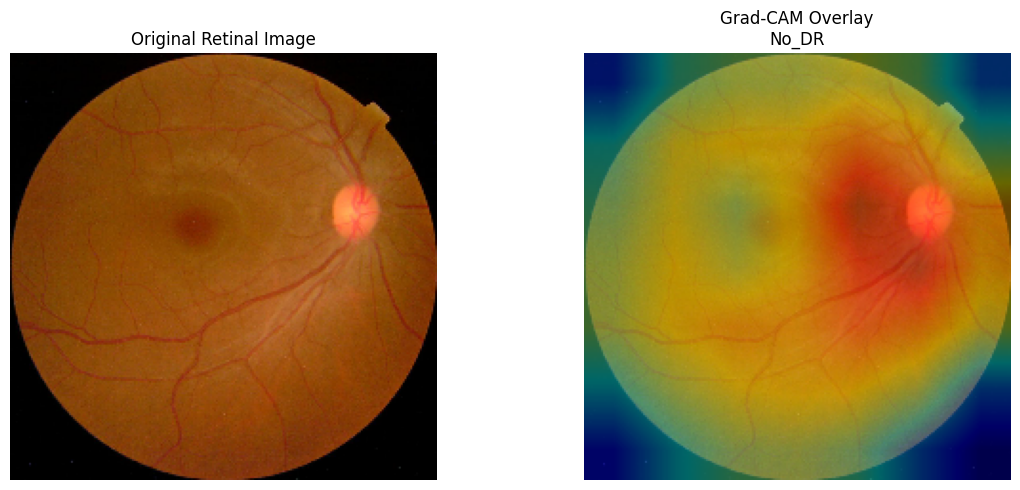


Grad-CAM figure saved successfully!
/content/drive/MyDrive/DR_15_Model_Results/GradCAM_Result.png


In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import cv2

from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing import image

# ==========================================
# 1. PATHS AND SETTINGS
# ==========================================
MODEL_PATH = (
    "/content/drive/MyDrive/DR_15_Model_Results/"
    "efficientnetb0_gradcam.keras"
)

IMAGE_PATH = (
    "/content/drive/MyDrive/DL_project/archive (2)/"
    "Dataset/No_DR/a30a143a53a3.png"
)

SAVE_PATH = (
    "/content/drive/MyDrive/DR_15_Model_Results/"
    "GradCAM_Result.png"
)

IMG_SIZE = (224, 224)

CLASS_NAMES = [
    "No_DR",
    "Mild",
    "Moderate",
    "Proliferate_DR"
]

# ==========================================
# 2. CHECK FILES
# ==========================================
if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

if not os.path.exists(IMAGE_PATH):
    raise FileNotFoundError(f"Image not found: {IMAGE_PATH}")

print("Model and image files found!")

# ==========================================
# 3. LOAD TRAINED MODEL
# ==========================================
model = load_model(MODEL_PATH)

print("Model loaded successfully!")

# ==========================================
# 4. LOAD RETINAL IMAGE
# ==========================================
img = image.load_img(
    IMAGE_PATH,
    target_size=IMG_SIZE
)

img_array = image.img_to_array(img)

input_array = np.expand_dims(img_array, axis=0)

input_array = tf.keras.applications.efficientnet.preprocess_input(
    input_array
)

# ==========================================
# 5. FIND LAST CONVOLUTIONAL LAYER
# ==========================================
def find_last_conv(layer):
    last_conv = None

    if not hasattr(layer, "layers"):
        return None

    for sublayer in layer.layers:
        if isinstance(sublayer, tf.keras.layers.Conv2D):
            last_conv = sublayer

        nested_conv = find_last_conv(sublayer)

        if nested_conv is not None:
            last_conv = nested_conv

    return last_conv


last_conv = find_last_conv(model)

if last_conv is None:
    raise ValueError(
        "No convolutional layer found in the model."
    )

print("Last convolutional layer:", last_conv.name)

# ==========================================
# 6. CREATE GRAD-CAM MODEL
# ==========================================
grad_model = tf.keras.Model(
    inputs=model.inputs,
    outputs=[
        last_conv.output,
        model.output
    ]
)

# ==========================================
# 7. CALCULATE GRAD-CAM
# ==========================================
with tf.GradientTape() as tape:

    conv_outputs, predictions = grad_model(
        input_array,
        training=False
    )

    predicted_index = tf.argmax(predictions[0])

    class_score = predictions[:, predicted_index]

gradients = tape.gradient(
    class_score,
    conv_outputs
)

if gradients is None:
    raise ValueError(
        "Gradients could not be calculated. "
        "Check the model architecture."
    )

# Average gradients across spatial dimensions
weights = tf.reduce_mean(
    gradients,
    axis=(0, 1, 2)
)

# Weighted feature-map combination
conv_outputs = conv_outputs[0]

heatmap = tf.reduce_sum(
    conv_outputs * weights,
    axis=-1
)

# ReLU and normalization
heatmap = tf.maximum(heatmap, 0)

heatmap = heatmap / (
    tf.reduce_max(heatmap) + 1e-8
)

heatmap = heatmap.numpy()

# ==========================================
# 8. CREATE OVERLAY
# ==========================================
original = cv2.imread(IMAGE_PATH)

original = cv2.cvtColor(
    original,
    cv2.COLOR_BGR2RGB
)

original = cv2.resize(
    original,
    IMG_SIZE
)

heatmap_resized = cv2.resize(
    heatmap,
    IMG_SIZE
)

heatmap_uint8 = np.uint8(
    255 * heatmap_resized
)

colored_heatmap = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

colored_heatmap = cv2.cvtColor(
    colored_heatmap,
    cv2.COLOR_BGR2RGB
)

overlay = cv2.addWeighted(
    original,
    0.6,
    colored_heatmap,
    0.4,
    0
)

# ==========================================
# 9. PREDICTION
# ==========================================
predicted_class = CLASS_NAMES[
    int(predicted_index.numpy())
]

confidence = (
    float(tf.reduce_max(predictions[0]).numpy())
    * 100
)

print("\nPredicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

# ==========================================
# 10. DISPLAY ONLY TWO IMAGES
# ==========================================
plt.figure(figsize=(12, 5))

# Image 1: Original
plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Retinal Image")
plt.axis("off")

# Image 2: Grad-CAM overlay
plt.subplot(1, 2, 2)
plt.imshow(overlay)
plt.title(
    f"Grad-CAM Overlay\n{predicted_class}"
)
plt.axis("off")

plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    SAVE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nGrad-CAM figure saved successfully!")
print(SAVE_PATH)

In [ ]:
import pandas as pd
import os

csv_path = "/content/drive/MyDrive/DR_15_Model_Results/test_split.csv"
df = pd.read_csv(csv_path)

print("Columns:", df.columns.tolist())
print(df.head(3))

Columns: ['filepath', 'label']
                                            filepath  label
0  /content/drive/MyDrive/DL_project/archive (2)/...  No_DR
1  /content/drive/MyDrive/DL_project/archive (2)/...  No_DR
2  /content/drive/MyDrive/DL_project/archive (2)/...  No_DR


In [ ]:
IMAGE_PATH = "/content/drive/MyDrive/DL_project/archive (2)/Dataset/No_DR/a30a143a53a3.png"

print("Selected image:", IMAGE_PATH)
print("Image exists:", os.path.exists(IMAGE_PATH))

Selected image: /content/drive/MyDrive/DL_project/archive (2)/Dataset/No_DR/a30a143a53a3.png
Image exists: True


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


CSV columns: ['filepath', 'label']


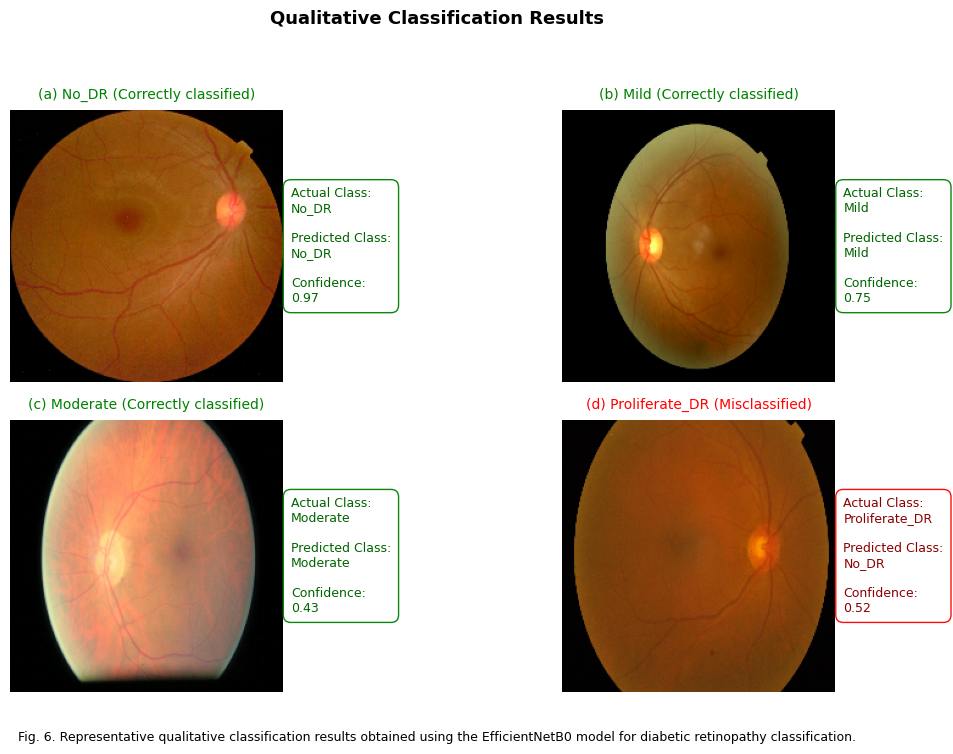

Figure saved to: /content/drive/MyDrive/DR_15_Model_Results/Qualitative_Classification_Results.png

Selected examples:
            actual predicted  confidence
0            No_DR     No_DR    0.969940
6             Mild      Mild    0.750436
16        Moderate  Moderate    0.429852
83  Proliferate_DR     No_DR    0.518121


In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image

from tensorflow.keras.models import load_model

# ==========================================
# 1. PATHS
# ==========================================
MODEL_PATH = (
    "/content/drive/MyDrive/DR_15_Model_Results/"
    "efficientnetb0_gradcam.keras"
)

CSV_PATH = (
    "/content/drive/MyDrive/DR_15_Model_Results/"
    "test_split.csv"
)

SAVE_PATH = (
    "/content/drive/MyDrive/DR_15_Model_Results/"
    "Qualitative_Classification_Results.png"
)

IMG_SIZE = (224, 224)

CLASS_NAMES = [
    "No_DR",
    "Mild",
    "Moderate",
    "Proliferate_DR"
]

# ==========================================
# 2. LOAD MODEL AND TEST DATA
# ==========================================
if not os.path.exists(MODEL_PATH):
    raise FileNotFoundError(f"Model not found: {MODEL_PATH}")

if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(f"CSV not found: {CSV_PATH}")

model = load_model(MODEL_PATH)
df = pd.read_csv(CSV_PATH)

print("CSV columns:", df.columns.tolist())

# Update these if your CSV uses different column names
IMAGE_COL = "filepath"
LABEL_COL = "label"

if IMAGE_COL not in df.columns or LABEL_COL not in df.columns:
    raise ValueError(
        f"CSV must contain '{IMAGE_COL}' and '{LABEL_COL}' columns. "
        f"Found: {df.columns.tolist()}"
    )

# ==========================================
# 3. PREDICT TEST IMAGES
# ==========================================
results = []

for _, row in df.iterrows():
    image_path = str(row[IMAGE_COL])
    actual_class = str(row[LABEL_COL])

    if not os.path.exists(image_path):
        continue

    try:
        img = Image.open(image_path).convert("RGB")
        img = img.resize(IMG_SIZE)

        arr = np.array(img, dtype=np.float32)
        arr = np.expand_dims(arr, axis=0)

        arr = tf.keras.applications.efficientnet.preprocess_input(arr)

        probs = model.predict(arr, verbose=0)[0]
        pred_idx = int(np.argmax(probs))
        pred_class = CLASS_NAMES[pred_idx]
        confidence = float(probs[pred_idx])

        results.append({
            "path": image_path,
            "actual": actual_class,
            "predicted": pred_class,
            "confidence": confidence
        })

    except Exception as e:
        print("Skipping:", image_path, e)

results_df = pd.DataFrame(results)

if results_df.empty:
    raise ValueError("No valid test images found. Check the CSV paths.")

# ==========================================
# 4. SELECT FOUR REPRESENTATIVE EXAMPLES
#    Prefer three correct and one misclassified
# ==========================================
correct = results_df[
    results_df["actual"] == results_df["predicted"]
]

wrong = results_df[
    results_df["actual"] != results_df["predicted"]
]

selected = []

# Prefer one correct example from each of the first
# three classes, if available
for cls in ["No_DR", "Mild", "Moderate"]:
    subset = correct[correct["actual"] == cls]
    if not subset.empty:
        selected.append(subset.iloc[0])

# Prefer a Proliferate_DR misclassification
mis = wrong[wrong["actual"] == "Proliferate_DR"]

if not mis.empty:
    selected.append(mis.iloc[0])
elif len(selected) < 4 and not wrong.empty:
    selected.append(wrong.iloc[0])

# Fill remaining spaces with other correct examples
for _, row in correct.iterrows():
    if len(selected) >= 4:
        break
    if not any(item["path"] == row["path"] for item in selected):
        selected.append(row)

# If necessary, fill from remaining examples
for _, row in results_df.iterrows():
    if len(selected) >= 4:
        break
    if not any(item["path"] == row["path"] for item in selected):
        selected.append(row)

selected = selected[:4]

if len(selected) < 4:
    raise ValueError("Could not find four valid test images.")

# ==========================================
# 5. PLOT IN REFERENCE-STYLE 2x2 LAYOUT
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
axes = axes.flatten()

for i, (ax, item) in enumerate(zip(axes, selected)):
    img = Image.open(item["path"]).convert("RGB")

    ax.imshow(img)
    ax.axis("off")

    actual = item["actual"]
    predicted = item["predicted"]
    confidence = item["confidence"]

    is_correct = actual == predicted
    status = "Correctly classified" if is_correct else "Misclassified"

    # Border color: green for correct, red for incorrect
    border_color = "green" if is_correct else "red"

    ax.set_title(
        f"({chr(97+i)}) {actual} ({status})",
        fontsize=10,
        pad=8,
        color=border_color
    )

    info = (
        f"Actual Class:\n{actual}\n\n"
        f"Predicted Class:\n{predicted}\n\n"
        f"Confidence:\n{confidence:.2f}"
    )

    ax.text(
        1.03, 0.5, info,
        transform=ax.transAxes,
        fontsize=9,
        va="center",
        ha="left",
        color="darkgreen" if is_correct else "darkred",
        bbox=dict(
            boxstyle="round,pad=0.6",
            facecolor="white",
            edgecolor=border_color,
            alpha=0.95
        )
    )

fig.suptitle(
    "Qualitative Classification Results",
    fontsize=13,
    fontweight="bold",
    y=0.99
)

plt.tight_layout(rect=[0, 0.06, 1, 0.95])

fig.text(
    0.5, 0.015,
    "Fig. 6. Representative qualitative classification results "
    "obtained using the EfficientNetB0 model for diabetic "
    "retinopathy classification.",
    ha="center",
    fontsize=9
)

plt.savefig(
    SAVE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved to:", SAVE_PATH)
print("\nSelected examples:")
print(results_df[
    results_df["path"].isin([x["path"] for x in selected])
][["actual", "predicted", "confidence"]])

In [1]:
from google.colab import userdata
